In [1]:
.libPaths("~/R/x86_64-pc-linux-gnu-library/4.4/")

library(Seurat)
library(SeuratDisk)
library(patchwork)
library(harmony)
library(reshape2)
library(RColorBrewer)
library(dplyr)
library(readr)
library(tidyverse)
library(Matrix)
library(Seurat)
library(ggplot2)
library(cowplot)
library(celldex)
library(SingleR)
library(data.table)
library(scGate)
library(ggpubr)
library(scCustomize)
library(GEOquery)

ggtheme <- function() {
  theme(
    axis.text = element_text(size = 20),
    axis.title = element_text(size = 20),
    text = element_text(size = 20, colour = "black"),
    legend.text = element_text(size = 20),
    legend.key.size =  unit(10, units = "points")
    
  )
}


Loading required package: SeuratObject

Loading required package: sp

‘SeuratObject’ was built with package ‘Matrix’ 1.7.4 but the current
version is 1.7.6; it is recomended that you reinstall ‘SeuratObject’ as
the ABI for ‘Matrix’ may have changed


Attaching package: ‘SeuratObject’


The following objects are masked from ‘package:base’:

    intersect, t


Registered S3 method overwritten by 'SeuratDisk':
  method            from  
  as.sparse.H5Group Seurat

Loading required package: Rcpp


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ forcats   1.0.0     ✔ stringr   1.6.0
✔ ggplot2   4.0.1     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.2.0     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts()

# PREDICT 3p

In [1]:
predict_3p  <- readRDS("data/old_predict/paper_final.rds")

In [6]:
predict_3p@meta.data  <- predict_3p@meta.data  %>% 
mutate(Combined2 = if_else(grepl(combinedMajorTypes, pattern = "Plsma"), "PlasmaCells",combinedMajorTypes))

In [ ]:
predict_3p$Combined2  %>% table

In [7]:
predict_3p$combinedMajorTypes  %>% table

.
            B            EC         Endth         Fibro         Mstcl 
        48292         22960          9031          4647          3425 
      Myeloid Plsma.IGA.IGK Plsma.IGA.IGL     Plsma.IGG     Plsma.IGM 
        15678         13880          5920          4863           914 
            T 
        67671 

In [8]:
cl8_barcodes  <- read_csv("tables/predict3p_tcells_cl8_barcodes.csv")

New names:
• `` -> `...1`
Rows: 1643 Columns: 2
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (1): x
dbl (1): ...1

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



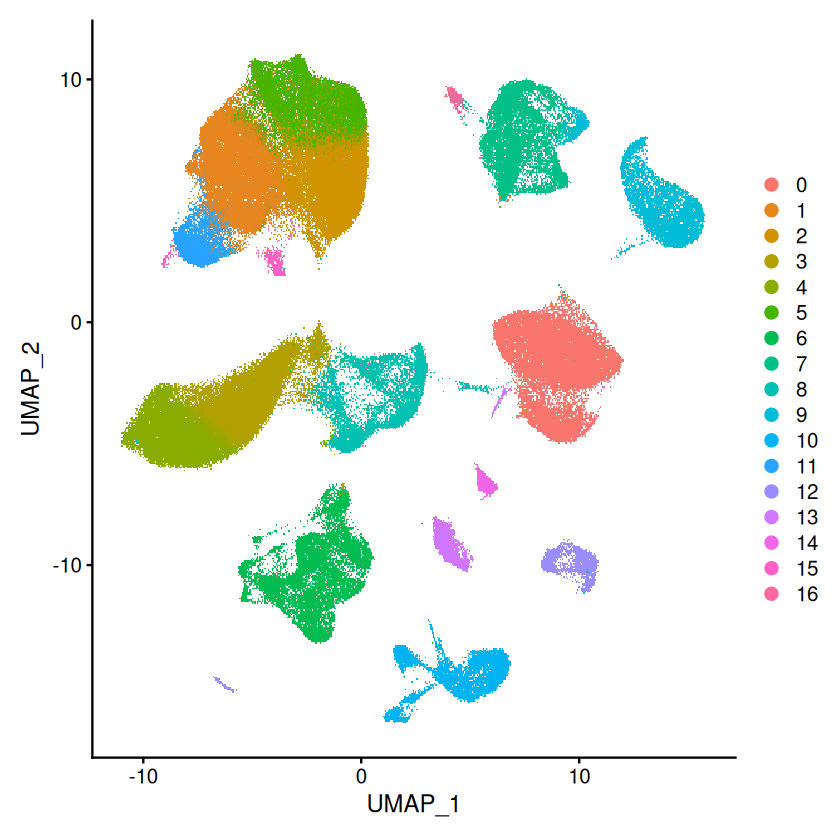

In [9]:
DimPlot(predict_3p)

In [10]:
cl8_barcodes$x %in% colnames(predict_3p)  %>% table

.
TRUE 
1643 

In [11]:
predict_3p$cd4_ctl  <- colnames(predict_3p) %in% cl8_barcodes$x

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



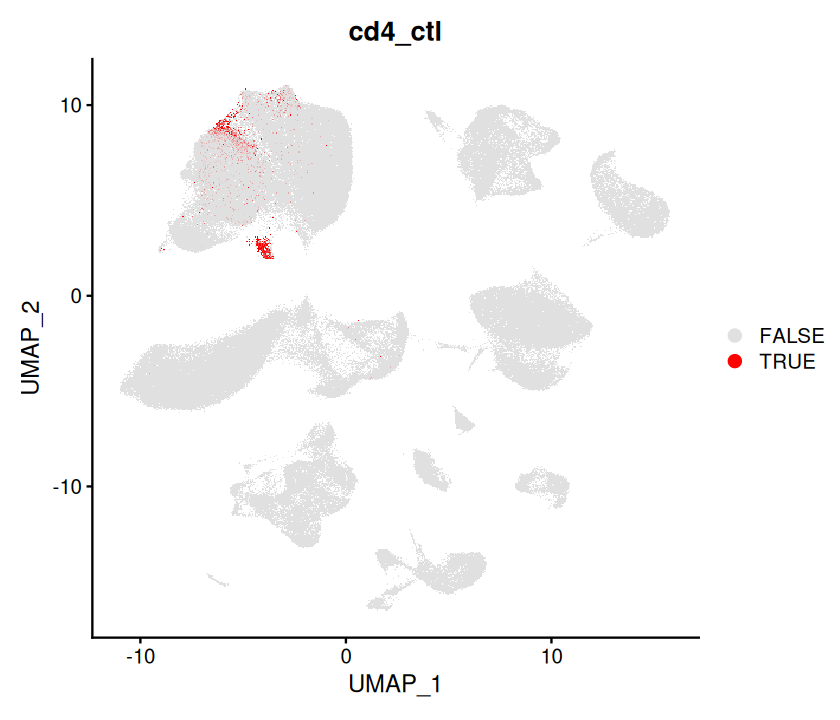

In [12]:
options(repr.plot.width  = 7, repr.plot.height = 6)
DimPlot(predict_3p, group.by = "cd4_ctl", cols = c("grey88","red"), order = "TRUE")

In [21]:
organism <- "human"

if(organism == "human"){
  lr_network <- readRDS(url("https://zenodo.org/record/7074291/files/lr_network_human_21122021.rds"))
  ligand_target_matrix <- readRDS(url("https://zenodo.org/record/7074291/files/ligand_target_matrix_nsga2r_final.rds"))
  weighted_networks <- readRDS(url("https://zenodo.org/record/7074291/files/weighted_networks_nsga2r_final.rds"))
} else if(organism == "mouse"){
  lr_network <- readRDS(url("https://zenodo.org/record/7074291/files/lr_network_mouse_21122021.rds"))
  ligand_target_matrix <- readRDS(url("https://zenodo.org/record/7074291/files/ligand_target_matrix_nsga2r_final_mouse.rds"))
  weighted_networks <- readRDS(url("https://zenodo.org/record/7074291/files/weighted_networks_nsga2r_final_mouse.rds"))

}

lr_network <- lr_network %>% distinct(from, to)
head(lr_network)

from,to
<chr>,<chr>
A2M,MMP2
A2M,MMP9
A2M,LRP1
A2M,KLK3
AANAT,MTNR1A
AANAT,MTNR1B


In [14]:
predict_3p$combinedMajorTypes %>% table

.
            B            EC         Endth         Fibro         Mstcl 
        48292         22960          9031          4647          3425 
      Myeloid Plsma.IGA.IGK Plsma.IGA.IGL     Plsma.IGG     Plsma.IGM 
        15678         13880          5920          4863           914 
            T 
        67671 

In [15]:
is.na(predict_3p$curatedname) %>% table

.
 FALSE 
197281 

In [16]:
predict_3p$curatedname  %>% head

p011_T0D_ILE_LPS_3p_AAACCTGAGAGTCTGG-1 p011_T0D_ILE_LPS_3p_AAACCTGAGGCAAAGA-1 
                  "CD.T.MT-CO2.PTGER4"             "CD.Plsma/IgA.IGLC3.IGLC2" 
p011_T0D_ILE_LPS_3p_AAACCTGAGTGGACGT-1 p011_T0D_ILE_LPS_3p_AAACCTGCACACTGCG-1 
                  "CD.T.MT-CO2.PTGER4"                    "CD.NK.GNLY.FCGR3A" 
p011_T0D_ILE_LPS_3p_AAACCTGGTCCATGAT-1 p011_T0D_ILE_LPS_3p_AAACCTGGTGTATGGG-1 
         "CD.Plsma/IgA.IGKV1-12.IGHA2"             "CD.Mstcl.HSPA1A.HSP90AA1"

In [17]:
predict_3p$combinedMajorTypes_plus_cd4_ctl  <- ifelse(predict_3p$cd4_ctl, "CD4_CTL",predict_3p$combinedMajorTypes)

In [18]:
predict_3p$combinedMajorTypes_plus_cd4_ctl  %>% table

.
            B       CD4_CTL            EC         Endth         Fibro 
        48292          1643         22960          9031          4647 
        Mstcl       Myeloid Plsma.IGA.IGK Plsma.IGA.IGL     Plsma.IGG 
         3425         15678         13880          5920          4863 
    Plsma.IGM             T 
          914         66028 

In [19]:
DefaultAssay(predict_3p)  <- "RNA"

In [20]:
predict_3p$cellsubsets_plus_cd4_ctl  <- ifelse(predict_3p$cd4_ctl, "CD4_CTL",predict_3p$cellsubsets)

In [21]:
predict_3p$cellsubsets_plus_cd4_ctl  %>% table

.
                                                                                   
                                                                             95951 
 Bclls.Bclls_cycling.GerminalCenter_HLA−DQB1_CD40_CD79B.DarkZone_CXCR4_AICDA_Kappa 
                                                                              1108 
Bclls.Bclls_cycling.GerminalCenter_HLA−DQB1_CD40_CD79B.DarkZone_CXCR4_AICDA_Lambda 
                                                                               618 
   Bclls.Bclls_cycling.GerminalCenter_HLA−DQB1_CD40_CD79B.GerminalCenter_Ribosomal 
                                                                               935 
         Bclls.Bclls_cycling.GerminalCenter_HLA−DQB1_CD40_CD79B.LightZone_HLA_CD83 
                                                                               901 
             Bclls.Bclls_cycling.GerminalCenter_HLA−DQB1_CD40_CD79B.p034_dominated 
                                                                          

In [22]:
colnames(predict_3p@meta.data)

[1] "orig.ident"                      "nCount_RNA"                     
 [3] "nFeature_RNA"                    "CellID"                         
 [5] "ClusterID"                       "ClusterName"                    
 [7] "SCT_snn_res_0_058"               "log1p_nFeatures_RNA_by_counts"  
 [9] "log1p_total_counts"              "log1p_total_counts_mito"        
[11] "nCount_SCT"                      "nFeature_SCT"                   
[13] "nFeatures_RNA"                   "nFeatures_RNA_by_counts"        
[15] "orig_ident"                      "pct_counts_mito"                
[17] "percent_mt"                      "seurat_clusters"                
[19] "total_counts"                    "total_counts_mito"              
[21] "tier0preds"                      "cellsubsets"                    
[23] "celltypes"                       "is_doublet"                     
[25] "cluster"                         "orig_idx"                       
[27] "tier0ident"                      "tier1ident"                     
[29] "tier2ident"                      "tier3ident"                     
[31] "tier4ident"                      "tierNident"                     
[33] "tier0name"                       "tier1name"                      
[35] "tier2name"                       "tier3name"                      
[37] "tier4name"                       "tierNname"                      
[39] "SampleID"                        "age"                            
[41] "ethnicity"                       "race"                           
[43] "sex"                             "antiTNF_response"               
[45] "inflammation"                    "disease"                        
[47] "patient"                         "time_point"                     
[49] "tissue"                          "prime"                          
[51] "diffexpname"                     "type"                           
[53] "curatedname"                     "cellname"                       
[55] "nFeatures_RNA.by.counts"         "log1p.nFeatures_RNA.by.counts"  
[57] "total.counts"                    "log1p.total.counts"             
[59] "total.counts.mito"               "log1p.total.counts.mito"        
[61] "pct.counts.mito"                 "percent.mt"                     
[63] "SCT_snn_res.0.067"               "major10types"                   
[65] "endclust"                        "oldannotations"                 
[67] "SCT_snn_res.0.139"               "combinedMajorTypes"             
[69] "combinedT1Clusters"              "RNA_snn_res.0.3"                
[71] "Combined2"                       "cd4_ctl"                        
[73] "combinedMajorTypes_plus_cd4_ctl" "cellsubsets_plus_cd4_ctl"

In [23]:
Idents(predict_3p)  <- predict_3p$combinedMajorTypes_plus_cd4_ctl

In [24]:
receiver = "CD4_CTL"
expressed_genes_receiver <- get_expressed_genes(receiver, predict_3p, pct = 0.05)

In [25]:
all_receptors <- unique(lr_network$to)  
expressed_receptors <- intersect(all_receptors, expressed_genes_receiver)

potential_ligands <- lr_network %>% filter(to %in% expressed_receptors) %>% pull(from) %>% unique()

In [26]:
expressed_receptors

[1] "TIGIT"     "CD44"      "TSPAN5"    "TSPAN14"   "TSPAN17"   "ITGA4"    
  [7] "ITGB1"     "ITGB7"     "CD55"      "ADIPOR1"   "CD6"       "CD63"     
 [13] "LAMP1"     "LAMP2"     "ITGA1"     "LDLR"      "ITGB2"     "CD74"     
 [19] "TAP1"      "TAP2"      "KLRD1"     "SELPLG"    "TGFBR2"    "TNFRSF14" 
 [25] "CD247"     "JAML"      "CD46"      "IL2RG"     "LRCH4"     "CCR5"     
 [31] "CXCR3"     "DPP4"      "CCR7"      "CCR6"      "IL6ST"     "CD53"     
 [37] "CD200R1"   "ICAM3"     "PTPRC"     "CD79B"     "LAT"       "PDCD1"    
 [43] "NCR3"      "CD4"       "LRPAP1"    "TMEM167A"  "SELL"      "CD40LG"   
 [49] "SIRPG"     "CD2"       "ADGRE5"    "CD5"       "CD27"      "SEMA4D"   
 [55] "CD28"      "CTLA4"     "CD37"      "CD99"      "CD81"      "KLRG1"    
 [61] "ITGAE"     "BTN3A1"    "CD3D"      "HAVCR2"    "CD8A"      "UXS1"     
 [67] "CXCR4"     "KLRB1"     "CLEC2B"    "LAG3"      "IL23R"     "SLAMF1"   
 [73] "LAIR1"     "CD47"      "GNAS"      "CXCR6"     "CD151"     "RPSA"     
 [79] "IL27RA"    "ITGAL"     "TRAF2"     "CLEC2D"    "FAS"       "ADAM19"   
 [85] "ORAI2"     "CD82"      "TNFRSF1A"  "TNFRSF1B"  "MCL1"      "HMMR"     
 [91] "EZR"       "TMIGD2"    "IL2RA"     "SPN"       "MSN"       "ICOS"     
 [97] "IFNAR1"    "IFNAR2"    "IFNGR1"    "IL10RB"    "TRPV2"     "IL10RA"   
[103] "IL12RB1"   "IL4R"      "IL2RB"     "IL18R1"    "IL18RAP"   "SIGIRR"   
[109] "BCL2"      "IL7R"      "CD226"     "CD320"     "RTN4"      "MPZL3"    
[115] "CD69"      "ANXA2"     "SLC1A5"    "BTN3A2"    "TMEM123"   "TFRC"     
[121] "C1QB"      "HCST"      "KIAA0319L" "CD96"      "ERAP1"     "HLA-DRB1" 
[127] "FURIN"     "CD38"      "OGFR"      "PLGRKT"    "TNFRSF25"  "JMJD6"    
[133] "ATP6AP2"   "ADAM12"    "CD7"       "GLG1"      "TCTN3"     "ADAM17"   
[139] "BTLA"      "TNFRSF18"  "TNFRSF4"   "ADAM10"    "TMED5"

In [27]:
potential_ligands

[1] "ACE2"      "ADAM10"    "ADAM11"    "ADAM12"    "ADAM15"    "ADAM17"   
  [7] "ADAM2"     "ADAM28"    "ADAM29"    "ADAM7"     "ADAM9"     "ADGRE5"   
 [13] "ADIPOQ"    "AGRN"      "ALCAM"     "AMBN"      "AMELX"     "AMELY"    
 [19] "ANGPT1"    "ANGPT2"    "ANGPTL1"   "ANGPTL2"   "ANGPTL4"   "APOA1"    
 [25] "APOA2"     "APOA4"     "APOB"      "APOC2"     "APOC3"     "APOE"     
 [31] "APP"       "B2M"       "BACE1"     "BMP8A"     "BTLA"      "BTN1A1"   
 [37] "C3"        "C4A"       "C4B_2"     "CADM3"     "CALR"      "CCL1"     
 [43] "CCL11"     "CCL13"     "CCL14"     "CCL16"     "CCL18"     "CCL19"    
 [49] "CCL2"      "CCL20"     "CCL21"     "CCL22"     "CCL26"     "CCL3"     
 [55] "CCL3L1"    "CCL3L3"    "CCL4"      "CCL4L1"    "CCL4L2"    "CCL5"     
 [61] "CCL7"      "CCL8"      "CCN1"      "CCN2"      "CCN4"      "CD160"    
 [67] "CD1B"      "CD2"       "CD200"     "CD209"     "CD22"      "CD244"    
 [73] "CD274"     "CD28"      "CD320"     "CD34"      "CD40"      "CD40LG"   
 [79] "CD47"      "CD48"      "CD55"      "CD58"      "CD59"      "CD5L"     
 [85] "CD70"      "CD72"      "CD80"      "CD82"      "CD86"      "CD99"     
 [91] "CDH1"      "CDH9"      "CDHR2"     "CEACAM1"   "CEACAM5"   "CEACAM6"  
 [97] "CEL"       "CFH"       "CHAD"      "CLCF1"     "CLEC11A"   "CLEC2A"   
[103] "CLEC2B"    "CLEC2D"    "CLEC2L"    "CLEC3A"    "CLEC4G"    "CLMP"     
[109] "CNTF"      "CNTN1"     "CNTN5"     "COL10A1"   "COL11A1"   "COL11A2"  
[115] "COL12A1"   "COL13A1"   "COL14A1"   "COL15A1"   "COL16A1"   "COL17A1"  
[121] "COL18A1"   "COL19A1"   "COL1A1"    "COL1A2"    "COL20A1"   "COL21A1"  
[127] "COL22A1"   "COL24A1"   "COL26A1"   "COL27A1"   "COL28A1"   "COL2A1"   
[133] "COL3A1"    "COL4A1"    "COL4A2"    "COL4A3"    "COL4A4"    "COL4A5"   
[139] "COL4A6"    "COL5A1"    "COL5A2"    "COL5A3"    "COL6A1"    "COL6A2"   
[145] "COL6A3"    "COL6A5"    "COL6A6"    "COL7A1"    "COL8A1"    "COL8A2"   
[151] "COL9A1"    "COL9A2"    "COL9A3"    "COMP"      "COPA"      "CRHR2"    
[157] "CRLF1"     "CTF1"      "CX3CL1"    "CXADR"     "CXCL10"    "CXCL11"   
[163] "CXCL12"    "CXCL13"    "CXCL14"    "CXCL16"    "CXCL2"     "CXCL9"    
[169] "DEFB1"     "DEFB103B"  "DEFB4A"    "DEFB4B"    "DSPP"      "DUSP18"   
[175] "EBI3"      "EDIL3"     "EGFL8"     "ENAM"      "ESM1"      "EXOC3-AS1"
[181] "F10"       "F11R"      "F13A1"     "F8"        "FAM200A"   "FAM3C"    
[187] "FAP"       "FASLG"     "FBLN1"     "FBN1"      "FCAR"      "FCER2"    
[193] "FGA"       "FGB"       "FGF2"      "FGG"       "FGL1"      "FN1"      
[199] "FURIN"     "GCG"       "GDF9"      "GGT1"      "GHRH"      "GIP"      
[205] "GP1BA"     "GP5"       "GPC3"      "GRN"       "GSTP1"     "GZMB"     
[211] "HAS1"      "HAS2"      "HBEGF"     "HGF"       "HHLA2"     "HLA-A"    
[217] "HLA-B"     "HLA-DMA"   "HLA-DMB"   "HLA-DOA"   "HLA-DOB"   "HLA-DPB1" 
[223] "HLA-DQA1"  "HLA-DQA2"  "HLA-DQB1"  "HLA-DQB2"  "HLA-DRA"   "HLA-DRB1" 
[229] "HLA-DRB3"  "HLA-DRB4"  "HLA-DRB5"  "HLA-E"     "HLA-F"     "HLA-G"    
[235] "HMGB1"     "HP"        "HSPG2"     "ICAM1"     "ICAM2"     "ICAM3"    
[241] "ICAM4"     "ICAM5"     "ICOSLG"    "IFITM1"    "IFNA1"     "IFNA10"   
[247] "IFNA13"    "IFNA14"    "IFNA16"    "IFNA17"    "IFNA2"     "IFNA21"   
[253] "IFNA4"     "IFNA5"     "IFNA6"     "IFNA7"     "IFNA8"     "IFNB1"    
[259] "IFNE"      "IFNG"      "IFNK"      "IFNL1"     "IFNL2"     "IFNL3"    
[265] "IFNL4"     "IFNW1"     "IGF1"      "IGSF21"    "IL10"      "IL11"     
[271] "IL12A"     "IL12B"     "IL13"      "IL15"      "IL16"      "IL18"     
[277] "IL1F10"    "IL2"       "IL21"      "IL22"      "IL23A"     "IL24"     
[283] "IL26"      "IL27"      "IL3"       "IL36G"     "IL37"      "IL4"      
[289] "IL6"       "IL7"       "IL9"       "ITGAL"     "ITGB2"     "JAG1"     
[295] "JAM2"      "JAM3"      "JAML"      "KCNA1"     "KIAA0319L" "KIR2DL5A" 
[301] "KNG1"      "L1CAM"     "LAMA1"     "LAMA2"     "LAMA3"     "LAMA4"    
[307] "LAMA5"     "LAMB1

In [28]:
levels(factor(predict_3p$combinedMajorTypes))

[1] "B"             "EC"            "Endth"         "Fibro"        
 [5] "Mstcl"         "Myeloid"       "Plsma.IGA.IGK" "Plsma.IGA.IGL"
 [9] "Plsma.IGG"     "Plsma.IGM"     "T"

In [29]:
sender_celltypes <- levels(factor(predict_3p$combinedMajorTypes))

# Use lapply to get the expressed genes of every sender cell type separately here
list_expressed_genes_sender <- sender_celltypes %>% unique() %>% lapply(get_expressed_genes, predict_3p, 0.05)
expressed_genes_sender <- list_expressed_genes_sender %>% unlist() %>% unique()

potential_ligands_focused <- intersect(potential_ligands, expressed_genes_sender) 

# Also check 
length(expressed_genes_sender)
## [1] 8492
length(potential_ligands)
## [1] 483
length(potential_ligands_focused)
## [1] 127

[1] 7912

[1] 485

[1] 226

In [30]:
list_expressed_genes_sender

[[1]]
   [1] "NOC2L"         "ISG15"         "UBE2J2"        "CPSF3L"       
   [5] "AURKAIP1"      "CCNL2"         "MRPL20"        "SSU72"        
   [9] "CDK11B"        "GNB1"          "FAAP20"        "RER1"         
  [13] "TNFRSF14"      "RPL22"         "CAMTA1"        "PARK7"        
  [17] "RERE"          "ENO1"          "DFFA"          "TARDBP"       
  [21] "SRM"           "MAD2L2"        "PRDM2"         "SPEN"         
  [25] "SZRD1"         "NECAP2"        "SDHB"          "MRTO4"        
  [29] "AKR7A2"        "CAPZB"         "MINOS1"        "DDOST"        
  [33] "HP1BP3"        "USP48"         "CDC42"         "HNRNPR"       
  [37] "ID3"           "RPL11"         "PITHD1"        "LYPLA2"       
  [41] "PNRC2"         "SRSF10"        "SRRM1"         "CLIC4"        
  [45] "RUNX3"         "SYF2"          "RSRP1"         "TMEM50A"      
  [49] "STMN1"         "ZNF593"        "SH3BGRL3"      "CD52"         
  [53] "HMGN2"         "ARID1A"        "NUDC"          "SYTL1"        
  [57] "WASF2"         "STX12"         "PPP1R8"        "RPA2"         
  [61] "DNAJC8"        "ATPIF1"        "SNHG12"        "TAF12"        
  [65] "YTHDF2"        "SRSF4"         "LAPTM5"        "SNRNP40"      
  [69] "ZCCHC17"       "PEF1"          "PTP4A2"        "KHDRBS1"      
  [73] "EIF3I"         "LCK"           "HDAC1"         "MARCKSL1"     
  [77] "BSDC1"         "ZBTB8OS"       "RBBP4"         "AK2"          
  [81] "SMIM12"        "SFPQ"          "PSMB2"         "ADPRHL2"      
  [85] "TRAPPC3"       "THRAP3"        "LSM10"         "MRPS15"       
  [89] "MEAF6"         "SF3A3"         "RRAGC"         "AKIRIN1"      
  [93] "NDUFS5"        "MACF1"         "PABPC4"        "PPIE"         
  [97] "CAP1"          "PPT1"          "RLF"           "SMAP2"        
 [101] "NFYC"          "PPCS"          "PPIH"          "YBX1"         
 [105] "SVBP"          "EBNA1BP2"      "ATP6V0B"       "DMAP1"        
 [109] "RPS8"          "PRDX1"         "AKR1A1"        "NASP"         
 [113] "GPBP1L1"       "UQCRH"         "EFCAB14"       "CMPK1"        
 [117] "EPS15"         "OSBPL9"        "NRDC"          "TXNDC12"      
 [121] "BTF3L4"        "PRPF38A"       "ZCCHC11"       "FAM159A"      
 [125] "SCP2"          "MAGOH"         "HSPB11"        "TMEM59"       
 [129] "MRPL37"        "JUN"           "TM2D1"         "USP1"         
 [133] "ITGB3BP"       "JAK1"          "PDE4B"         "MIER1"        
 [137] "SERBP1"        "SRSF11"        "ZRANB2"        "TYW3"         
 [141] "ACADM"         "RABGGTB"       "FUBP1"         "RP5-887A10.1" 
 [145] "PRKACB"        "RPF1"          "GNG5"          "C1orf52"      
 [149] "BCL10"         "ODF2L"         "SH3GLB1"       "SEP15"        
 [153] "LMO4"          "GTF2B"         "GBP2"          "GBP4"         
 [157] "ZNF326"        "ZNF644"        "RPL5"          "MTF2"         
 [161] "DR1"           "DNTTIP2"       "TRMT13"        "RTCA"         
 [165] "PRPF38B"       "SARS"          "PSMA5"         "GNAI3"        
 [169] "LAMTOR5"       "CD53"          "LRIF1"         "DRAM2"        
 [173] "CEPT1"         "DENND2D"       "CHI3L2"        "WDR77"        
 [177] "ATP5F1"        "C1orf162"      "RAP1A"         "CAPZA1"       
 [181] "RSBN1"         "PTPN22"        "BCAS2"         "CSDE1"        
 [185] "ATP1A1"        "FAM46C"        "SEC22B"        "RNF115"       
 [189] "RBM8A"         "POLR3GL"       "TXNIP"         "CH17-189H20.1"
 [193] "SF3B4"         "PLEKHO1"       "ANP32E"        "APH1A"        
 [197] "MRPS21"        "MCL1"          "ENSA"          "CTSS"         
 [201] "C1orf56"       "CDC42SE1"      "SCNM1"         "PSMD4"        
 [205] "RFX5"          "PSMB4"         "POGZ"          "MRPL9"        
 [209] "S100A10"       "S100A11"       "S100A6"        "S100A4"       
 [213] "CHTOP"         "SNAPIN"        "ILF2"          "JTB"          
 [217] "RPS27"         "TPM3"          "C1orf43"       "HAX1"         
 [221] "ADAR"          "PMVK"          "PBXIP1"        "CKS1B"        
 [225] "SLC50A1"  

In [31]:
names(list_expressed_genes_sender)  <- levels(factor(predict_3p$combinedMajorTypes))

In [32]:
names(list_expressed_genes_sender)

[1] "B"             "EC"            "Endth"         "Fibro"        
 [5] "Mstcl"         "Myeloid"       "Plsma.IGA.IGK" "Plsma.IGA.IGL"
 [9] "Plsma.IGG"     "Plsma.IGM"     "T"

In [33]:
list_expressed_genes_sender

$B
   [1] "NOC2L"         "ISG15"         "UBE2J2"        "CPSF3L"       
   [5] "AURKAIP1"      "CCNL2"         "MRPL20"        "SSU72"        
   [9] "CDK11B"        "GNB1"          "FAAP20"        "RER1"         
  [13] "TNFRSF14"      "RPL22"         "CAMTA1"        "PARK7"        
  [17] "RERE"          "ENO1"          "DFFA"          "TARDBP"       
  [21] "SRM"           "MAD2L2"        "PRDM2"         "SPEN"         
  [25] "SZRD1"         "NECAP2"        "SDHB"          "MRTO4"        
  [29] "AKR7A2"        "CAPZB"         "MINOS1"        "DDOST"        
  [33] "HP1BP3"        "USP48"         "CDC42"         "HNRNPR"       
  [37] "ID3"           "RPL11"         "PITHD1"        "LYPLA2"       
  [41] "PNRC2"         "SRSF10"        "SRRM1"         "CLIC4"        
  [45] "RUNX3"         "SYF2"          "RSRP1"         "TMEM50A"      
  [49] "STMN1"         "ZNF593"        "SH3BGRL3"      "CD52"         
  [53] "HMGN2"         "ARID1A"        "NUDC"          "SYTL1"        
  [57] "WASF2"         "STX12"         "PPP1R8"        "RPA2"         
  [61] "DNAJC8"        "ATPIF1"        "SNHG12"        "TAF12"        
  [65] "YTHDF2"        "SRSF4"         "LAPTM5"        "SNRNP40"      
  [69] "ZCCHC17"       "PEF1"          "PTP4A2"        "KHDRBS1"      
  [73] "EIF3I"         "LCK"           "HDAC1"         "MARCKSL1"     
  [77] "BSDC1"         "ZBTB8OS"       "RBBP4"         "AK2"          
  [81] "SMIM12"        "SFPQ"          "PSMB2"         "ADPRHL2"      
  [85] "TRAPPC3"       "THRAP3"        "LSM10"         "MRPS15"       
  [89] "MEAF6"         "SF3A3"         "RRAGC"         "AKIRIN1"      
  [93] "NDUFS5"        "MACF1"         "PABPC4"        "PPIE"         
  [97] "CAP1"          "PPT1"          "RLF"           "SMAP2"        
 [101] "NFYC"          "PPCS"          "PPIH"          "YBX1"         
 [105] "SVBP"          "EBNA1BP2"      "ATP6V0B"       "DMAP1"        
 [109] "RPS8"          "PRDX1"         "AKR1A1"        "NASP"         
 [113] "GPBP1L1"       "UQCRH"         "EFCAB14"       "CMPK1"        
 [117] "EPS15"         "OSBPL9"        "NRDC"          "TXNDC12"      
 [121] "BTF3L4"        "PRPF38A"       "ZCCHC11"       "FAM159A"      
 [125] "SCP2"          "MAGOH"         "HSPB11"        "TMEM59"       
 [129] "MRPL37"        "JUN"           "TM2D1"         "USP1"         
 [133] "ITGB3BP"       "JAK1"          "PDE4B"         "MIER1"        
 [137] "SERBP1"        "SRSF11"        "ZRANB2"        "TYW3"         
 [141] "ACADM"         "RABGGTB"       "FUBP1"         "RP5-887A10.1" 
 [145] "PRKACB"        "RPF1"          "GNG5"          "C1orf52"      
 [149] "BCL10"         "ODF2L"         "SH3GLB1"       "SEP15"        
 [153] "LMO4"          "GTF2B"         "GBP2"          "GBP4"         
 [157] "ZNF326"        "ZNF644"        "RPL5"          "MTF2"         
 [161] "DR1"           "DNTTIP2"       "TRMT13"        "RTCA"         
 [165] "PRPF38B"       "SARS"          "PSMA5"         "GNAI3"        
 [169] "LAMTOR5"       "CD53"          "LRIF1"         "DRAM2"        
 [173] "CEPT1"         "DENND2D"       "CHI3L2"        "WDR77"        
 [177] "ATP5F1"        "C1orf162"      "RAP1A"         "CAPZA1"       
 [181] "RSBN1"         "PTPN22"        "BCAS2"         "CSDE1"        
 [185] "ATP1A1"        "FAM46C"        "SEC22B"        "RNF115"       
 [189] "RBM8A"         "POLR3GL"       "TXNIP"         "CH17-189H20.1"
 [193] "SF3B4"         "PLEKHO1"       "ANP32E"        "APH1A"        
 [197] "MRPS21"        "MCL1"          "ENSA"          "CTSS"         
 [201] "C1orf56"       "CDC42SE1"      "SCNM1"         "PSMD4"        
 [205] "RFX5"          "PSMB4"         "POGZ"          "MRPL9"        
 [209] "S100A10"       "S100A11"       "S100A6"        "S100A4"       
 [213] "CHTOP"         "SNAPIN"        "ILF2"          "JTB"          
 [217] "RPS27"         "TPM3"          "C1orf43"       "HAX1"         
 [221] "ADAR"          "PMVK"          "PBXIP1"        "CKS1B"        
 [225] "SLC50A1"     

In [34]:
ligands <- lr_network %>% pull(from) %>% unique()

In [35]:
expressed_ligands_B <- intersect(ligands,list_expressed_genes_sender$B)
expressed_ligands_EC <- intersect(ligands,list_expressed_genes_sender$EC)
expressed_ligands_Endth <- intersect(ligands,list_expressed_genes_sender$Endth)
expressed_ligands_Fibro <- intersect(ligands,list_expressed_genes_sender$Fibro)
expressed_ligands_Mscl <- intersect(ligands,list_expressed_genes_sender$Mstcl)
expressed_ligands_Myeloid <- intersect(ligands,list_expressed_genes_sender$Myeloid)
expressed_ligands_Plasma <- intersect(ligands,unique(c(list_expressed_genes_sender$Plsma.IGA.IGK, 
                                                       list_expressed_genes_sender$Plsma.IGA.IGL,
                                                      list_expressed_genes_sender$Plsma.IGG, 
                                                       list_expressed_genes_sender$Plsma.IGM)))
expressed_ligands_T <- intersect(ligands,list_expressed_genes_sender$T)

In [38]:
md  <- predict_3p@meta.data
md$barcode  <- colnames(predict_3p)

In [39]:
ids_B <- md  %>% dplyr::filter(combinedMajorTypes == "B")  %>% pull(barcode)
ids_EC <- md  %>% dplyr::filter(combinedMajorTypes == "EC") %>% pull(barcode)
ids_Endth <- md  %>% dplyr::filter(combinedMajorTypes == "Endth") %>% pull(barcode)
ids_Fibro <- md  %>% dplyr::filter(combinedMajorTypes == "Fibro") %>% pull(barcode)
ids_Mscl <- md  %>% dplyr::filter(combinedMajorTypes == "Mstcl") %>% pull(barcode)
ids_Myeloid <- md  %>% dplyr::filter(combinedMajorTypes == "Myeloid") %>% pull(barcode)
ids_Plasma <- md  %>% dplyr::filter(grepl(combinedMajorTypes, pattern = "Plsma")) %>% pull(barcode)
ids_T <- md  %>% dplyr::filter(combinedMajorTypes == "T") %>% pull(barcode)

In [40]:
expression  <- predict_3p@assays$RNA@counts

In [41]:
ids_B  %>% length()

[1] 48292

In [42]:
texpression  <- t(expression)

In [43]:
texpression  <- as.data.table(texpression)

Warning message in asMethod(object):
“sparse->dense coercion: allocating vector of size 33.0 GiB”


Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



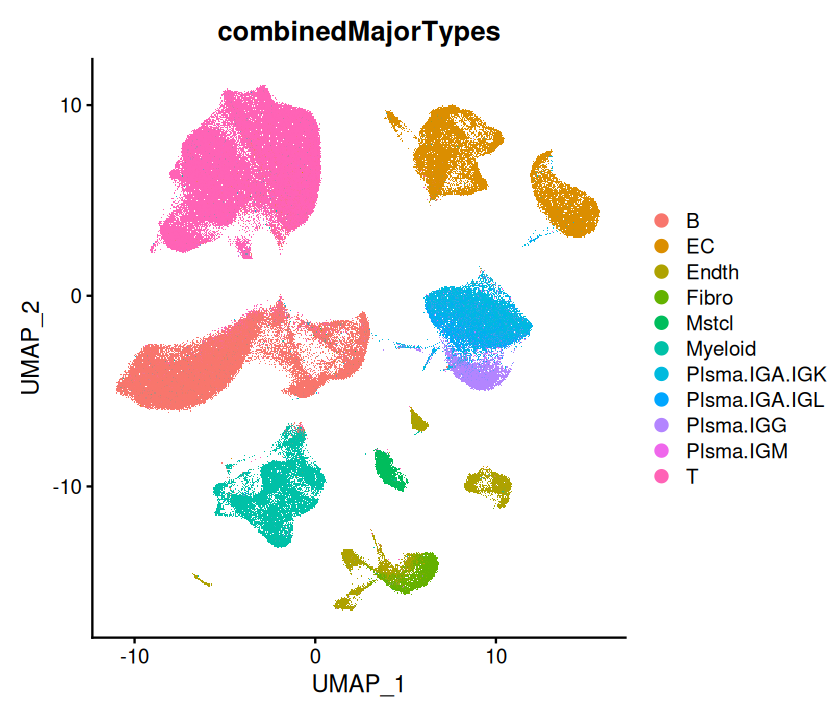

In [46]:

DimPlot(predict_3p, group.by = "combinedMajorTypes")

In [47]:
condition_oi <-  "CD"
condition_reference <- "FGID"

seurat_obj_receiver <- subset(predict_3p, combinedMajorTypes == "T")

DE_table_receiver <-  FindMarkers(object = seurat_obj_receiver,
                                  ident.1 = condition_oi, ident.2 = condition_reference,
                                  group.by = "disease",
                                  min.pct = 0.05) %>% rownames_to_column("gene")

geneset_oi <- DE_table_receiver %>% filter(p_val_adj <= 0.05 & abs(avg_log2FC) >= 0.25) %>% pull(gene)
geneset_oi <- geneset_oi %>% .[. %in% rownames(ligand_target_matrix)]

In [48]:
geneset_oi

[1] "IGHM"        "IRF1"        "IL32"        "PSMB9"       "REG1A"      
   [6] "S100A4"      "PSME2"       "ISG15"       "LY6E"        "STAT1"      
  [11] "DEFA5"       "IFI44L"      "IGKC"        "HLA-C"       "HLA-B"      
  [16] "RPS29"       "HLA-A"       "PTMA"        "B2M"         "IGLC3"      
  [21] "TFF3"        "LYZ"         "TMSB10"      "IFI6"        "NEAT1"      
  [26] "RPS26"       "SUB1"        "RGS1"        "GBP5"        "IGHA1"      
  [31] "IFI16"       "S100A6"      "HNRNPH1"     "TYMP"        "MT2A"       
  [36] "ALOX5AP"     "SH3BGRL3"    "C1QB"        "PSME1"       "CREM"       
  [41] "C1QA"        "CDC42"       "STK17B"      "BIRC3"       "ENTPD1"     
  [46] "CDC42SE2"    "XIST"        "IGLC2"       "IFITM2"      "CD3D"       
  [51] "HLA-DPB1"    "MIR4435-2HG" "HLA-DPA1"    "GNLY"        "GBP1"       
  [56] "SUMO2"       "IFITM1"      "GZMA"        "ISG20"       "ARPC3"      
  [61] "ID2"         "CLIC1"       "GBP2"        "CST7"        "EPSTI1"     
  [66] "PSMB8"       "NKG7"        "PTPN22"      "MYL12A"      "HLA-E"      
  [71] "GMFG"        "POMP"        "RORA"        "DUSP4"       "TNFAIP3"    
  [76] "MYL6"        "TNFRSF18"    "GPBP1"       "LGALS3"      "HLA-DRB1"   
  [81] "IRF9"        "DEFA6"       "TXN"         "SRSF2"       "HMGB2"      
  [86] "CD2"         "ARID5B"      "CTSC"        "RNF213"      "COX8A"      
  [91] "LDHA"        "PYHIN1"      "CARD16"      "FDCSP"       "CCL20"      
  [96] "EIF4G2"      "DDX3X"       "FCER1G"      "SRGN"        "GSTP1"      
 [101] "PSMA4"       "CST3"        "BST2"        "NCL"         "NDUFA4"     
 [106] "SAMD9"       "MCL1"        "MBNL1"       "RPS27L"      "ELF1"       
 [111] "CBX3"        "MX1"         "PRDM1"       "PHGR1"       "MYL12B"     
 [116] "SET"         "PRDX1"       "HMGB1"       "ARL6IP5"     "HLA-DRB5"   
 [121] "CLEC2B"      "CIB1"        "TANK"        "GPR171"      "C1orf56"    
 [126] "SAMSN1"      "PPP1CB"      "EMP3"        "PSMB3"       "PRKAR1A"    
 [131] "APOL6"       "N4BP2L2"     "PPIB"        "PMAIP1"      "TYROBP"     
 [136] "TAP1"        "PPIA"        "EDF1"        "XAF1"        "SAT1"       
 [141] "TAX1BP1"     "HLA-F"       "RBM3"        "ATP6V0E1"    "GSTK1"      
 [146] "UBE2L6"      "G3BP2"       "COX6A1"      "CAPZA1"      "GBP4"       
 [151] "CHCHD2"      "LBR"         "DDX24"       "SYNE2"       "SRRM1"      
 [156] "CD63"        "TMEM50A"     "SON"         "PSMA1"       "SKP1"       
 [161] "CKLF"        "LEPROTL1"    "GZMB"        "COX6B1"      "PIK3R1"     
 [166] "SLC25A3"     "LYST"        "PARP14"      "DRAP1"       "DNAJC15"    
 [171] "EMB"         "BTN3A2"      "SEC61G"      "DBI"         "SRSF3"      
 [176] "GUK1"        "TNFSF10"     "PSMA3"       "COX5A"       "ARGLU1"     
 [181] "NEDD8"       "ANP32E"      "EIF2AK2"     "BATF"        "ODF2L"      
 [186] "CYCS"        "CD164"       "SMDT1"       "COX5B"       "CXCR6"      
 [191] "PSMB1"       "UBL5"        "CTLA4"       "ERH"         "ANXA5"      
 [196] "PARP9"       "VAMP5"       "IGHG1"       "S100A11"     "SUMO1"      
 [201] "MZT2A"       "REL"         "SAMD9L"      "VMP1"        "CD3G"       
 [206] "HCST"        "CDC42SE1"    "SSR4"        "PPP2R5C"     "SLFN5"      
 [211] "DDX46"       "NDUFB8"      "NAA50"       "BHLHE40"     "PRDX5"      
 [216] "CCL3"        "MTHFD2"      "CALR"        "IFI35"       "LUC7L3"     
 [221] "VAMP8"       "IFI44"       "IL2RG"       "FYN"         "CLDND1"     
 [226] "LCP1"        "ATRX"        "DYNLL1"      "HNRNPA3"     "SRSF5"      
 [231] "ZNF207"      "TPI1"        "MT-CO2"      "SNRPB"       "SEC61B"     
 [236] "PIP4K2A"     "NUCKS1"      "PSMB10"      "ATF4"        "ARF6"       
 [241] "YWHAB"       "JAK1"        "DEK"         "SF3B1"       "CMC1"       
 [246] "IL2RB"       "CCR6"        "CAST"        "EML4"        "NDUFS6"     
 [251] "BZW1"        "SMC4"        "COX7A2"      "CLEC2D"      "COX7B"      
 [256] "UBXN4"       "CD38"        "EIF1AX"      "PRRC2C"      "IDH2"       

In [49]:
background_expressed_genes <- expressed_genes_receiver %>% .[. %in% rownames(ligand_target_matrix)]

length(background_expressed_genes)
## [1] 3476
length(geneset_oi)
## [1] 260

[1] 4683

[1] 1930

In [50]:
ligand_activities <- predict_ligand_activities(geneset = geneset_oi,
                                               background_expressed_genes = background_expressed_genes,
                                               ligand_target_matrix = ligand_target_matrix,
                                               potential_ligands = potential_ligands)

In [51]:
ligand_activities

test_ligand,auroc,aupr,aupr_corrected,pearson
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
ACE2,0.5018671,0.4049455,-0.0054308915,-0.0077060896
ADAM10,0.5036702,0.4058054,-0.0045709201,-0.0010392143
ADAM11,0.5046256,0.4109356,0.0005592778,-0.0019103507
ADAM12,0.4995107,0.4031769,-0.0071994180,-0.0183033097
ADAM15,0.4967112,0.4044932,-0.0058832004,-0.0126727571
ADAM17,0.5021924,0.4151122,0.0047358708,0.0226042433
ADAM2,0.5027585,0.4071686,-0.0032077277,-0.0076115909
ADAM28,0.4963936,0.4023596,-0.0080167364,-0.0182652963
ADAM29,0.5050769,0.4114220,0.0010456507,0.0062796762


In [52]:
ligand_activities <- ligand_activities %>% arrange(-aupr_corrected) %>% arrange(desc(aupr_corrected))
ligand_activities

test_ligand,auroc,aupr,aupr_corrected,pearson
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
IFNB1,0.5342351,0.4685797,0.05820337,0.11600400
IL27,0.5299118,0.4596448,0.04926840,0.10093592
IFNL3,0.5247998,0.4557683,0.04539192,0.08725338
IFNG,0.5198405,0.4554178,0.04504144,0.09394772
IFNL1,0.5250889,0.4545175,0.04414116,0.09023255
IL3,0.5253969,0.4491605,0.03878413,0.07460106
IFNA1,0.5123393,0.4448963,0.03451998,0.09821182
EBI3,0.5276636,0.4425760,0.03219968,0.05669442
IFNA16,0.5236218,0.4418452,0.03146882,0.06042858


In [53]:
ligand_activities  %>% pull(test_ligand)

[1] "IFNB1"     "IL27"      "IFNL3"     "IFNG"      "IFNL1"     "IL3"      
  [7] "IFNA1"     "EBI3"      "IFNA16"    "IFNA5"     "IFNA21"    "IFNL2"    
 [13] "IFNE"      "IFNA2"     "IFNA4"     "IFNA7"     "IFNA14"    "LTB"      
 [19] "IL12A"     "IL21"      "IFNK"      "IFNA10"    "IFNL4"     "IFNA8"    
 [25] "IL24"      "IFNA17"    "TSLP"      "IL10"      "IL12B"     "IL26"     
 [31] "OSM"       "IFNA6"     "IL23A"     "TNF"       "IL11"      "IL22"     
 [37] "IL36G"     "SIGLEC6"   "IL6"       "IL9"       "CLCF1"     "PTPRC"    
 [43] "SIGLEC14"  "IFNA13"    "CXCL12"    "VSIG10"    "HLA-DRB5"  "IL4"      
 [49] "CNTF"      "LIF"       "IFNW1"     "TGFB1"     "IL7"       "IFITM1"   
 [55] "IL18"      "IL13"      "BTLA"      "UCN3"      "TNFSF4"    "CCL2"     
 [61] "IL15"      "IL37"      "HLA-G"     "JAM2"      "CD40"      "CRLF1"    
 [67] "TNFSF12"   "LTA"       "TNFSF14"   "BMP8A"     "HLA-E"     "NECTIN3"  
 [73] "MMP1"      "TGFB2"     "LAMA2"     "TGM2"      "TNFRSF14"  "SIRPA"    
 [79] "MMP9"      "TIMP1"     "COL12A1"   "TCN1"      "SELP"      "SELE"     
 [85] "HLA-DMB"   "IL1F10"    "VTCN1"     "SFTPD"     "RECK"      "CLEC4G"   
 [91] "CD40LG"    "KIR2DL5A"  "MICB"      "COL26A1"   "SIGLEC9"   "ADAM17"   
 [97] "COL4A1"    "CCL11"     "COL10A1"   "ICOSLG"    "CD28"      "TNFSF13"  
[103] "HLA-A"     "CD86"      "SIGLEC1"   "HBEGF"     "MDK"       "CCL3"     
[109] "COL5A1"    "LRRN2"     "UCN2"      "CD72"      "B2M"       "CCL5"     
[115] "FASLG"     "CCL3L1"    "CD70"      "TNFSF18"   "SDC2"      "ZG16B"    
[121] "COL18A1"   "CLEC2D"    "MATN1"     "ANGPT2"    "SIGLEC7"   "CCL20"    
[127] "HLA-B"     "HMGB1"     "DEFB103B"  "ALCAM"     "CD5L"      "MUC7"     
[133] "HLA-DQA2"  "NCR3LG1"   "NLGN3"     "CD48"      "PDCD1LG2"  "HLA-F"    
[139] "TYROBP"    "TFF2"      "COL8A2"    "EDIL3"     "ANGPTL1"   "LILRB2"   
[145] "CCL8"      "CXCL2"     "VEGFD"     "TRAF2"     "IL16"      "CCL4"     
[151] "CD244"     "CXCL11"    "CXCL10"    "CADM3"     "CXCL9"     "HGF"      
[157] "ADAM29"    "NECTIN2"   "COMP"      "SECTM1"    "TNFSF15"   "LGALS3BP" 
[163] "CEACAM1"   "ICAM1"     "FBN1"      "DUSP18"    "ADAM11"    "CCL22"    
[169] "PLAT"      "THBS4"     "HLA-DRA"   "COL16A1"   "CCL3L3"    "CLEC2B"   
[175] "JAM3"      "COL9A1"    "OMG"       "HLA-DRB4"  "LAMB2"     "TNC"      
[181] "TNN"       "KCNA1"     "ADIPOQ"    "FCAR"      "OCLN"      "COL4A6"   
[187] "VCAN"      "MMP14"     "CD80"      "ADAM7"     "COL6A3"    "PODXL"    
[193] "FAM200A"   "VCAM1"     "S100A9"    "COL5A3"    "SIRPB2"    "AMBN"     
[199] "DEFB4B"    "GZMB"      "SIGLEC8"   "LRRC4B"    "TNFSF9"    "SIRPG"    
[205] "HLA-DRB1"  "LGALS9"    "LGALS1"    "CCL4L1"    "COL6A6"    "CCL21"    
[211] "TGFBI"     "LPA"       "LILRB4"    "PF4V1"     "PENK"      "DEFB4A"   
[217] "CXCL13"    "CD209"     "LRFN5"     "APP"       "IL2"       "COPA"     
[223] "CHAD"      "PLG"       "LAMB3"     "FGG"       "CD320"     "HLA-DPB1" 
[229] "CCL18"     "CLEC2A"    "TGFB3"     "NPNT"      "COL11A1"   "TIMP2"    
[235] "CCL7"      "LUM"       "CD2"       "COL9A3"    "COL19A1"   "LRPAP1"   
[241] "COL15A1"   "CCL13"     "OGN"       "COL17A1"   "MELTF"     "EGFL8"    
[247] "PCDHGB6"   "FGA"       "COL27A1"   "PECAM1"    "CCL19"     "ADAM9"    
[253] "MCAM"      "LAMC2"     "CD22"      "CCL26"     "APOA2"     "COL1A1"   
[259] "CTF1"      "GP1BA"     "CCL4L2"    "HLA-DOB"   "WNT7B"     "APOA1"    
[265] "CD200"     "COL4A4"    "JAML"      "ITGB2"     "CCN2"      "COL14A1"  
[271] "CD1B"      "COL13A1"   "L1CAM"     "CXCL16"    "CXCL14"    "COL5A2"   
[277] "HSPG2"     "COL11A2"   "CDH1"      "PYY"       "CD274"     "MXRA5"    
[283] "HLA-DQB1"  "CD47"      "PIP"       "PCSK9"     "PF4"       "S100A4"   
[289] "NAALADL1"  "ENAM"      "HAS2"      "ANGPT1"    "PDGFA"     "CD99"     
[295] "CXADR"     "CD82"      "RAET1E"    "PLA2G2A"   "CCL16"     "CALR"     
[301] "NECTIN1"   "ADAM2"     "COL9A2"    "GGT1"      "COL6A2"    "GP5"      
[307] "S100A8"    "SELPL

Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.”
`stat_bin()` using `bins = 30`. Pick better value `binwidth`.


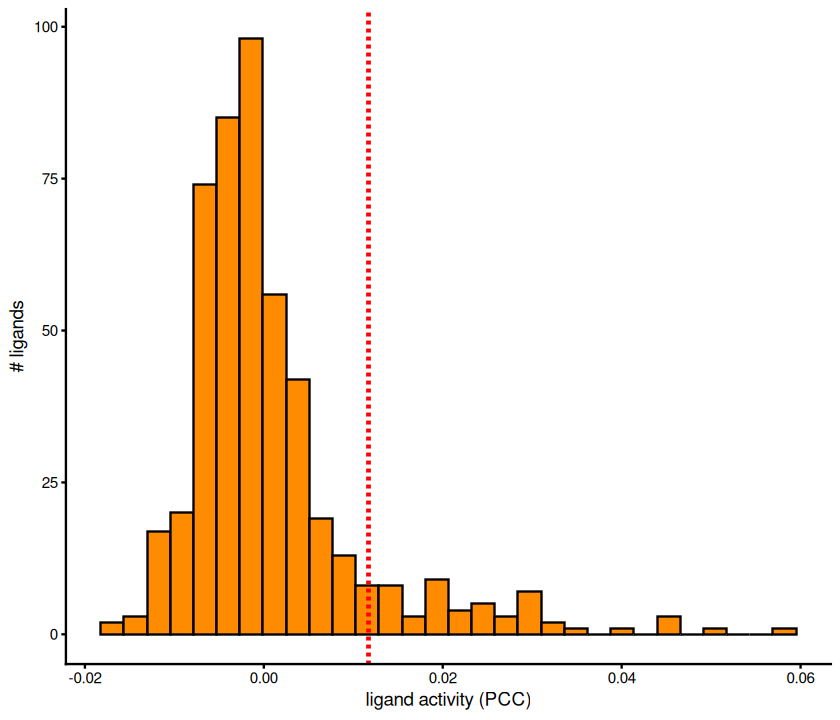

In [54]:
p_hist_lig_activity <- ggplot(ligand_activities, aes(x=aupr_corrected)) + 
  geom_histogram(color="black", fill="darkorange")  + 
  geom_vline(aes(xintercept=min(ligand_activities %>% top_n(50, aupr_corrected) %>% pull(aupr_corrected))),
             color="red", linetype="dashed", size=1) + 
  labs(x="ligand activity (PCC)", y = "# ligands") +
  theme_classic()

p_hist_lig_activity

In [55]:
best_upstream_ligands <- ligand_activities %>% top_n(50, aupr_corrected) %>% arrange(-aupr_corrected) %>% pull(test_ligand)

In [56]:
ggtheme <- function() {
  theme(
    axis.text = element_text(size = 20),
    axis.title = element_text(size = 20),
    text = element_text(size = 20, colour = "black"),
    legend.text = element_text(size = 20),
    legend.key.size =  unit(10, units = "points")
    
  )
}

Warning message:
“The `size` argument of `element_line()` is deprecated as of ggplot2 3.4.0.
ℹ Please use the `linewidth` argument instead.
ℹ The deprecated feature was likely used in the nichenetr package.
  Please report the issue at <https://github.com/saeyslab/nichenetr/issues>.”


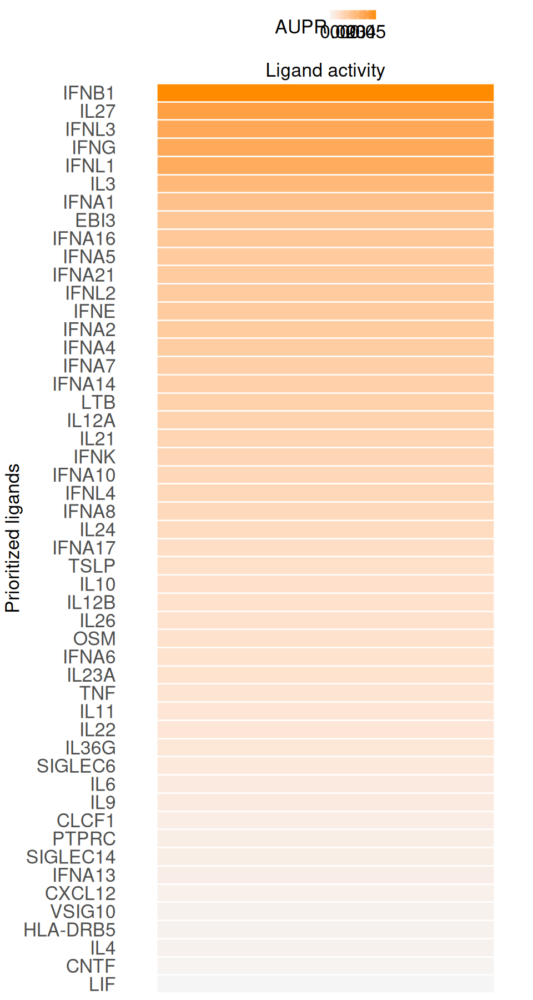

In [57]:
options(repr.plot.width = 8, repr.plot.height = 15)
vis_ligand_aupr <- ligand_activities %>% filter(test_ligand %in% best_upstream_ligands) %>%
  column_to_rownames("test_ligand") %>% select(aupr_corrected) %>% arrange(aupr_corrected) %>% as.matrix(ncol = 1)

(make_heatmap_ggplot(vis_ligand_aupr,
                     "Prioritized ligands", "Ligand activity", 
                     legend_title = "AUPR", color = "darkorange") + 
    theme(axis.text.x.top = element_blank()))  + ggtheme()

In [58]:
dir.create("figures/ligand_receptor/")

In [69]:
ggsave(filename = "figures/ligand_receptor/nichenet_receiver_predict3p.svg",
      width = 25, height = 30, units = "cm")

In [43]:
ligand_activities %>% filter(test_ligand %in% best_upstream_ligands)   %>% pull(test_ligand)

[1] "IFNB1"    "IL27"     "IFNL3"    "IFNG"     "IFNL1"    "IL3"     
 [7] "IFNA1"    "EBI3"     "IFNA16"   "IFNA5"    "IFNA21"   "IFNL2"   
[13] "IFNE"     "IFNA2"    "IFNA4"    "IFNA7"    "IFNA14"   "LTB"     
[19] "IL12A"    "IL21"     "IFNK"     "IFNA10"   "IFNL4"    "IFNA8"   
[25] "IL24"     "IFNA17"   "TSLP"     "IL10"     "IL12B"    "IL26"    
[31] "OSM"      "IFNA6"    "IL23A"    "TNF"      "IL11"     "IL22"    
[37] "IL36G"    "SIGLEC6"  "IL6"      "IL9"      "CLCF1"    "PTPRC"   
[43] "SIGLEC14" "IFNA13"   "CXCL12"   "VSIG10"   "HLA-DRB5" "IL4"     
[49] "CNTF"     "LIF"

## Ligand expression in cell types

In [58]:
predict_3p@meta.data  <- predict_3p@meta.data  %>% 
mutate(Combined2 = if_else(grepl(combinedMajorTypes, pattern = "Plsma"), "PlasmaCells",combinedMajorTypes))

In [59]:
predict_3p$Combined2  %>% table

.
          B          EC       Endth       Fibro       Mstcl     Myeloid 
      48292       22960        9031        4647        3425       15678 
PlasmaCells           T 
      25577       67671 

In [60]:
aggexp_3p  <- AggregateExpression(predict_3p, group.by = c("patient", "disease", "Combined2",
                                                         "inflammation", "sex", "age"), 
                                  slot = "data",
                                  features = c(ligand_activities %>% filter(test_ligand %in% best_upstream_ligands)   %>% pull(test_ligand)),
                               return.seurat = T) 

Warning message:
“The following 20 features were not found in the RNA assay: IFNL3, IFNA1, IFNA16, IFNA5, IFNA21, IFNL2, IFNA2, IFNA4, IFNA7, IFNA14, IFNK, IFNA10, IFNL4, IFNA8, IFNA17, IFNA6, IL36G, IL9, IFNA13, CNTF”
Centering and scaling data matrix



In [61]:
aggexp_3p$Combined2  %>% table

.
          B          EC       Endth       Fibro       Mstcl     Myeloid 
         27          27          27          26          27          27 
PlasmaCells           T 
         27          27 

In [62]:
aggexp_3p  <- NormalizeData(aggexp_3p)

Normalizing layer: counts



In [63]:
aggexp_3p  <- ScaleData(aggexp_3p)

Centering and scaling data matrix



In [64]:
meta_aggexp_3p  <- AggregateExpression(aggexp_3p, group.by = c("Combined2"), slot = "counts",
                                  features = rownames(aggexp_3p), assay= "RNA",
                               return.seurat = F)

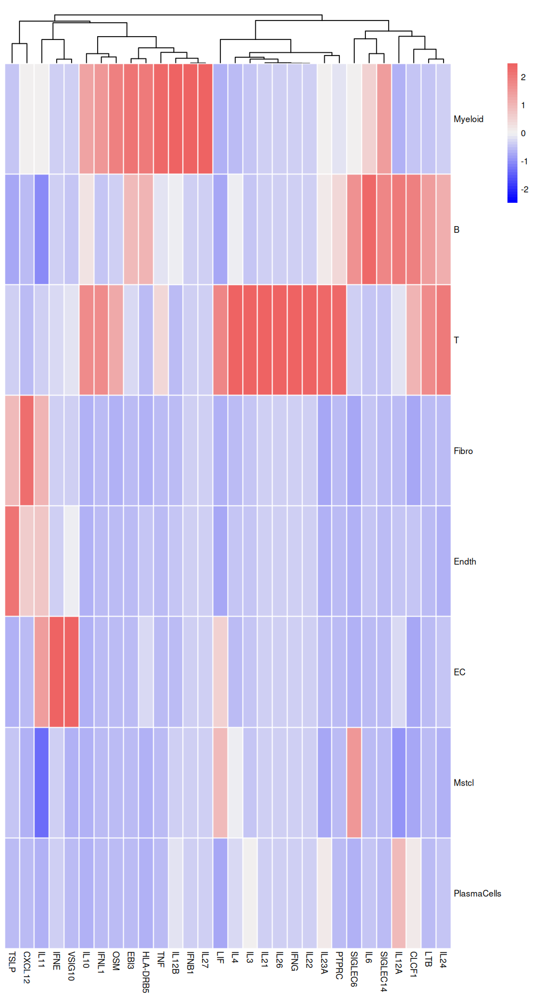

In [65]:
pheatmap::pheatmap(t(meta_aggexp_3p$RNA)[c(6,1,8,4,3,2,5,7),], main = "", 
         scale = "column", cluster_cols = T, cluster_rows = F,
        color=colorRampPalette(c("blue", "grey95", "indianred2"))(50), 
         border_color = "white",
                  fontsize = 9, 
                  width = 8, height = 3.5)

In [196]:
options(repr.plot.width = 8, repr.plot.height = 3.5)
pheatmap::pheatmap(t(meta_aggexp_3p$RNA)[c(6,1,8,4,3,2,5,7),], main = "", 
         scale = "column", cluster_cols = T, cluster_rows = F,
        color=colorRampPalette(c("blue", "grey95", "indianred2"))(50), 
         border_color = "white",
                  fontsize = 9, 
                  width = 8, height = 3.5,
                  filename = "figures/ligand_receptor/predict3p_ligand_expression_heatmap.pdf")

In [270]:
Idents(aggexp_3p)  <- aggexp_3p$disease

In [271]:
for(i in levels(factor(aggexp_3p$Combined2))){
   data_sub  <- subset(aggexp_3p, Combined2 == i)
       mrk  <- FindMarkers(data_sub, `ident.1` = "CD", `ident.2` = "FGID", 
                           only.pos = F, return.thresh = 1, slot = "counts",
                          logfc.threshold = -Inf, min.pct = 0.5, min.diff.pct = 0)
   mrk$gene  <- rownames(mrk)
    mrk$celltype  <- i
    if(i == levels(factor(aggexp_3p$Combined2))[1]){
        mrk_all  <- mrk
    } else {
        mrk_all  <- rbind(mrk_all, mrk)
    }
}

In [272]:
mrk_all  %>% arrange(p_val_adj) 

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,gene,celltype
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
IL62,0.0004737069,7.91439633,0.769,0.077,0.01421121,IL6,Fibro
LTB4,0.0006462044,1.33567190,1.000,0.615,0.01938613,LTB,Mstcl
IL263,0.0009572302,2.30236069,1.000,0.846,0.02871691,IL26,T
IL27,0.0017654860,2.62315586,0.929,0.462,0.05296458,IL27,Myeloid
SIGLEC142,0.0023742749,0.72111483,1.000,0.769,0.07122825,SIGLEC14,Myeloid
PTPRC4,0.0028248412,-0.33235626,1.000,1.000,0.08474524,PTPRC,Mstcl
PTPRC1,0.0029069088,1.51233463,1.000,0.538,0.08720726,PTPRC,EC
OSM2,0.0048785300,0.02819641,1.000,1.000,0.14635590,OSM,Myeloid
EBI35,0.0059417156,1.20391017,1.000,0.769,0.17825147,EBI3,T


## AvgLogFC plot

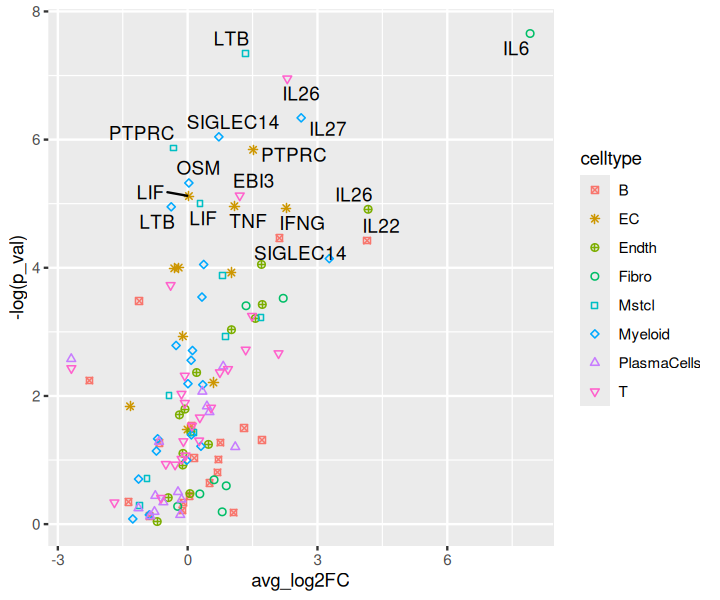

In [273]:
options(repr.plot.width = 6, repr.plot.height = 5)

mrk_all  %>% arrange(p_val_adj)  %>% 
mutate(delabel = if_else(avg_log2FC > 5 | -log(p_val)>4.3,gene,""))  %>% 
ggplot(aes(x = avg_log2FC, y = -log(p_val), label = delabel)) +
geom_point(aes(color = celltype, shape = celltype)) +
        ggrepel::geom_text_repel() +
scale_shape_manual(values = c(7,8,10,21:25))

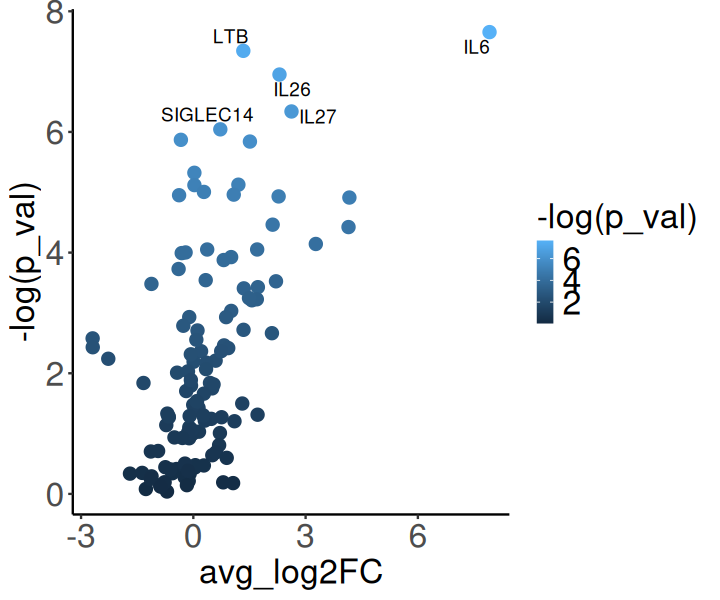

In [274]:
options(repr.plot.width = 6, repr.plot.height = 5)

mrk_all  %>% arrange(p_val_adj)  %>% 
mutate(delabel = if_else(avg_log2FC > 8 | -log(p_val)>6,gene,""))  %>% 
ggplot(aes(x = avg_log2FC, y = -log(p_val), label = delabel)) +
geom_point(aes(color = -log(p_val)), size = 3) +
        ggrepel::geom_text_repel() +
scale_shape_manual(values = c(7,8,10,21:25)) +
theme_classic() +
ggtheme()

ggsave("figures/ligand_receptor/volcano_predict3p.svg", width = 13, height = 10, units = "cm")

In [58]:
dir.create("figures/ligand_receptor/")

In [69]:
ggsave(filename = "figures/ligand_receptor/nichenet_receiver_predict3p.svg",
      width = 25, height = 30, units = "cm")

## Correlation with aTNF

In [219]:
md_to_join  <- predict_3p@meta.data  %>% 
group_by(patient, antiTNF_response)  %>% tally()  %>% 
dplyr::select(-n)

In [220]:
md_to_join

patient,antiTNF_response
<chr>,<chr>
p009,NM
p011,RESP
p014,RESP
p016,RESP
p017,NM
p018,PR
p019,NOA
p022,RESP
p023,NM


In [221]:
new_md  <- left_join(aggexp_3p@meta.data, md_to_join)

Joining with `by = join_by(patient)`


In [222]:
rownames(new_md)  <- colnames(aggexp_3p)

In [223]:
aggexp_3p@meta.data  <- new_md

In [224]:
aggexp_3p$antiTNF_response  %>% table

.
  NM  NOA   PR RESP 
 104   32   40   39 

In [225]:
aggexp_3p@meta.data  <- aggexp_3p@meta.data  %>% 
mutate(aTNF_numeric = case_when(antiTNF_response %in% c("NM","NOA") ~ 0,
                                antiTNF_response %in% c("RESP") ~ 1,
                                antiTNF_response %in% c("PR") ~ 2
                                ))

In [226]:
aggexp_3p$aTNF_numeric  %>% table

.
  0   1   2 
136  39  40 

In [248]:
for(i in levels(factor(aggexp_3p$Combined2))){
   data_sub  <- subset(aggexp_3p, Combined2 == i)
   data_sub  <- subset(aggexp_3p, Combined2 == i)
mtx  <- data_sub@assays$RNA@layers$counts
    colnames(mtx)  <- colnames(data_sub@assays$RNA)
    rownames(mtx)  <- rownames(data_sub@assays$RNA)
    df  <- t(mtx)  %>% as.data.frame()  %>% 
cbind(aTNF_numeric = data_sub$aTNF_numeric)  
    
 mrk  <-  df  %>% pivot_longer(!aTNF_numeric, names_to = "gene", values_to = "counts")  %>% 
group_by(gene)  %>% 
rstatix::cor_test(counts,aTNF_numeric)  %>% arrange(p)
    
    mrk$celltype  <- i
    if(i == levels(factor(aggexp_3p$Combined2))[1]){
        cor_all  <- mrk
    } else {
        cor_all  <- rbind(cor_all, mrk)
    }
}

In [251]:
cor_all

gene,var1,var2,cor,statistic,p,conf.low,conf.high,method,celltype
<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
EBI3,counts,aTNF_numeric,-0.3600,-1.90763832,0.068,-0.6486161,0.02723917,Pearson,B
IL26,counts,aTNF_numeric,0.3300,1.73528225,0.095,-0.0595634,0.62945800,Pearson,B
SIGLEC6,counts,aTNF_numeric,-0.3300,-1.73528225,0.095,-0.6294580,0.05956340,Pearson,B
IFNG,counts,aTNF_numeric,0.3200,1.67268986,0.107,-0.0713617,0.62225022,Pearson,B
IL10,counts,aTNF_numeric,-0.3000,-1.57349567,0.128,-0.6105510,0.09010747,Pearson,B
CLCF1,counts,aTNF_numeric,-0.2600,-1.35192773,0.189,-0.5831818,0.13210448,Pearson,B
TSLP,counts,aTNF_numeric,-0.2400,-1.23315906,0.229,-0.5678023,0.15462806,Pearson,B
IL23A,counts,aTNF_numeric,-0.2300,-1.17078615,0.253,-0.5595271,0.16644429,Pearson,B
IL4,counts,aTNF_numeric,-0.2200,-1.11111111,0.277,-0.5514821,0.17773541,Pearson,B


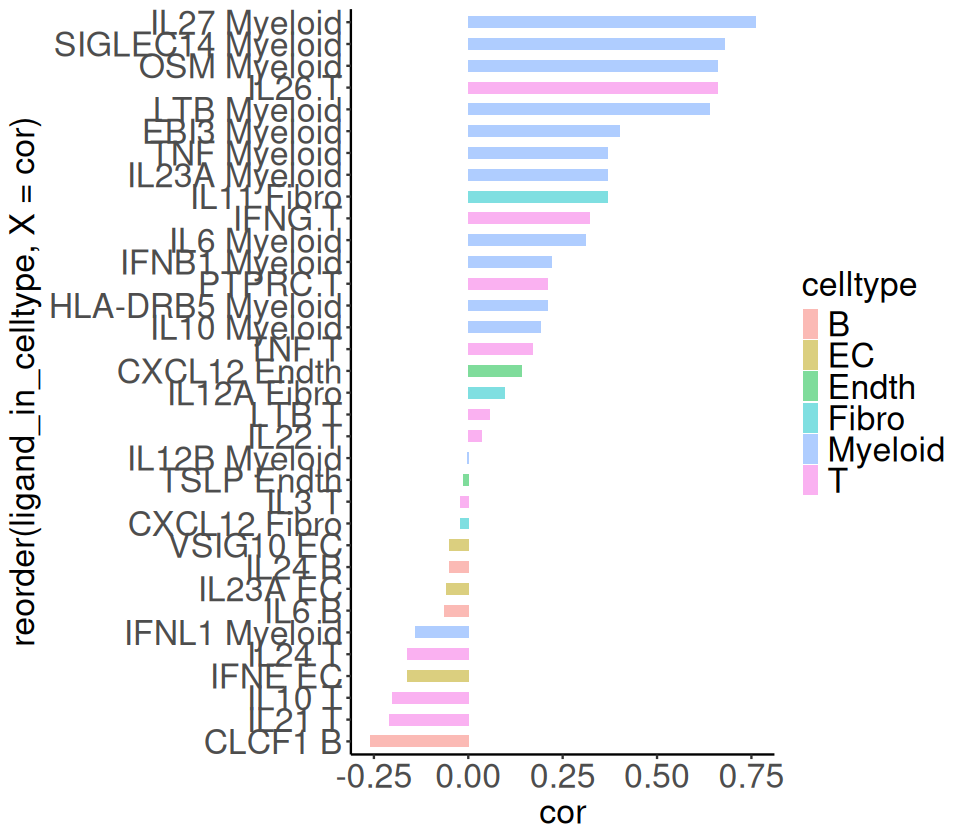

In [250]:
options(repr.plot.width = 8, repr.plot.height = 7)

cor_all  %>% 
mutate(ligand_in_celltype = paste(gene, celltype))  %>% 
dplyr::filter(ligand_in_celltype %in% ligands_expressed_in_celltypes)  %>% 
arrange(p)  %>% 
ggplot(aes(x = reorder(ligand_in_celltype, X = cor), y = cor)) +
stat_summary(fun = "mean",
               geom = "bar", 
               width = 0.5,
             alpha = 0.5,
             aes(fill = celltype)) +
       theme_classic() +
ggtheme() + coord_flip()


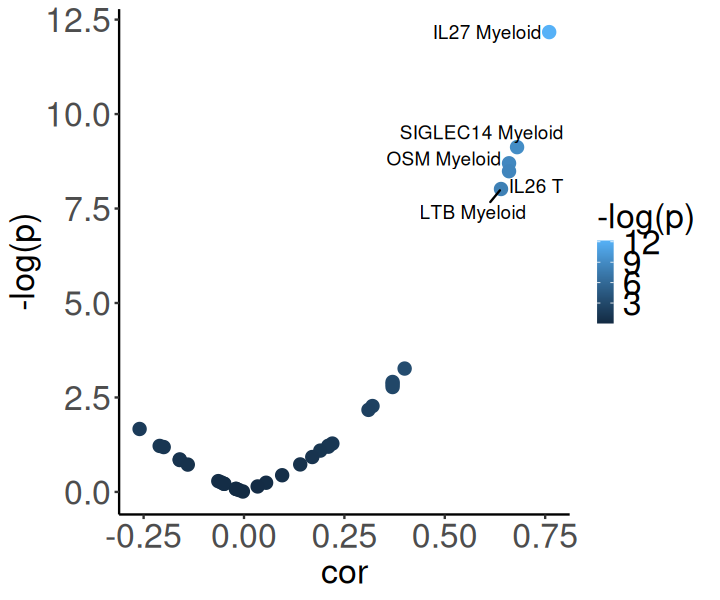

In [267]:
options(repr.plot.width = 6, repr.plot.height = 5)

cor_all  %>% arrange(p)  %>% 
mutate(ligand_in_celltype = paste(gene, celltype))  %>% 
dplyr::filter(ligand_in_celltype %in% ligands_expressed_in_celltypes)  %>% 
mutate(delabel = if_else(cor >0.5 ,ligand_in_celltype,""))  %>% 
ggplot(aes(x = cor, y = -log(p), label = delabel)) +
geom_point(aes(color = -log(p)), size = 3) +
        ggrepel::geom_text_repel() +
scale_shape_manual(values = c(7,8,10,21:25)) +
theme_classic() +
ggtheme()

#ggsave("figures/ligand_receptor/volcano_predict3p.svg", width = 13, height = 10, units = "cm")

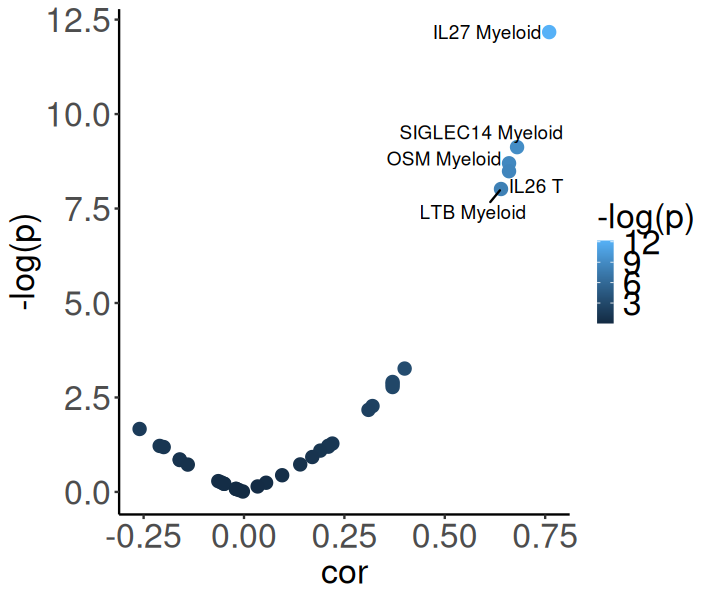

In [268]:

cor_all  %>% arrange(p)  %>% 
mutate(ligand_in_celltype = paste(gene, celltype))  %>% 
dplyr::filter(ligand_in_celltype %in% ligands_expressed_in_celltypes)  %>% 
mutate(delabel = if_else(cor >0.5 ,ligand_in_celltype,""))  %>% 
ggplot(aes(x = cor, y = -log(p), label = delabel)) +
geom_point(aes(color = -log(p)), size = 3) +
        ggrepel::geom_text_repel() +
scale_shape_manual(values = c(7,8,10,21:25)) +
theme_classic() +
ggtheme()

ggsave("figures/ligand_receptor/correlation_predict3p.svg", width = 13, height = 10, units = "cm")

In [254]:
df_cor_fc  <- data.frame(mrk_all  %>% mutate(ligand_in_celltype = paste(gene, celltype))  %>% 
                         dplyr::select(ligand_in_celltype, avg_log2FC, pval_fc = p_val))  %>% 
left_join(cor_all  %>% mutate(ligand_in_celltype = paste(gene, celltype))  %>% 
          dplyr::select(ligand_in_celltype, cor, pval_cor = p))

Joining with `by = join_by(ligand_in_celltype)`


In [255]:
df_cor_fc

ligand_in_celltype,avg_log2FC,pval_fc,cor,pval_cor
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
SIGLEC14 B,2.119769556,0.011529313,-0.0310,0.8770
IL22 B,4.146718176,0.011996214,0.0053,0.9790
IFNG B,-1.119037071,0.030780146,0.3200,0.1070
IL26 B,-2.272309863,0.106429138,0.3300,0.0950
TNF B,0.093762872,0.215300949,-0.1500,0.4580
IL6 B,1.307161243,0.223509846,-0.0640,0.7510
IL12A B,1.716824332,0.269052890,-0.1000,0.6040
IL24 B,0.754983203,0.280537156,-0.0500,0.8060
OSM B,-0.654770111,0.281187411,-0.1600,0.4290


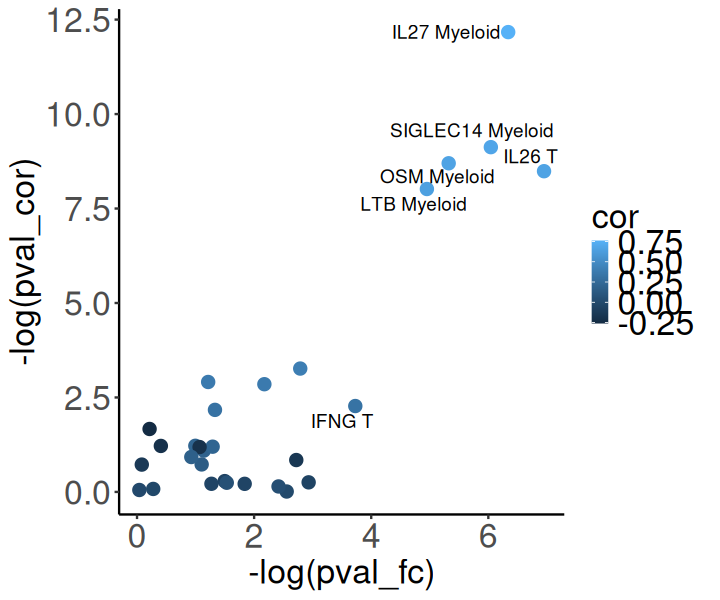

In [262]:
options(repr.plot.width = 6, repr.plot.height = 5)

df_cor_fc  %>% 
dplyr::filter(ligand_in_celltype %in% ligands_expressed_in_celltypes)  %>% 
mutate(delabel = if_else(avg_log2FC > 8 | -log(pval_fc)>3,ligand_in_celltype,""))  %>% 
ggplot(aes(x = -log(pval_fc), y = -log(pval_cor), label = delabel)) +
geom_point(aes(color = cor), size = 3) +
        ggrepel::geom_text_repel() +
scale_shape_manual(values = c(7,8,10,21:25)) +
theme_classic() +
ggtheme()


In [263]:
aggexp_3p_cd  <- subset(aggexp_3p, disease == "CD")
aggexp_3p$resp2  <- if_else(aggexp_3p$antiTNF_response == "PR","PR","Other")
table(aggexp_3p$resp2)
Idents(aggexp_3p)  <- aggexp_3p$resp2


Other    PR 
  175    40 

In [264]:
for(i in levels(factor(aggexp_3p$Combined2))){
   data_sub  <- subset(aggexp_3p, Combined2 == i)
       mrk  <- FindMarkers(data_sub, `ident.1` = "PR", `ident.2` = "Other", 
                           only.pos = F, return.thresh = 1, slot = "counts",
                          logfc.threshold = -Inf, min.pct = 0.5, min.diff.pct = 0)
   mrk$gene  <- rownames(mrk)
    mrk$celltype  <- i
    if(i == levels(factor(aggexp_3p$Combined2))[1]){
        mrk_all  <- mrk
    } else {
        mrk_all  <- rbind(mrk_all, mrk)
    }
}

In [265]:
mrk_all  %>% arrange(p_val_adj) 

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,gene,celltype
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
IL272,0.001007452,2.51196653,0.8,0.136,0.03022357,IL27,T
IL27,0.001105452,2.22917629,1.0,0.636,0.03316356,IL27,Myeloid
SIGLEC143,0.002179564,1.21187041,1.0,0.864,0.06538691,SIGLEC14,Myeloid
IFNG4,0.003321754,1.19282154,1.0,0.682,0.09965261,IFNG,Myeloid
OSM3,0.003697054,0.45770082,1.0,1.000,0.11091163,OSM,Myeloid
IL262,0.003906053,3.11527634,0.8,0.227,0.11718158,IL26,Endth
OSM1,0.005086438,6.92046148,0.6,0.048,0.15259313,OSM,Fibro
TSLP,0.006711543,1.44559156,0.8,0.227,0.20134629,TSLP,EC
IFNG5,0.007048457,1.46877256,1.0,0.545,0.21145372,IFNG,PlasmaCells


# PREDICT 5p

In [ ]:
ile_lp_ad_mtx <- readMM("data/cdn/ile_lp_ad.mtx")

In [3]:
ile_lp_ad_mtx[1:5,1:5]

In [4]:
ile_lp_genes <- read_csv("data/cdn/ile_lp_ad_genes.csv")

ile_lp_metadata <- read_csv("data/cdn/ile_lp_ad_meta.csv")

New names:
• `` -> `...1`
Rows: 36601 Columns: 1
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (1): ...1

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 1040968 Columns: 40
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (38): data_folder, data_folder2, bc, sample, diagnosis, subgroup_primary...
dbl  (2): age, days

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [5]:
rownames(ile_lp_ad_mtx) <- ile_lp_metadata$bc
colnames(ile_lp_ad_mtx) <- ile_lp_genes$...1

ile_lp_ad_mtx2 <- t(ile_lp_ad_mtx)

rownames(ile_lp_metadata) <- ile_lp_metadata$bc

seu_ile_lp <- CreateSeuratObject(ile_lp_ad_mtx2, meta.data = ile_lp_metadata)

seu_ile_lp$bc <- colnames(seu_ile_lp)

md_join <- left_join(seu_ile_lp@meta.data, ile_lp_metadata)
rownames(md_join) <- seu_ile_lp$bc

seu_ile_lp@meta.data <- md_join

saveRDS(seu_ile_lp, "data/cdn/seu5p_ile_lp_full.rds")


rm(md_join)
rm(ile_lp_ad_mtx)
rm(ile_lp_ad_mtx2)
rm(ile_lp_genes)
rm(ile_lp_metadata)

Warning message:
“Setting row names on a tibble is deprecated.”
Warning message:
“Data is of class dgTMatrix. Coercing to dgCMatrix.”
Warning message:
“No cell overlap between new meta data and Seurat object”
Joining with `by = join_by(bc)`


In [3]:
seu_ile_lp  <- readRDS("data/cdn/seu5p_ile_lp_full.rds")

In [4]:
ls()

[1] "seu_ile_lp"

In [5]:
metadata  <- read_delim("data/cdn//consolidated_annotation_2025-01-09.csv")

Rows: 4719277 Columns: 5
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (5): bc, cell_lineage, cell_type_lvl1, cell_type_lvl2, cell_state

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [6]:
metadata

bc,cell_lineage,cell_type_lvl1,cell_type_lvl2,cell_state
<chr>,<chr>,<chr>,<chr>,<chr>
AAACCTGAGAAGGCCT-1_1193611_1_1_1,Doublets,Doublets,Doublets,Doublets
AAACCTGAGATGTAAC-1_1193611_1_1_1,Immune,T Cells,T CD4,CD4 Th1/2
AAACCTGAGCACCGTC-1_1193611_1_1_1,Stroma,Fibroblasts,Fibroblast PDGFRApos,Fibroblast PDGFRApos
AAACCTGAGCGAGAAA-1_1193611_1_1_1,Immune,B Cells,B Cells Memory,Memory B cell IGHA1pos GPR183pos
AAACCTGAGCGATTCT-1_1193611_1_1_1,Immune,ILCs,ILC3,ILC3
AAACCTGAGGGAGTAA-1_1193611_1_1_1,Stroma,Fibroblasts,Fibroblast LP,Fibroblast LP CXCL12hi CCL11pos
AAACCTGAGTGGCACA-1_1193611_1_1_1,Immune,T Cells,MAITs,MAITs 17-like
AAACCTGAGTGTCTCA-1_1193611_1_1_1,Immune,B Cells,B Cells Memory,Memory B cell IGHA1pos GPR183pos
AAACCTGCAAAGCAAT-1_1193611_1_1_1,LowQ,LowQ,LowQ,LowQ


In [7]:
table(metadata$bc %in% seu_ile_lp$bc)


  FALSE    TRUE 
3678309 1040968 

In [8]:
table( seu_ile_lp$bc %in% metadata$bc )


   TRUE 
1040968 

In [9]:
md  <- seu_ile_lp@meta.data  %>% left_join(metadata)

Joining with `by = join_by(bc)`


In [10]:
rownames(md)  <- colnames(seu_ile_lp)

In [11]:
md

,orig.ident,nCount_RNA,nFeature_RNA,bc,data_folder,data_folder2,sample,diagnosis,subgroup_primary,subgroup_secondary,⋯,severity_score,weighted_severity_score,severity_score_date,severity_score_range,weighted_score_range,internal_flag,cell_lineage,cell_type_lvl1,cell_type_lvl2,cell_state
,<fct>,<dbl>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,⋯,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
AAACCTGAGAGCCTAG-1_1193610_1_1_1,SeuratProject,5012,1356,AAACCTGAGAGCCTAG-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,NM,NM,NM,NM,NM,Unknown,Immune,T Cells,T CD4,CD4 Naive
AAACCTGAGAGCTGCA-1_1193610_1_1_1,SeuratProject,1871,1164,AAACCTGAGAGCTGCA-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,NM,NM,NM,NM,NM,Unknown,Stroma,Fibroblasts,Myofibroblast,Myofibroblast
AAACCTGAGCGTAATA-1_1193610_1_1_1,SeuratProject,27170,2419,AAACCTGAGCGTAATA-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,NM,NM,NM,NM,NM,Unknown,Immune,Plasma Cells,PC IgG,PC IgGpos
AAACCTGAGCGTGTCC-1_1193610_1_1_1,SeuratProject,924,543,AAACCTGAGCGTGTCC-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,NM,NM,NM,NM,NM,Unknown,LowQ,LowQ,LowQ,LowQ
AAACCTGAGTGCTGCC-1_1193610_1_1_1,SeuratProject,1934,1015,AAACCTGAGTGCTGCC-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,NM,NM,NM,NM,NM,Unknown,Immune,T Cells,T CD8,CD8 Killer Memory GZMKpos CCL4hi
AAACCTGCACATTAGC-1_1193610_1_1_1,SeuratProject,3037,1337,AAACCTGCACATTAGC-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,NM,NM,NM,NM,NM,Unknown,Immune,B Cells,B Cells Memory,TRM B cells FCRL4pos FCRL5pos
AAACCTGCACCACGTG-1_1193610_1_1_1,SeuratProject,7302,1210,AAACCTGCACCACGTG-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,NM,NM,NM,NM,NM,Unknown,Immune,Plasma Cells,PC IgA,PC IgApos
AAACCTGCAGTCACTA-1_1193610_1_1_1,SeuratProject,3717,1404,AAACCTGCAGTCACTA-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,NM,NM,NM,NM,NM,Unknown,Immune,T Cells,T CD4,CD4 Tfh
AAACCTGCAGTTTACG-1_1193610_1_1_1,SeuratProject,2676,1070,AAACCTGCAGTTTACG-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,NM,NM,NM,NM,NM,Unknown,LowQ,LowQ,LowQ,LowQ


In [12]:
seu_ile_lp@meta.data  <- md

In [13]:
seu_ile_lp$cell_lineage  %>% table

.
     Doublets    Epithelial        Immune          LowQ Proliferating 
       107413        116028        507966        260735          4554 
       Stroma 
        44272 

In [8]:
md_5p  <- read_csv("data/metadata/250121_Gut_5p_metadata.csv")

New names:
• `` -> `...1`
Rows: 346456 Columns: 129
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (75): ...1, orig.ident, bc, data_folder, data_folder2, sample, diagnosis...
dbl (46): nCount_RNA, nFeature_RNA, age, days, scrublet_doublet_scores, n_ou...
lgl  (8): outliers, is_cell, count_Multi, cdr3_Multi, cdr3_Multi_nt, v_gene_...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [15]:
md_5p$bc %in% seu_ile_lp$bc  %>% table

.
 FALSE   TRUE 
196402 150054 

In [5]:
seu_ile_lp$cell_type_lvl2  %>% table

ERROR: Error in eval(expr, envir, enclos): object 'seu_ile_lp' not found


In [19]:
md_5p  %>% dplyr::filter(!bc %in% seu_ile_lp$bc)  %>% group_by(tissue, layer)  %>% tally

tissue,layer,n
<chr>,<chr>,<int>
COL,EPI,4776
COL,LP,117423
DUO,EPI,4522
DUO,LP,60694
ILE,EPI,8987


In [20]:
md_5p  %>% dplyr::filter(bc %in% seu_ile_lp$bc)  %>% group_by(tissue, layer)  %>% tally

tissue,layer,n
<chr>,<chr>,<int>
ILE,LP,150054


In [21]:
seu_ile_lp$keep  <- seu_ile_lp$cell_lineage %in% c("Epithelial","Immune","Proliferating","Stroma")

In [22]:
seu_ile_lp$keep  %>% table

.
 FALSE   TRUE 
368148 672820 

In [23]:
seu_ile_lp_filt  <- subset(seu_ile_lp, keep == TRUE)

In [24]:
seu_ile_lp_filt$cell_lineage  %>% table

.
   Epithelial        Immune Proliferating        Stroma 
       116028        507966          4554         44272 

In [7]:
seu_ile_lp_filt$cell_type_lvl2  %>% table

.
        B Cells Memory          B Cells Naive                    DCs 
                 75250                  58355                   5466 
          ECs Arterial          ECs Capillary          ECs Lymphatic 
                   705                   3678                   1295 
     ECs Pericyte-like             ECs Venous Enterochromaffin cells 
                  1291                   5251                    221 
           Enterocytes  Enteroendocrine cells             Epithelial 
                 55076                    393                  41991 
         Fibroblast LP   Fibroblast PDGFRApos                   Glia 
                 22610                   5500                   1749 
          Goblet Cells                   ILC3            Macrophages 
                 10282                   5227                  30493 
                 MAITs                   Mast          Myofibroblast 
                  2929                  17045                   2234 
                  

In [26]:
colnames(seu_ile_lp_filt@meta.data)

[1] "orig.ident"              "nCount_RNA"             
 [3] "nFeature_RNA"            "bc"                     
 [5] "data_folder"             "data_folder2"           
 [7] "sample"                  "diagnosis"              
 [9] "subgroup_primary"        "subgroup_secondary"     
[11] "subgroup_tertiary"       "Rome_coarse"            
[13] "Rome_classification"     "antitnf_response"       
[15] "participant_id"          "timepoint"              
[17] "age"                     "sex"                    
[19] "site"                    "tissue"                 
[21] "layer"                   "prime"                  
[23] "version_10x"             "sample_old"             
[25] "data_type"               "seq_run"                
[27] "collection_purpose"      "collection_date"        
[29] "days"                    "antitnf"                
[31] "antitnf_repeat"          "duo_inflammation"       
[33] "ile_inflammation"        "col_inflammation"       
[35] "sample_inflamed"         "colon_site"             
[37] "score_type"              "severity_score"         
[39] "weighted_severity_score" "severity_score_date"    
[41] "severity_score_range"    "weighted_score_range"   
[43] "internal_flag"           "cell_lineage"           
[45] "cell_type_lvl1"          "cell_type_lvl2"         
[47] "cell_state"              "keep"

In [27]:
md  <- seu_ile_lp_filt@meta.data 

In [28]:
md  <- left_join(md, md_5p  %>% dplyr::select(bc, annotations))

Joining with `by = join_by(bc)`


In [29]:
md$annotations  %>% table

.
           CTL        Naive_1        Naive_2            Tcm            Tfh 
          5944          30349           6012          21154           8790 
           Th1         Th17_1         Th17_2            Th2 Treg activated 
         16388          14321           1665           6144          20329 
    Treg naive 
         10424 

In [30]:
table(is.na(md$annotations))


 FALSE   TRUE 
141520 531300 

In [31]:
rownames(md)  <- colnames(seu_ile_lp_filt)

In [32]:
seu_ile_lp_filt@meta.data  <- md

In [33]:
saveRDS(seu_ile_lp_filt, "data/cdn/seu5p_ile_lp_filt.rds")

## Ligand receptor interactions

In [285]:
seu_ile_lp

An object of class Seurat 
36601 features across 1040968 samples within 1 assay 
Active assay: RNA (36601 features, 0 variable features)
 1 layer present: counts

In [9]:
seu_ile_lp_filt

An object of class Seurat 
36601 features across 672820 samples within 1 assay 
Active assay: RNA (36601 features, 0 variable features)
 1 layer present: counts

In [10]:
organism <- "human"

if(organism == "human"){
  lr_network <- readRDS(url("https://zenodo.org/record/7074291/files/lr_network_human_21122021.rds"))
  ligand_target_matrix <- readRDS(url("https://zenodo.org/record/7074291/files/ligand_target_matrix_nsga2r_final.rds"))
  weighted_networks <- readRDS(url("https://zenodo.org/record/7074291/files/weighted_networks_nsga2r_final.rds"))
} else if(organism == "mouse"){
  lr_network <- readRDS(url("https://zenodo.org/record/7074291/files/lr_network_mouse_21122021.rds"))
  ligand_target_matrix <- readRDS(url("https://zenodo.org/record/7074291/files/ligand_target_matrix_nsga2r_final_mouse.rds"))
  weighted_networks <- readRDS(url("https://zenodo.org/record/7074291/files/weighted_networks_nsga2r_final_mouse.rds"))

}

lr_network <- lr_network %>% distinct(from, to)
head(lr_network)

from,to
<chr>,<chr>
A2M,MMP2
A2M,MMP9
A2M,LRP1
A2M,KLK3
AANAT,MTNR1A
AANAT,MTNR1B


In [11]:
seu_ile_lp_filt$cd4_ctl  <- FALSE

In [12]:
seu_ile_lp_filt$cd4_ctl  <- if_else(seu_ile_lp_filt$annotations == "CTL",TRUE,FALSE)

In [13]:
seu_ile_lp_filt$cd4_ctl  <- ifelse(is.na(seu_ile_lp_filt$cd4_ctl),FALSE,seu_ile_lp_filt$cd4_ctl)

In [14]:
seu_ile_lp_filt@meta.data  <- seu_ile_lp_filt@meta.data  %>% 
mutate(cell_type_lvl2 = if_else(grepl(cell_type_lvl2, pattern = "T "), "T cells", cell_type_lvl2))

In [15]:
seu_ile_lp_filt@meta.data   %>% group_by(cd4_ctl, cell_type_lvl2)  %>% tally

cd4_ctl,cell_type_lvl2,n
<lgl>,<chr>,<int>
FALSE,B Cells Memory,75250
FALSE,B Cells Naive,58355
FALSE,DCs,5466
FALSE,ECs Arterial,705
FALSE,ECs Capillary,3678
FALSE,ECs Lymphatic,1295
FALSE,ECs Pericyte-like,1291
FALSE,ECs Venous,5251
FALSE,Enterochromaffin cells,221


In [16]:
seu_ile_lp_filt@meta.data  <- seu_ile_lp_filt@meta.data  %>% 
mutate(combinedMajorTypes_plus_cd4_ctl = if_else(cd4_ctl, "CD4_CTL", cell_type_lvl2))

In [17]:
seu_ile_lp_filt$combinedMajorTypes_plus_cd4_ctl  %>% table

.
        B Cells Memory          B Cells Naive                CD4_CTL 
                 75250                  58355                   5944 
                   DCs           ECs Arterial          ECs Capillary 
                  5466                    705                   3678 
         ECs Lymphatic      ECs Pericyte-like             ECs Venous 
                  1295                   1291                   5251 
Enterochromaffin cells            Enterocytes  Enteroendocrine cells 
                   221                  55076                    393 
            Epithelial          Fibroblast LP   Fibroblast PDGFRApos 
                 41991                  22610                   5500 
                  Glia           Goblet Cells                   ILC3 
                  1749                  10282                   5227 
           Macrophages                  MAITs                   Mast 
                 30493                   2929                  17045 
         Myofibrob

In [18]:
DefaultAssay(seu_ile_lp_filt)  <- "RNA"

In [19]:
seu_ile_lp_filt$cellsubsets_plus_cd4_ctl  <- ifelse(seu_ile_lp_filt$cd4_ctl, "CD4_CTL",seu_ile_lp_filt$cell_type_lvl2)

In [20]:
seu_ile_lp_filt$cellsubsets_plus_cd4_ctl  %>% table

.
        B Cells Memory          B Cells Naive                CD4_CTL 
                 75250                  58355                   5944 
                   DCs           ECs Arterial          ECs Capillary 
                  5466                    705                   3678 
         ECs Lymphatic      ECs Pericyte-like             ECs Venous 
                  1295                   1291                   5251 
Enterochromaffin cells            Enterocytes  Enteroendocrine cells 
                   221                  55076                    393 
            Epithelial          Fibroblast LP   Fibroblast PDGFRApos 
                 41991                  22610                   5500 
                  Glia           Goblet Cells                   ILC3 
                  1749                  10282                   5227 
           Macrophages                  MAITs                   Mast 
                 30493                   2929                  17045 
         Myofibrob

In [21]:
colnames(seu_ile_lp_filt@meta.data)

[1] "orig.ident"                      "nCount_RNA"                     
 [3] "nFeature_RNA"                    "bc"                             
 [5] "data_folder"                     "data_folder2"                   
 [7] "sample"                          "diagnosis"                      
 [9] "subgroup_primary"                "subgroup_secondary"             
[11] "subgroup_tertiary"               "Rome_coarse"                    
[13] "Rome_classification"             "antitnf_response"               
[15] "participant_id"                  "timepoint"                      
[17] "age"                             "sex"                            
[19] "site"                            "tissue"                         
[21] "layer"                           "prime"                          
[23] "version_10x"                     "sample_old"                     
[25] "data_type"                       "seq_run"                        
[27] "collection_purpose"              "collection_date"                
[29] "days"                            "antitnf"                        
[31] "antitnf_repeat"                  "duo_inflammation"               
[33] "ile_inflammation"                "col_inflammation"               
[35] "sample_inflamed"                 "colon_site"                     
[37] "score_type"                      "severity_score"                 
[39] "weighted_severity_score"         "severity_score_date"            
[41] "severity_score_range"            "weighted_score_range"           
[43] "internal_flag"                   "cell_lineage"                   
[45] "cell_type_lvl1"                  "cell_type_lvl2"                 
[47] "cell_state"                      "keep"                           
[49] "annotations"                     "cd4_ctl"                        
[51] "combinedMajorTypes_plus_cd4_ctl" "cellsubsets_plus_cd4_ctl"

In [22]:
Idents(seu_ile_lp_filt)  <- seu_ile_lp_filt$combinedMajorTypes_plus_cd4_ctl

In [28]:
library(nichenetr)

Registered S3 method overwritten by 'pROC':
  method   from            
  plot.roc spatstat.explore

Warning message:
“replacing previous import ‘e1071::element’ by ‘ggplot2::element’ when loading ‘nichenetr’”

Attaching package: ‘nichenetr’


The following object is masked _by_ ‘.GlobalEnv’:

    lr_network




In [24]:
receiver = "CD4_CTL"
expressed_genes_receiver <- get_expressed_genes(receiver, seu_ile_lp_filt, pct = 0.05)

Warning message in GetAssayData.StdAssay(object = object[[assay]], layer = layer):
“data layer is not found and counts layer is used”


In [25]:
all_receptors <- unique(lr_network$to)  
expressed_receptors <- intersect(all_receptors, expressed_genes_receiver)

potential_ligands <- lr_network %>% filter(to %in% expressed_receptors) %>% pull(from) %>% unique()

In [26]:
expressed_receptors

[1] "TIGIT"     "NOTCH2"    "CD44"      "NOTCH1"    "TSPAN5"    "TSPAN14"  
  [7] "TSPAN17"   "ITGA4"     "CCR4"      "SDC4"      "ITGB1"     "ITGA5"    
 [13] "IL6R"      "ITGB7"     "ITGAV"     "CD55"      "ADIPOR1"   "ADIPOR2"  
 [19] "ADRB2"     "CD6"       "CD63"      "LAMP1"     "LAMP2"     "ITGA1"    
 [25] "ABCA1"     "LDLR"      "ITGB2"     "SORL1"     "NCSTN"     "CD74"     
 [31] "MGRN1"     "TAP1"      "TAP2"      "SELPLG"    "NTRK2"     "BMPR2"    
 [37] "ENG"       "TGFBR1"    "TGFBR2"    "PLAUR"     "TNFRSF14"  "CD247"    
 [43] "JAML"      "C3AR1"     "CD46"      "IL2RG"     "LRCH4"     "CCR5"     
 [49] "CXCR3"     "DPP4"      "CCR7"      "CCR6"      "CCR9"      "IGF2R"    
 [55] "IL6ST"     "CD53"      "CD200R1"   "ICAM3"     "PTPRC"     "CD79B"    
 [61] "LAT"       "PDCD1"     "NCR3"      "CD4"       "LRPAP1"    "TMEM167A" 
 [67] "CD40LG"    "SIRPG"     "CD2"       "CD244"     "ADGRE5"    "CD5"      
 [73] "ADAM15"    "CD27"      "SEMA4D"    "CD274"     "CD28"      "CTLA4"    
 [79] "CD37"      "IGSF8"     "CD99"      "CD81"      "KLRG1"     "ITGAE"    
 [85] "PTPRM"     "BTN3A1"    "CD3D"      "HAVCR2"    "CD8A"      "UXS1"     
 [91] "BTN2A2"    "CXCR4"     "KLRB1"     "CLEC2B"    "LAG3"      "IL23R"    
 [97] "FCGRT"     "SLAMF1"    "LAIR1"     "TNFRSF10A" "CD47"      "LIN7C"    
[103] "PATJ"      "GNAS"      "A1BG"      "F2R"       "CXCR6"     "GPR35"    
[109] "CD151"     "RPSA"      "IL27RA"    "ECE1"      "EVC2"      "ADORA2A"  
[115] "ITGAL"     "TRAF2"     "SLC9A1"    "CLEC2D"    "FAS"       "ADAM19"   
[121] "ORAI2"     "CD82"      "AMFR"      "TNFRSF1A"  "TNFRSF1B"  "MCL1"     
[127] "EZR"       "BTN3A3"    "TMIGD2"    "NEO1"      "APLP2"     "IL2RA"    
[133] "SPN"       "MSN"       "ICOS"      "IFNAR1"    "IFNAR2"    "IFNGR1"   
[139] "IL10RB"    "TRPV2"     "IGFLR1"    "VSIR"      "IL10RA"    "IL12RB1"  
[145] "IL12RB2"   "IL4R"      "IL15RA"    "IL2RB"     "KCNA3"     "IL17RA"   
[151] "IL17RE"    "IL18R1"    "IL18RAP"   "SIGIRR"    "IL21R"     "BCL2"     
[157] "IL7R"      "TGFBR3"    "CD226"     "ICAM1"     "CD320"     "RTN4"     
[163] "MPZL3"     "LMBR1L"    "CD69"      "ANXA2"     "SLC1A5"    "LPAR2"    
[169] "BTN3A2"    "TMEM123"   "TFRC"      "C1QB"      "HCST"      "KIAA0319L"
[175] "CD96"      "NPTN"      "ERAP1"     "HLA-DRB1"  "FURIN"     "CD38"     
[181] "OGFR"      "PIGR"      "PLGRKT"    "TYROBP"    "TNFRSF25"  "PSEN1"    
[187] "JMJD6"     "ATP6AP2"   "GPR25"     "PTPRJ"     "ADAM12"    "CD7"      
[193] "GLG1"      "PLXNC1"    "SLC37A1"   "S1PR1"     "LRP12"     "TMEM216"  
[199] "TCTN3"     "ADAM17"    "BTLA"      "TNFRSF10B" "TNFRSF18"  "TNFRSF4"  
[205] "MAP4K2"    "ADAM10"    "RYK"       "TMED5"

In [27]:
potential_ligands

[1] "ACE2"      "ADAM10"    "ADAM11"    "ADAM12"    "ADAM15"    "ADAM17"   
  [7] "ADAM2"     "ADAM23"    "ADAM28"    "ADAM29"    "ADAM7"     "ADAM9"    
 [13] "ADGRE5"    "ADIPOQ"    "ADM2"      "AGRN"      "ALCAM"     "AMBN"     
 [19] "AMELX"     "AMELY"     "ANGPT1"    "ANGPT2"    "ANGPTL1"   "ANGPTL2"  
 [25] "ANGPTL3"   "ANGPTL4"   "APOA1"     "APOA2"     "APOA4"     "APOB"     
 [31] "APOC2"     "APOC3"     "APOE"      "APP"       "ASIP"      "AZGP1"    
 [37] "B2M"       "BACE1"     "BDNF"      "BMP1"      "BMP10"     "BMP15"    
 [43] "BMP2"      "BMP3"      "BMP4"      "BMP5"      "BMP6"      "BMP7"     
 [49] "BMP8A"     "BMP8B"     "BTLA"      "BTN1A1"    "BTNL9"     "C3"       
 [55] "C4A"       "C4B_2"     "C4BPA"     "CADM3"     "CALR"      "CCL1"     
 [61] "CCL11"     "CCL13"     "CCL14"     "CCL16"     "CCL17"     "CCL18"    
 [67] "CCL19"     "CCL2"      "CCL20"     "CCL21"     "CCL22"     "CCL25"    
 [73] "CCL26"     "CCL3"      "CCL3L1"    "CCL3L3"    "CCL4"      "CCL4L1"   
 [79] "CCL4L2"    "CCL5"      "CCL7"      "CCL8"      "CCN1"      "CCN2"     
 [85] "CCN3"      "CCN4"      "CCN6"      "CD160"     "CD1B"      "CD2"      
 [91] "CD200"     "CD209"     "CD22"      "CD244"     "CD274"     "CD28"     
 [97] "CD320"     "CD40"      "CD40LG"    "CD47"      "CD48"      "CD55"     
[103] "CD58"      "CD59"      "CD5L"      "CD7"       "CD70"      "CD72"     
[109] "CD79B"     "CD80"      "CD82"      "CD86"      "CD9"       "CD99"     
[115] "CDH1"      "CDH9"      "CDHR2"     "CEACAM1"   "CEACAM5"   "CEACAM6"  
[121] "CEACAM8"   "CEL"       "CGA"       "CHAD"      "CKLF"      "CLCF1"    
[127] "CLEC11A"   "CLEC2A"    "CLEC2B"    "CLEC2D"    "CLEC2L"    "CLEC3A"   
[133] "CLEC4G"    "CLMP"      "CNTF"      "CNTN1"     "CNTN5"     "CNTN6"    
[139] "COL10A1"   "COL11A1"   "COL11A2"   "COL12A1"   "COL13A1"   "COL14A1"  
[145] "COL15A1"   "COL16A1"   "COL17A1"   "COL18A1"   "COL19A1"   "COL1A1"   
[151] "COL1A2"    "COL20A1"   "COL21A1"   "COL22A1"   "COL24A1"   "COL26A1"  
[157] "COL27A1"   "COL28A1"   "COL2A1"    "COL3A1"    "COL4A1"    "COL4A2"   
[163] "COL4A3"    "COL4A4"    "COL4A5"    "COL4A6"    "COL5A1"    "COL5A2"   
[169] "COL5A3"    "COL6A1"    "COL6A2"    "COL6A3"    "COL6A5"    "COL6A6"   
[175] "COL7A1"    "COL8A1"    "COL8A2"    "COL9A1"    "COL9A2"    "COL9A3"   
[181] "COMP"      "COPA"      "CRB3"      "CRHR2"     "CRISP3"    "CRLF1"    
[187] "CTF1"      "CTSG"      "CX3CL1"    "CXADR"     "CXCL10"    "CXCL11"   
[193] "CXCL12"    "CXCL13"    "CXCL14"    "CXCL16"    "CXCL17"    "CXCL2"    
[199] "CXCL9"     "DBH"       "DEFB1"     "DEFB103B"  "DEFB4A"    "DEFB4B"   
[205] "DLK1"      "DLK2"      "DLL1"      "DLL3"      "DLL4"      "DMP1"     
[211] "DSCAM"     "DSCAML1"   "DSPP"      "DUSP18"    "EBI3"      "EDIL3"    
[217] "EDN1"      "EFNB1"     "EGFL8"     "ENAM"      "ENG"       "ENTPD1"   
[223] "ESM1"      "EXOC3-AS1" "EZR"       "F10"       "F11R"      "F13A1"    
[229] "F2"        "F8"        "FAM200A"   "FAM3C"     "FAP"       "FASLG"    
[235] "FBLN1"     "FBN1"      "FCAR"      "FCER2"     "FGA"       "FGB"      
[241] "FGF2"      "FGF6"      "FGG"       "FGL1"      "FN1"       "FNDC5"    
[247] "FSHB"      "FST"       "FSTL5"     "FURIN"     "GCG"       "GDF1"     
[253] "GDF10"     "GDF11"     "GDF2"      "GDF5"      "GDF6"      "GDF7"     
[259] "GDF9"      "GGT1"      "GHRH"      "GIP"       "GNAS"      "GP1BA"    
[265] "GP5"       "GPC3"      "GPI"       "GRN"       "GSTP1"     "GZMB"     
[271] "HAS1"      "HAS2"      "HAVCR1"    "HBEGF"     "HGF"       "HHLA2"    
[277] "HJV"       "HLA-A"     "HLA-B"     "HLA-DMA"   "HLA-DMB"   "HLA-DOA"  
[283] "HLA-DOB"   "HLA-DPB1"  "HLA-DQA1"  "HLA-DQA2"  "HLA-DQB1"  "HLA-DQB2" 
[289] "HLA-DRA"   "HLA-DRB1"  "HLA-DRB3"  "HLA-DRB4"  "HLA-DRB5"  "HLA-E"    
[295] "HLA-F"     "HLA-G"     "HMGB1"     "HP"        "HSPG2"     "IBSP"     
[301] "ICAM1"     "ICAM2"     "ICAM3"     "ICAM4"     "ICAM5"     "ICOSLG"   
[307] "IFITM1"    "IFNA1

In [28]:
seu_ile_lp_filt$combinedMajorTypes_plus_cd4_ctl  %>% table

.
        B Cells Memory          B Cells Naive                CD4_CTL 
                 75250                  58355                   5944 
                   DCs           ECs Arterial          ECs Capillary 
                  5466                    705                   3678 
         ECs Lymphatic      ECs Pericyte-like             ECs Venous 
                  1295                   1291                   5251 
Enterochromaffin cells            Enterocytes  Enteroendocrine cells 
                   221                  55076                    393 
            Epithelial          Fibroblast LP   Fibroblast PDGFRApos 
                 41991                  22610                   5500 
                  Glia           Goblet Cells                   ILC3 
                  1749                  10282                   5227 
           Macrophages                  MAITs                   Mast 
                 30493                   2929                  17045 
         Myofibrob

In [29]:
seu_ile_lp_filt$diagnosis  %>% table

.
     CD    FGID     HEA     OTH      UC Unknown 
 331271  141443   66601   15959  106748   10798 

In [30]:
condition_oi <-  "CD"
condition_reference <- "FGID"

seurat_obj_receiver <- subset(seu_ile_lp_filt, combinedMajorTypes_plus_cd4_ctl %in% c("T cells","CD4_CTL"))

In [ ]:
seurat_obj_receiver  <- NormalizeData(seurat_obj_receiver)
seurat_obj_receiver  <- ScaleData(seurat_obj_receiver)


Normalizing layer: counts

Centering and scaling data matrix



In [ ]:
DE_table_receiver <-  FindMarkers(object = seurat_obj_receiver,
                                  ident.1 = condition_oi, ident.2 = condition_reference,
                                  group.by = "diagnosis") 

In [ ]:
table(rowSums(seurat_obj_receiver@assays$RNA@layers$counts)>5)

In [ ]:
DE_table_receiver$gene  <- rownames(DE_table_receiver)

In [ ]:
DE_table_receiver %>% filter(p_val_adj <= 0.05 & abs(avg_log2FC) >= 0.25)  %>% 
dplyr::filter(!grepl(gene, pattern = "^IG[KLH]"))

In [ ]:
geneset_oi <- DE_table_receiver %>% filter(p_val_adj <= 0.05 & abs(avg_log2FC) >= 0.25) %>% 
dplyr::filter(!grepl(gene, pattern = "^IG[KLH]"))  %>% pull(gene)

geneset_oi <- geneset_oi %>% .[. %in% rownames(ligand_target_matrix)]  

In [ ]:
geneset_oi

In [ ]:
background_expressed_genes <- expressed_genes_receiver %>% .[. %in% rownames(ligand_target_matrix)]

length(background_expressed_genes)
## [1] 3476
length(geneset_oi)
## [1] 260

In [ ]:
ligand_activities <- predict_ligand_activities(geneset = geneset_oi,
                                               background_expressed_genes = background_expressed_genes,
                                               ligand_target_matrix = ligand_target_matrix,
                                               potential_ligands = potential_ligands)

In [ ]:
ligand_activities

In [ ]:
ligand_activities <- ligand_activities %>% arrange(-aupr_corrected) %>% arrange(desc(aupr_corrected))
ligand_activities 

In [ ]:
ligand_activities  %>% pull(test_ligand)

In [ ]:
p_hist_lig_activity <- ggplot(ligand_activities, aes(x=aupr_corrected)) + 
  geom_histogram(color="black", fill="darkorange")  + 
  geom_vline(aes(xintercept=min(ligand_activities %>% top_n(50, aupr_corrected) %>% pull(aupr_corrected))),
             color="red", linetype="dashed", size=1) + 
  labs(x="ligand activity (PCC)", y = "# ligands") +
  theme_classic()

p_hist_lig_activity

In [ ]:
best_upstream_ligands <- ligand_activities %>% top_n(51, aupr_corrected) %>% arrange(-aupr_corrected) %>% pull(test_ligand)

In [ ]:
ggtheme <- function() {
  theme(
    axis.text = element_text(size = 20),
    axis.title = element_text(size = 20),
    text = element_text(size = 20, colour = "black"),
    legend.text = element_text(size = 20),
    legend.key.size =  unit(10, units = "points")
    
  )
}

In [ ]:
options(repr.plot.width = 8, repr.plot.height = 15)
vis_ligand_aupr <- ligand_activities %>% filter(test_ligand %in% best_upstream_ligands) %>%
  column_to_rownames("test_ligand") %>% select(aupr_corrected) %>% arrange(aupr_corrected) %>% as.matrix(ncol = 1)

(make_heatmap_ggplot(vis_ligand_aupr,
                     "Prioritized ligands", "Ligand activity", 
                     legend_title = "AUPR", color = "darkorange") + 
    theme(axis.text.x.top = element_blank()))  + ggtheme()

In [ ]:
vis_ligand_aupr <- ligand_activities %>% filter(test_ligand %in% best_upstream_ligands & test_ligand != "IGFL3") %>%
  column_to_rownames("test_ligand") %>% select(aupr_corrected) %>% arrange(aupr_corrected) %>% as.matrix(ncol = 1)

(make_heatmap_ggplot(vis_ligand_aupr,
                     "Prioritized ligands", "Ligand activity", 
                     legend_title = "AUPR", color = "darkorange") + 
    theme(axis.text.x.top = element_blank()))  + ggtheme()


## Reviewer - FR vs. PR

In [3]:
seu_ile_lp_filt$antitnf_response  %>% table

.
     FR      NM     NOA      NR      PR Unknown 
 154440  215324  133029   20170  139059   10798 

In [7]:
seu_ile_lp_filt

An object of class Seurat 
36601 features across 672820 samples within 1 assay 
Active assay: RNA (36601 features, 0 variable features)
 1 layer present: counts

In [12]:
seu_ile_lp_filt2  <- subset(seu_ile_lp_filt, diagnosis == "CD" & antitnf_response %in% c("FR","PR") & timepoint == "T0")

In [13]:
condition_oi <-  "PR"
condition_reference <- "FR"

seurat_obj_receiver <- subset(seu_ile_lp_filt2, combinedMajorTypes_plus_cd4_ctl %in% c("T cells","CD4_CTL"))

In [14]:
seurat_obj_receiver  <- NormalizeData(seurat_obj_receiver)
seurat_obj_receiver  <- ScaleData(seurat_obj_receiver)


Normalizing layer: counts

Centering and scaling data matrix



In [15]:
seurat_obj_receiver$timepoint  %>% table

.
   T0 
57319 

In [16]:
DE_table_receiver <-  FindMarkers(object = seurat_obj_receiver,
                                  ident.1 = condition_oi, ident.2 = condition_reference,
                                  group.by = "antitnf_response") 

In [17]:
table(rowSums(seurat_obj_receiver@assays$RNA@layers$counts)>5)


FALSE  TRUE 
15043 21558 

In [18]:
DE_table_receiver$gene  <- rownames(DE_table_receiver)

In [19]:
DE_table_receiver %>% filter(p_val_adj <= 0.05 & abs(avg_log2FC) >= 0.25)  %>% 
dplyr::filter(!grepl(gene, pattern = "^IG[KLH]"))

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
MT-ATP8,0.000000e+00,0.7792269,0.921,0.709,0.000000e+00,MT-ATP8
HLA-DRA,0.000000e+00,0.8457454,0.303,0.163,0.000000e+00,HLA-DRA
LINC01578,0.000000e+00,-1.3182269,0.175,0.312,0.000000e+00,LINC01578
PCBP2,0.000000e+00,0.2811573,0.900,0.765,0.000000e+00,PCBP2
CD81,0.000000e+00,-1.3949316,0.092,0.223,0.000000e+00,CD81
IL32,0.000000e+00,0.4096099,0.929,0.839,0.000000e+00,IL32
PFN1,0.000000e+00,0.2968379,0.986,0.920,0.000000e+00,PFN1
MTRNR2L8,0.000000e+00,-0.9367664,0.918,0.948,0.000000e+00,MTRNR2L8
MT-ND3,0.000000e+00,0.3162486,0.998,0.980,0.000000e+00,MT-ND3


In [22]:
geneset_oi <- DE_table_receiver %>% filter(p_val_adj <= 0.05 & abs(avg_log2FC) >= 0.25) %>% 
dplyr::filter(!grepl(gene, pattern = "^IG[KLH]"))  %>% pull(gene)

geneset_oi <- geneset_oi %>% .[. %in% rownames(ligand_target_matrix)]  

In [23]:
geneset_oi

[1] "MT-ATP8"     "HLA-DRA"     "PCBP2"       "CD81"        "IL32"       
   [6] "PFN1"        "MTRNR2L8"    "MT-ND3"      "ACTB"        "TMSB4X"     
  [11] "SH3BGRL3"    "CD52"        "TAF10"       "RPL37A"      "JUND"       
  [16] "UBALD2"      "S100A4"      "RPL5"        "TCF7"        "KLRB1"      
  [21] "S100A11"     "XIST"        "RPS29"       "CST3"        "YWHAH"      
  [26] "RGS1"        "PHLDA1"      "C1QC"        "LCP1"        "TLE5"       
  [31] "SELL"        "RBM38"       "PABPC1"      "HLA-DRB5"    "ALYREF"     
  [36] "C1QB"        "DUS1L"       "MUC2"        "CCR7"        "CRIP1"      
  [41] "RPS20"       "ABHD17A"     "C1QA"        "CKLF"        "VEGFB"      
  [46] "RPL27A"      "RPS10"       "GLIPR1"      "CCNY"        "LGALS3"     
  [51] "GNAI2"       "MTRNR2L1"    "TMEM238"     "HMGN2"       "MT1G"       
  [56] "DDX3Y"       "APOE"        "CTSC"        "DNLZ"        "CTDNEP1"    
  [61] "GNG5"        "YPEL3"       "SRRM2"       "TRIM28"      "CD99"       
  [66] "GSTM1"       "MAP2K2"      "ADAMDEC1"    "RNF149"      "SYNE2"      
  [71] "LINC00892"   "NCK2"        "TYROBP"      "PABPN1"      "RGS2"       
  [76] "UBE2M"       "GBP5"        "SRSF5"       "SELENOP"     "UBE2S"      
  [81] "TXN"         "OSTF1"       "TMEM259"     "LEF1"        "SAMSN1"     
  [86] "HLA-DPA1"    "ZFPM1"       "SNRPN"       "NFKBIA"      "CXCL14"     
  [91] "ESYT2"       "ACTN1"       "ZNRF2"       "BTBD6"       "TRABD2A"    
  [96] "NELL2"       "CSNK1G2"     "PYHIN1"      "YWHAQ"       "SMAP2"      
 [101] "PTPRCAP"     "GNAS"        "PDE3B"       "DUSP8"       "LINC01871"  
 [106] "PRELID1"     "GRK2"        "ADAM19"      "PPP1R18"     "DUSP1"      
 [111] "MT1H"        "TENT5C"      "PHTF2"       "TPSAB1"      "ANXA5"      
 [116] "IL1B"        "HLA-DRB1"    "ARAP2"       "EIF3B"       "PDE7A"      
 [121] "ADAM12"      "ID2"         "CD96"        "PRDX1"       "STK24"      
 [126] "SPINK4"      "BRI3"        "LGALS1"      "CYTOR"       "SKAP1"      
 [131] "XBP1"        "KLF2"        "CTBP1"       "KLF3"        "PDE4B"      
 [136] "APOC1"       "MZT2B"       "GPR65"       "GABARAPL2"   "CXCR6"      
 [141] "CTSD"        "IL23R"       "GZMA"        "CD69"        "ERN1"       
 [146] "PPP1R14B"    "FOXO1"       "HLA-DQA2"    "S1PR1"       "RESF1"      
 [151] "LDB1"        "BTG2"        "GYG1"        "CDC34"       "HNRNPD"     
 [156] "CBX4"        "MFSD12"      "CAPNS1"      "ANXA2"       "HLA-DQA1"   
 [161] "CMTM3"       "DNAJB9"      "EID2"        "BATF"        "TNFAIP3"    
 [166] "ARL4C"       "CMTM6"       "ATF3"        "SH3GLB2"     "MT2A"       
 [171] "ARF6"        "COMMD7"      "CAPG"        "HABP4"       "CCL4"       
 [176] "URI1"        "STOM"        "C4orf48"     "BACH2"       "TGFB1"      
 [181] "C20orf204"   "IFNG"        "SPCS3"       "RPS26"       "REEP5"      
 [186] "RHEB"        "PPP1R35"     "PERP"        "ZSWIM6"      "IL18R1"     
 [191] "SIK3"        "FHIT"        "FBRSL1"      "IFI30"       "BTG3"       
 [196] "LFNG"        "DTX1"        "METRN"       "FAM89B"      "GSK3A"      
 [201] "MBD2"        "RASGRP2"     "DNASE1L3"    "UBE2R2"      "TIFA"       
 [206] "TMEM167A"    "ECI1"        "RYK"         "IKZF3"       "GLIPR2"     
 [211] "NBEAL1"      "CLPTM1L"     "LEF1-AS1"    "IDH2"        "IFI16"      
 [216] "TPM4"        "SLC35D2"     "FAM153CP"    "PBX2"        "LIMS1"      
 [221] "PTGER2"      "WRNIP1"      "ZBTB7A"      "RRP36"       "EXOSC6"     
 [226] "GSTM2"       "SLC4A10"     "LTBP3"       "CDC42EP3"    "AKIRIN2"    
 [231] "SMAD4"       "CEBPD"       "RBM15B"      "SLC2A4RG"    "EMB"        
 [236] "MOSMO"       "GNB1"        "TPSB2"       "GKAP1"       "ANKRD13D"   
 [241] "HMCES"       "TMEM176B"    "DGAT1"       "CCDC107"     "SATB1-AS1"  
 [246] "MGAT4B"      "TTC9"        "CD68"        "BRD4"        "CHKB"       
 [251] "BCL9L"       "IFNGR1"      "MOB1A"       "FBXL14"      "SLC2A3"     
 [256] "LYZ"         "RFNG"        "SLA"         "SLC66A3"     "LINC01138"  

In [25]:
seu_ile_lp_filt2$annotations  %>% table

.
           CTL        Naive_1        Naive_2            Tcm            Tfh 
          3814           7165           1520           4299           1268 
           Th1         Th17_1         Th17_2            Th2 Treg activated 
          3327           3658            364           1712           8731 
    Treg naive 
          2192 

In [26]:
Idents(seu_ile_lp_filt2)  <- seu_ile_lp_filt2$annotations

In [30]:
receiver = "CTL"
expressed_genes_receiver <- get_expressed_genes(receiver, seu_ile_lp_filt2, pct = 0.05)

Warning message in GetAssayData.StdAssay(object = object[[assay]], layer = layer):
“data layer is not found and counts layer is used”
Warning message in asMethod(object):
“sparse->dense coercion: allocating vector of size 1.0 GiB”


In [31]:
all_receptors <- unique(lr_network$to)  
expressed_receptors <- intersect(all_receptors, expressed_genes_receiver)

potential_ligands <- lr_network %>% filter(to %in% expressed_receptors) %>% pull(from) %>% unique()

In [32]:
expressed_receptors

[1] "TIGIT"     "NOTCH2"    "CD44"      "NOTCH1"    "TSPAN5"    "TSPAN14"  
  [7] "TSPAN17"   "ITGA4"     "CCR4"      "SDC4"      "ITGB1"     "ITGA5"    
 [13] "ITGB7"     "CD55"      "ADIPOR1"   "ADIPOR2"   "ADRB2"     "CD6"      
 [19] "CD63"      "LAMP1"     "LAMP2"     "ITGA1"     "LDLR"      "ITGB2"    
 [25] "SORL1"     "NCSTN"     "CD74"      "MGRN1"     "TAP1"      "TAP2"     
 [31] "SELPLG"    "NTRK2"     "ENG"       "TGFBR1"    "TGFBR2"    "PLAUR"    
 [37] "TNFRSF14"  "CD247"     "JAML"      "C3AR1"     "CD46"      "IL2RG"    
 [43] "LRCH4"     "CCR5"      "CXCR3"     "DPP4"      "CCR7"      "CCR6"     
 [49] "CCR9"      "IGF2R"     "IL6ST"     "CD53"      "CD200R1"   "ICAM3"    
 [55] "PTPRC"     "LAT"       "PDCD1"     "NCR3"      "CD4"       "LRPAP1"   
 [61] "TMEM167A"  "CD40LG"    "SIRPG"     "CD2"       "CD244"     "ADGRE5"   
 [67] "CD5"       "ADAM15"    "CD27"      "SEMA4D"    "CD274"     "CD28"     
 [73] "CTLA4"     "CD37"      "IGSF8"     "CD99"      "CD81"      "KLRG1"    
 [79] "ITGAE"     "PTPRM"     "BTN3A1"    "CD3D"      "HAVCR2"    "UXS1"     
 [85] "BTN2A2"    "CXCR4"     "KLRB1"     "CLEC2B"    "LAG3"      "IL23R"    
 [91] "FCGRT"     "SLAMF1"    "LAIR1"     "TNFRSF10A" "CD47"      "LIN7C"    
 [97] "PATJ"      "GNAS"      "A1BG"      "F2R"       "CXCR6"     "GPR35"    
[103] "CD151"     "RPSA"      "IL27RA"    "ECE1"      "EVC2"      "ADORA2A"  
[109] "ITGAL"     "TRAF2"     "SLC9A1"    "CLEC2D"    "FAS"       "ADAM19"   
[115] "ORAI2"     "CD82"      "AMFR"      "TNFRSF1A"  "TNFRSF1B"  "MCL1"     
[121] "EZR"       "BTN3A3"    "TMIGD2"    "APLP2"     "IL2RA"     "SPN"      
[127] "MSN"       "ICOS"      "IFNAR1"    "IFNAR2"    "IFNGR1"    "IL10RB"   
[133] "TRPV2"     "IGFLR1"    "VSIR"      "IL10RA"    "IL12RB1"   "IL12RB2"  
[139] "IL4R"      "IL15RA"    "IL2RB"     "KCNA3"     "IL17RA"    "IL17RE"   
[145] "IL18R1"    "IL18RAP"   "SIGIRR"    "IL21R"     "BCL2"      "IL7R"     
[151] "TGFBR3"    "CD226"     "ICAM1"     "CD320"     "RTN4"      "MPZL3"    
[157] "LMBR1L"    "CD69"      "ANXA2"     "SLC1A5"    "LPAR2"     "BTN3A2"   
[163] "TMEM123"   "TFRC"      "C1QB"      "HCST"      "KIAA0319L" "CD96"     
[169] "NPTN"      "ERAP1"     "HLA-DRB1"  "FURIN"     "CD38"      "OGFR"     
[175] "PIGR"      "PLGRKT"    "TYROBP"    "TNFRSF25"  "PSEN1"     "JMJD6"    
[181] "ATP6AP2"   "GPR25"     "PTPRJ"     "ADAM12"    "CD7"       "GLG1"     
[187] "PLXNC1"    "SLC37A1"   "S1PR1"     "LRP12"     "TMEM216"   "TCTN3"    
[193] "ADAM17"    "BTLA"      "TNFRSF10B" "TNFRSF18"  "TNFRSF4"   "MAP4K2"   
[199] "ADAM10"    "TMED5"

In [33]:
potential_ligands

[1] "ACE2"      "ADAM10"    "ADAM11"    "ADAM12"    "ADAM15"    "ADAM17"   
  [7] "ADAM2"     "ADAM23"    "ADAM28"    "ADAM29"    "ADAM7"     "ADAM9"    
 [13] "ADGRE5"    "ADIPOQ"    "ADM2"      "AGRN"      "ALCAM"     "AMBN"     
 [19] "AMELX"     "AMELY"     "ANGPT1"    "ANGPT2"    "ANGPTL1"   "ANGPTL2"  
 [25] "ANGPTL3"   "ANGPTL4"   "APOA1"     "APOA2"     "APOA4"     "APOB"     
 [31] "APOC2"     "APOC3"     "APOE"      "APP"       "ASIP"      "B2M"      
 [37] "BACE1"     "BDNF"      "BMP10"     "BMP15"     "BMP2"      "BMP7"     
 [43] "BMP8A"     "BMP8B"     "BTLA"      "BTN1A1"    "C3"        "C4A"      
 [49] "C4B_2"     "CADM3"     "CALR"      "CCL1"      "CCL11"     "CCL13"    
 [55] "CCL14"     "CCL16"     "CCL17"     "CCL18"     "CCL19"     "CCL2"     
 [61] "CCL20"     "CCL21"     "CCL22"     "CCL25"     "CCL26"     "CCL3"     
 [67] "CCL3L1"    "CCL3L3"    "CCL4"      "CCL4L1"    "CCL4L2"    "CCL5"     
 [73] "CCL7"      "CCL8"      "CCN1"      "CCN2"      "CCN3"      "CCN4"     
 [79] "CCN6"      "CD160"     "CD1B"      "CD2"       "CD200"     "CD209"    
 [85] "CD22"      "CD244"     "CD274"     "CD28"      "CD320"     "CD40"     
 [91] "CD40LG"    "CD47"      "CD48"      "CD55"      "CD58"      "CD59"     
 [97] "CD5L"      "CD7"       "CD70"      "CD72"      "CD79B"     "CD80"     
[103] "CD82"      "CD86"      "CD9"       "CD99"      "CDH1"      "CDH9"     
[109] "CDHR2"     "CEACAM1"   "CEACAM6"   "CEACAM8"   "CEL"       "CGA"      
[115] "CHAD"      "CKLF"      "CLCF1"     "CLEC11A"   "CLEC2A"    "CLEC2B"   
[121] "CLEC2D"    "CLEC2L"    "CLEC3A"    "CLEC4G"    "CLMP"      "CNTF"     
[127] "CNTN1"     "CNTN5"     "CNTN6"     "COL10A1"   "COL11A1"   "COL11A2"  
[133] "COL12A1"   "COL13A1"   "COL14A1"   "COL15A1"   "COL16A1"   "COL17A1"  
[139] "COL18A1"   "COL19A1"   "COL1A1"    "COL1A2"    "COL20A1"   "COL21A1"  
[145] "COL22A1"   "COL24A1"   "COL26A1"   "COL27A1"   "COL28A1"   "COL2A1"   
[151] "COL3A1"    "COL4A1"    "COL4A2"    "COL4A3"    "COL4A4"    "COL4A5"   
[157] "COL4A6"    "COL5A1"    "COL5A2"    "COL5A3"    "COL6A1"    "COL6A2"   
[163] "COL6A3"    "COL6A5"    "COL6A6"    "COL7A1"    "COL8A1"    "COL8A2"   
[169] "COL9A1"    "COL9A2"    "COL9A3"    "COMP"      "COPA"      "CRB3"     
[175] "CRHR2"     "CRISP3"    "CRLF1"     "CTF1"      "CTSG"      "CX3CL1"   
[181] "CXADR"     "CXCL10"    "CXCL11"    "CXCL12"    "CXCL13"    "CXCL14"   
[187] "CXCL16"    "CXCL17"    "CXCL2"     "CXCL9"     "DBH"       "DEFB1"    
[193] "DEFB103B"  "DEFB4A"    "DEFB4B"    "DLK1"      "DLK2"      "DLL1"     
[199] "DLL3"      "DLL4"      "DSCAM"     "DSCAML1"   "DSPP"      "DUSP18"   
[205] "EBI3"      "EDIL3"     "EDN1"      "EFNB1"     "EGFL8"     "ENAM"     
[211] "ENTPD1"    "ESM1"      "EXOC3-AS1" "EZR"       "F10"       "F11R"     
[217] "F13A1"     "F2"        "F8"        "FAM200A"   "FAM3C"     "FAP"      
[223] "FASLG"     "FBLN1"     "FBN1"      "FCAR"      "FCER2"     "FGA"      
[229] "FGB"       "FGF2"      "FGF6"      "FGG"       "FGL1"      "FN1"      
[235] "FSHB"      "FURIN"     "GCG"       "GDF11"     "GDF2"      "GDF9"     
[241] "GGT1"      "GHRH"      "GIP"       "GNAS"      "GP1BA"     "GP5"      
[247] "GPC3"      "GPI"       "GRN"       "GSTP1"     "GZMB"      "HAS1"     
[253] "HAS2"      "HAVCR1"    "HBEGF"     "HGF"       "HHLA2"     "HLA-A"    
[259] "HLA-DMA"   "HLA-DMB"   "HLA-DOA"   "HLA-DOB"   "HLA-DPB1"  "HLA-DQA1" 
[265] "HLA-DQA2"  "HLA-DQB1"  "HLA-DQB2"  "HLA-DRA"   "HLA-DRB1"  "HLA-DRB3" 
[271] "HLA-DRB4"  "HLA-DRB5"  "HMGB1"     "HP"        "HSPG2"     "ICAM1"    
[277] "ICAM2"     "ICAM3"     "ICAM4"     "ICAM5"     "ICOSLG"    "IFITM1"   
[283] "IFNA1"     "IFNA10"    "IFNA13"    "IFNA14"    "IFNA16"    "IFNA17"   
[289] "IFNA2"     "IFNA21"    "IFNA4"     "IFNA5"     "IFNA6"     "IFNA7"    
[295] "IFNA8"     "IFNB1"     "IFNE"      "IFNG"      "IFNK"      "IFNL1"    
[301] "IFNL2"     "IFNL3"     "IFNL4"     "IFNW1"     "IGF1"      "IGF2"     
[307] "IGFL1"     "IGFL2

In [38]:
levels(factor(seu_ile_lp_filt2$combinedMajorTypes_plus_cd4_ctl))

[1] "B Cells Memory"         "B Cells Naive"          "CD4_CTL"               
 [4] "DCs"                    "ECs Arterial"           "ECs Capillary"         
 [7] "ECs Lymphatic"          "ECs Pericyte-like"      "ECs Venous"            
[10] "Enterochromaffin cells" "Enterocytes"            "Enteroendocrine cells" 
[13] "Epithelial"             "Fibroblast LP"          "Fibroblast PDGFRApos"  
[16] "Glia"                   "Goblet Cells"           "ILC3"                  
[19] "Macrophages"            "MAITs"                  "Mast"                  
[22] "Myofibroblast"          "NK"                     "Paneth Cells"          
[25] "PC IgA"                 "PC IgG"                 "pDCs"                  
[28] "Pericytes"              "Proliferating"          "T cells"               
[31] "Tgd"                    "Tuft Cells"

In [40]:
seu_ile_lp_filt2@meta.data  %>% group_by(annotations, cell_type_lvl1)  %>% tally()

annotations,cell_type_lvl1,n
<chr>,<chr>,<int>
CTL,T Cells,3814
Naive_1,T Cells,7165
Naive_2,T Cells,1520
Tcm,T Cells,4299
Tfh,T Cells,1268
Th1,T Cells,3327
Th17_1,T Cells,3658
Th17_2,T Cells,364
Th2,T Cells,1712


In [43]:
Idents(seu_ile_lp_filt2)  <- seu_ile_lp_filt2$cell_type_lvl1

In [44]:
sender_celltypes <- levels(factor(seu_ile_lp_filt2$cell_type_lvl1))

# Use lapply to get the expressed genes of every sender cell type separately here
list_expressed_genes_sender <- sender_celltypes %>% unique() %>% lapply(get_expressed_genes, seu_ile_lp_filt2, 0.05)
expressed_genes_sender <- list_expressed_genes_sender %>% unlist() %>% unique()

potential_ligands_focused <- intersect(potential_ligands, expressed_genes_sender) 

# Also check 
length(expressed_genes_sender)
## [1] 8492
length(potential_ligands)
## [1] 483
length(potential_ligands_focused)
## [1] 127

Warning message in GetAssayData.StdAssay(object = object[[assay]], layer = layer):
“data layer is not found and counts layer is used”
Warning message in GetAssayData.StdAssay(object = object[[assay]], layer = layer):
“data layer is not found and counts layer is used”
Warning message in GetAssayData.StdAssay(object = object[[assay]], layer = layer):
“data layer is not found and counts layer is used”
Warning message in asMethod(object):
“sparse->dense coercion: allocating vector of size 1.1 GiB”
Warning message in GetAssayData.StdAssay(object = object[[assay]], layer = layer):
“data layer is not found and counts layer is used”
Warning message in GetAssayData.StdAssay(object = object[[assay]], layer = layer):
“data layer is not found and counts layer is used”
Warning message in GetAssayData.StdAssay(object = object[[assay]], layer = layer):
“data layer is not found and counts layer is used”
Warning message in GetAssayData.StdAssay(object = object[[assay]], layer = layer):
“data layer is n

[1] 15653

[1] 577

[1] 398

In [45]:
list_expressed_genes_sender

[[1]]
   [1] "NOC2L"        "ISG15"        "SDF4"         "UBE2J2"      
   [5] "INTS11"       "AURKAIP1"     "CCNL2"        "MRPL20-AS1"  
   [9] "MRPL20"       "SSU72"        "MIB2"         "CDK11B"      
  [13] "SLC35E2B"     "CDK11A"       "NADK"         "GNB1"        
  [17] "FAAP20"       "RER1"         "AL139246.5"   "TNFRSF14"    
  [21] "WRAP73"       "LRRC47"       "CEP104"       "C1orf174"    
  [25] "KCNAB2"       "RPL22"        "NOL9"         "ZBTB48"      
  [29] "DNAJC11"      "CAMTA1"       "VAMP3"        "PARK7"       
  [33] "RERE"         "ENO1"         "SLC25A33"     "PIK3CD"      
  [37] "CLSTN1"       "LZIC"         "UBE4B"        "PGD"         
  [41] "DFFA"         "TARDBP"       "SRM"          "EXOSC10"     
  [45] "MTOR"         "UBIAD1"       "FBXO44"       "FBXO6"       
  [49] "MAD2L2"       "AGTRAP"       "MTHFR"        "CLCN6"       
  [53] "MIIP"         "TNFRSF1B"     "VPS13D"       "PRDM2"       
  [57] "EFHD2"        "CASP9"        "DDI2"         "PLEKHM2"     
  [61] "AL450998.2"   "SPEN"         "ZBTB17"       "FBXO42"      
  [65] "SZRD1"        "NECAP2"       "NBPF1"        "SDHB"        
  [69] "RCC2"         "UBR4"         "MRTO4"        "AKR7A2"      
  [73] "CAPZB"        "MICOS10"      "PLA2G2A"      "MUL1"        
  [77] "DDOST"        "HP1BP3"       "EIF4G3"       "ECE1"        
  [81] "USP48"        "LINC00339"    "CDC42"        "C1QA"        
  [85] "C1QC"         "C1QB"         "KDM1A"        "HNRNPR"      
  [89] "ID3"          "RPL11"        "ELOA"         "PITHD1"      
  [93] "LYPLA2"       "HMGCL"        "CNR2"         "PNRC2"       
  [97] "SRSF10"       "NIPAL3"       "RCAN3"        "SRRM1"       
 [101] "CLIC4"        "RUNX3"        "SYF2"         "RSRP1"       
 [105] "TMEM50A"      "MACO1"        "STMN1"        "ZNF593"      
 [109] "SH3BGRL3"     "UBXN11"       "CD52"         "HMGN2"       
 [113] "RPS6KA1"      "ARID1A"       "GPN2"         "GPATCH3"     
 [117] "NUDC"         "WDTC1"        "TMEM222"      "SYTL1"       
 [121] "WASF2"        "FGR"          "IFI6"         "STX12"       
 [125] "PPP1R8"       "THEMIS2"      "RPA2"         "DNAJC8"      
 [129] "ATP5IF1"      "PHACTR4"      "SNHG3"        "TRNAU1AP"    
 [133] "SNHG12"       "TAF12"        "GMEB1"        "YTHDF2"      
 [137] "EPB41"        "SRSF4"        "LAPTM5"       "PUM1"        
 [141] "SNRNP40"      "ZCCHC17"      "PEF1"         "PTP4A2"      
 [145] "KHDRBS1"      "TMEM39B"      "KPNA6"        "TXLNA"       
 [149] "EIF3I"        "LCK"          "HDAC1"        "MARCKSL1"    
 [153] "BSDC1"        "ZBTB8OS"      "RBBP4"        "SYNC"        
 [157] "YARS"         "S100PBP"      "AK2"          "SMIM12"      
 [161] "TMEM35B"      "ZMYM6"        "SFPQ"         "ZMYM4"       
 [165] "KIAA0319L"    "PSMB2"        "AGO3"         "ADPRHL2"     
 [169] "TRAPPC3"      "MAP7D1"       "THRAP3"       "STK40"       
 [173] "LSM10"        "MRPS15"       "ZC3H12A"      "MEAF6"       
 [177] "SNIP1"        "GNL2"         "YRDC"         "C1orf122"    
 [181] "MTF1"         "INPP5B"       "SF3A3"        "UTP11"       
 [185] "RRAGC"        "MYCBP"        "AKIRIN1"      "NDUFS5"      
 [189] "MACF1"        "PABPC4"       "PPIE"         "CAP1"        
 [193] "PPT1"         "RLF"          "ZMPSTE24"     "SMAP2"       
 [197] "NFYC"         "FOXJ3"        "PPCS"         "PPIH"        
 [201] "YBX1"         "C1orf50"      "SVBP"         "SLC2A1"      
 [205] "EBNA1BP2"     "ELOVL1"       "MED8"         "KDM4A"       
 [209] "DPH2"         "ATP6V0B"      "DMAP1"        "ERI3"        
 [213] "RNF220"       "ARMH1"        "RPS8"         "PLK3"        
 [217] "EIF2B3"       "UROD"         "MUTYH"        "TOE1"        
 [221] "TESK2"        "PRDX1"        "AKR1A1"       "NASP"        
 [225] "GPBP1L1"      "TMEM69"       "LRRC41"       "UQCRH"       
 [229] "NSUN4"        "ATPAF1"       "EFCAB14"      "CMPK1"       
 [233] "BEND5"        "FAF1"         "RNF11"        "EPS15"       
 [237] "OSBPL9"       "NRDC"         "TXN

In [46]:
names(list_expressed_genes_sender)  <- levels(factor(seu_ile_lp_filt2$cell_type_lvl1))

In [47]:
names(list_expressed_genes_sender)

[1] "B Cells"                "DCs"                    "Endothelial Cells"     
 [4] "Enterochromaffin cells" "Enterocytes"            "Enteroendocrine cells" 
 [7] "Epithelial"             "Fibroblasts"            "Glia"                  
[10] "Goblet Cells"           "ILCs"                   "Macrophages"           
[13] "Mast"                   "NK"                     "Paneth Cells"          
[16] "pDCs"                   "Pericytes"              "Plasma Cells"          
[19] "Proliferating"          "T Cells"                "Tuft Cells"

In [48]:
list_expressed_genes_sender

$`B Cells`
   [1] "NOC2L"        "ISG15"        "SDF4"         "UBE2J2"      
   [5] "INTS11"       "AURKAIP1"     "CCNL2"        "MRPL20-AS1"  
   [9] "MRPL20"       "SSU72"        "MIB2"         "CDK11B"      
  [13] "SLC35E2B"     "CDK11A"       "NADK"         "GNB1"        
  [17] "FAAP20"       "RER1"         "AL139246.5"   "TNFRSF14"    
  [21] "WRAP73"       "LRRC47"       "CEP104"       "C1orf174"    
  [25] "KCNAB2"       "RPL22"        "NOL9"         "ZBTB48"      
  [29] "DNAJC11"      "CAMTA1"       "VAMP3"        "PARK7"       
  [33] "RERE"         "ENO1"         "SLC25A33"     "PIK3CD"      
  [37] "CLSTN1"       "LZIC"         "UBE4B"        "PGD"         
  [41] "DFFA"         "TARDBP"       "SRM"          "EXOSC10"     
  [45] "MTOR"         "UBIAD1"       "FBXO44"       "FBXO6"       
  [49] "MAD2L2"       "AGTRAP"       "MTHFR"        "CLCN6"       
  [53] "MIIP"         "TNFRSF1B"     "VPS13D"       "PRDM2"       
  [57] "EFHD2"        "CASP9"        "DDI2"         "PLEKHM2"     
  [61] "AL450998.2"   "SPEN"         "ZBTB17"       "FBXO42"      
  [65] "SZRD1"        "NECAP2"       "NBPF1"        "SDHB"        
  [69] "RCC2"         "UBR4"         "MRTO4"        "AKR7A2"      
  [73] "CAPZB"        "MICOS10"      "PLA2G2A"      "MUL1"        
  [77] "DDOST"        "HP1BP3"       "EIF4G3"       "ECE1"        
  [81] "USP48"        "LINC00339"    "CDC42"        "C1QA"        
  [85] "C1QC"         "C1QB"         "KDM1A"        "HNRNPR"      
  [89] "ID3"          "RPL11"        "ELOA"         "PITHD1"      
  [93] "LYPLA2"       "HMGCL"        "CNR2"         "PNRC2"       
  [97] "SRSF10"       "NIPAL3"       "RCAN3"        "SRRM1"       
 [101] "CLIC4"        "RUNX3"        "SYF2"         "RSRP1"       
 [105] "TMEM50A"      "MACO1"        "STMN1"        "ZNF593"      
 [109] "SH3BGRL3"     "UBXN11"       "CD52"         "HMGN2"       
 [113] "RPS6KA1"      "ARID1A"       "GPN2"         "GPATCH3"     
 [117] "NUDC"         "WDTC1"        "TMEM222"      "SYTL1"       
 [121] "WASF2"        "FGR"          "IFI6"         "STX12"       
 [125] "PPP1R8"       "THEMIS2"      "RPA2"         "DNAJC8"      
 [129] "ATP5IF1"      "PHACTR4"      "SNHG3"        "TRNAU1AP"    
 [133] "SNHG12"       "TAF12"        "GMEB1"        "YTHDF2"      
 [137] "EPB41"        "SRSF4"        "LAPTM5"       "PUM1"        
 [141] "SNRNP40"      "ZCCHC17"      "PEF1"         "PTP4A2"      
 [145] "KHDRBS1"      "TMEM39B"      "KPNA6"        "TXLNA"       
 [149] "EIF3I"        "LCK"          "HDAC1"        "MARCKSL1"    
 [153] "BSDC1"        "ZBTB8OS"      "RBBP4"        "SYNC"        
 [157] "YARS"         "S100PBP"      "AK2"          "SMIM12"      
 [161] "TMEM35B"      "ZMYM6"        "SFPQ"         "ZMYM4"       
 [165] "KIAA0319L"    "PSMB2"        "AGO3"         "ADPRHL2"     
 [169] "TRAPPC3"      "MAP7D1"       "THRAP3"       "STK40"       
 [173] "LSM10"        "MRPS15"       "ZC3H12A"      "MEAF6"       
 [177] "SNIP1"        "GNL2"         "YRDC"         "C1orf122"    
 [181] "MTF1"         "INPP5B"       "SF3A3"        "UTP11"       
 [185] "RRAGC"        "MYCBP"        "AKIRIN1"      "NDUFS5"      
 [189] "MACF1"        "PABPC4"       "PPIE"         "CAP1"        
 [193] "PPT1"         "RLF"          "ZMPSTE24"     "SMAP2"       
 [197] "NFYC"         "FOXJ3"        "PPCS"         "PPIH"        
 [201] "YBX1"         "C1orf50"      "SVBP"         "SLC2A1"      
 [205] "EBNA1BP2"     "ELOVL1"       "MED8"         "KDM4A"       
 [209] "DPH2"         "ATP6V0B"      "DMAP1"        "ERI3"        
 [213] "RNF220"       "ARMH1"        "RPS8"         "PLK3"        
 [217] "EIF2B3"       "UROD"         "MUTYH"        "TOE1"        
 [221] "TESK2"        "PRDX1"        "AKR1A1"       "NASP"        
 [225] "GPBP1L1"      "TMEM69"       "LRRC41"       "UQCRH"       
 [229] "NSUN4"        "ATPAF1"       "EFCAB14"      "CMPK1"       
 [233] "BEND5"        "FAF1"         "RNF11"        "EPS15"       
 [237] "OSBPL9"       "NRDC"        

In [49]:
ligands <- lr_network %>% pull(from) %>% unique()

In [50]:
background_expressed_genes <- expressed_genes_receiver %>% .[. %in% rownames(ligand_target_matrix)]

length(background_expressed_genes)
## [1] 3476
length(geneset_oi)
## [1] 260

[1] 7350

[1] 1554

In [51]:
ligand_activities <- predict_ligand_activities(geneset = geneset_oi,
                                               background_expressed_genes = background_expressed_genes,
                                               ligand_target_matrix = ligand_target_matrix,
                                               potential_ligands = potential_ligands)

Warning message in evaluate_target_prediction(setting, ligand_target_matrix, ligands_position):
“all target gene probability score predictions have same value”
Warning message in cor(prediction, response):
“the standard deviation is zero”
Warning message in cor(prediction, response, method = "s"):
“the standard deviation is zero”


In [52]:
ligand_activities

test_ligand,auroc,aupr,aupr_corrected,pearson
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
ACE2,0.5191253,0.2333004,0.03701393,0.05031604
ADAM10,0.5137336,0.2267151,0.03042860,0.03922173
ADAM11,0.5045075,0.2223142,0.02602770,0.02106109
ADAM12,0.5080127,0.2261270,0.02984057,0.02744292
ADAM15,0.5022023,0.2249554,0.02866896,0.02204514
ADAM17,0.5150763,0.2283440,0.03205756,0.03231366
ADAM2,0.5121428,0.2310165,0.03473003,0.03925805
ADAM23,0.5134090,0.2275033,0.03121687,0.03040787
ADAM28,0.5145189,0.2306056,0.03431909,0.04155355


In [53]:
ligand_activities <- ligand_activities %>% arrange(-aupr_corrected) %>% arrange(desc(aupr_corrected))
ligand_activities 

test_ligand,auroc,aupr,aupr_corrected,pearson
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
IGFL3,0.5000000,0.5981432,0.40185676,NA
TGFB1,0.5625239,0.2745511,0.07826466,0.15728099
TNFSF9,0.5454145,0.2568334,0.06054693,0.10114973
IL7,0.5442850,0.2553082,0.05902175,0.10736459
IL4,0.5310133,0.2505867,0.05430019,0.11919327
PF4,0.5246198,0.2499740,0.05368754,0.08252894
TNF,0.5378041,0.2474984,0.05121194,0.10251776
HMGB1,0.5482248,0.2465270,0.05024055,0.06147610
BMP7,0.5201724,0.2464115,0.05012505,0.09285158


In [54]:
ligand_activities  %>% pull(test_ligand)

[1] "IGFL3"     "TGFB1"     "TNFSF9"    "IL7"       "IL4"       "PF4"      
  [7] "TNF"       "HMGB1"     "BMP7"      "IL15"      "RETN"      "MIA"      
 [13] "OCLN"      "NCAM1"     "IL13"      "CD40LG"    "NAALADL1"  "ADAM29"   
 [19] "CCL3"      "ANGPTL3"   "CCL18"     "CCL7"      "ICAM1"     "COL15A1"  
 [25] "CLEC2L"    "HP"        "IL1B"      "DEFB103B"  "ZDHHC5"    "ORM1"     
 [31] "COL3A1"    "IL10"      "EDIL3"     "CXCL16"    "S100A4"    "SIGLEC9"  
 [37] "NPPB"      "CCL21"     "LAMA4"     "CCL25"     "CCL26"     "IGF2"     
 [43] "MELTF"     "PVR"       "BMP2"      "CX3CL1"    "CTSG"      "JAML"     
 [49] "IFITM1"    "LAMA5"     "INHBA"     "JAM3"      "GDF2"      "THBS2"    
 [55] "IL21"      "IL25"      "MSTN"      "TGFB3"     "SIGLEC7"   "PYY"      
 [61] "IL24"      "LAMB3"     "NPS"       "CCL17"     "COL19A1"   "IL12B"    
 [67] "CXCL14"    "COL5A3"    "PAEP"      "F2"        "PF4V1"     "TNXB"     
 [73] "CXCL9"     "COL6A2"    "S100A8"    "COL1A2"    "SCT"       "S100A9"   
 [79] "IL17A"     "DSPP"      "RSPO3"     "CD274"     "IL1F10"    "CCL4"     
 [85] "ITGAM"     "CCL4L1"    "FN1"       "IFNG"      "SELL"      "COL7A1"   
 [91] "FCER2"     "COL1A1"    "JAM2"      "GIP"       "CCL11"     "CXCL10"   
 [97] "THY1"      "BDNF"      "CCL1"      "GPC3"      "MICA"      "FASLG"    
[103] "COL27A1"   "PTH2"      "CD209"     "ANGPTL4"   "CCL22"     "CCL16"    
[109] "COL14A1"   "CCL5"      "ACE2"      "IL36G"     "CGA"       "ADAM7"    
[115] "EDN1"      "COL6A1"    "BTN1A1"    "TGFB2"     "NAMPT"     "COL6A3"   
[121] "APOA1"     "CXCL13"    "CXCL11"    "INSL3"     "FBLN1"     "CCL20"    
[127] "CD2"       "CD48"      "VSIG10"    "IL23A"     "CD200"     "VSTM1"    
[133] "CCL8"      "GCG"       "DEFB1"     "IL6"       "CD58"      "CD40"     
[139] "COL20A1"   "LCN1"      "CD80"      "MBL2"      "C3"        "LILRB2"   
[145] "CCL2"      "APOC3"     "FAP"       "ADM2"      "CD160"     "HAS1"     
[151] "FCAR"      "APOB"      "VCAN"      "LAMC3"     "PLA2G2A"   "LAMB2"    
[157] "APOA4"     "MATN1"     "SELP"      "COL28A1"   "TGFBI"     "COL6A5"   
[163] "PLG"       "ANGPTL2"   "KIAA0319L" "LGALS3BP"  "CCL3L3"    "CEACAM6"  
[169] "LAMA1"     "BMP8B"     "CEACAM1"   "COL18A1"   "COL11A2"   "CD7"      
[175] "CD244"     "IGSF11"    "MFAP2"     "ADAM2"     "GGT1"      "COL13A1"  
[181] "COMP"      "HSPG2"     "IL16"      "MMP9"      "UCN2"      "CHAD"     
[187] "LUM"       "COL5A2"    "TNN"       "FGL1"      "ICAM3"     "ANGPT2"   
[193] "LAMA3"     "AMELY"     "CXCL2"     "DEFB4B"    "COL6A6"    "CD55"     
[199] "COL12A1"   "IFNA13"    "SCGB1A1"   "NECTIN1"   "COL5A1"    "ADAM28"   
[205] "PRSS1"     "COL8A2"    "COL4A1"    "F10"       "PCSK9"     "PCDHA7"   
[211] "PRND"      "BTLA"      "CD72"      "CLEC2B"    "EFNB1"     "KIR2DL5A" 
[217] "SIRPB2"    "GNAS"      "MXRA5"     "EXOC3-AS1" "MMP14"     "L1CAM"    
[223] "CD59"      "SIGLEC14"  "FGF2"      "TSPAN3"    "VTCN1"     "CD22"     
[229] "TNC"       "CLMP"      "SIRPA"     "COL17A1"   "COL9A2"    "COL9A1"   
[235] "COL24A1"   "COL4A4"    "APOE"      "RELN"      "TRAF2"     "NETO2"    
[241] "ADIPOQ"    "SIGLEC8"   "LYZ"       "TNFSF10"   "CCL4L2"    "LHB"      
[247] "LGALS1"    "OSM"       "CCL3L1"    "UCN3"      "THBS4"     "CD47"     
[253] "FGB"       "COL2A1"    "MCAM"      "ULBP2"     "FGF6"      "APOC2"    
[259] "GZMB"      "GHRH"      "RSPO2"     "TSPAN33"   "LGALS9"    "ADAM9"    
[265] "CCN2"      "KCNA1"     "PSEN1"     "PLXNA1"    "CXADR"     "HLA-DOA"  
[271] "VEGFD"     "LAMC1"     "PIP"       "CD28"      "FGA"       "COL4A2"   
[277] "CRHR2"     "MSN"       "OMG"       "CCN3"      "CCN1"      "ADAM17"   
[283] "VCAM1"     "CD82"      "PECAM1"    "COL21A1"   "HAVCR1"    "KNG1"     
[289] "CD1B"      "ITGB2"     "PDCD1LG2"  "SDC4"      "SFTPD"     "TCTN1"    
[295] "CNTN6"     "LRFN5"     "SEMA4F"    "EZR"       "PRSS3"     "GP5"      
[301] "ADAM23"    "COL22A1"   "ALCAM"     "CEACAM8"   "PIGA"      "LIPH"     
[307] "SIGLEC5"   "ICAM4

Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.”
`stat_bin()` using `bins = 30`. Pick better value `binwidth`.


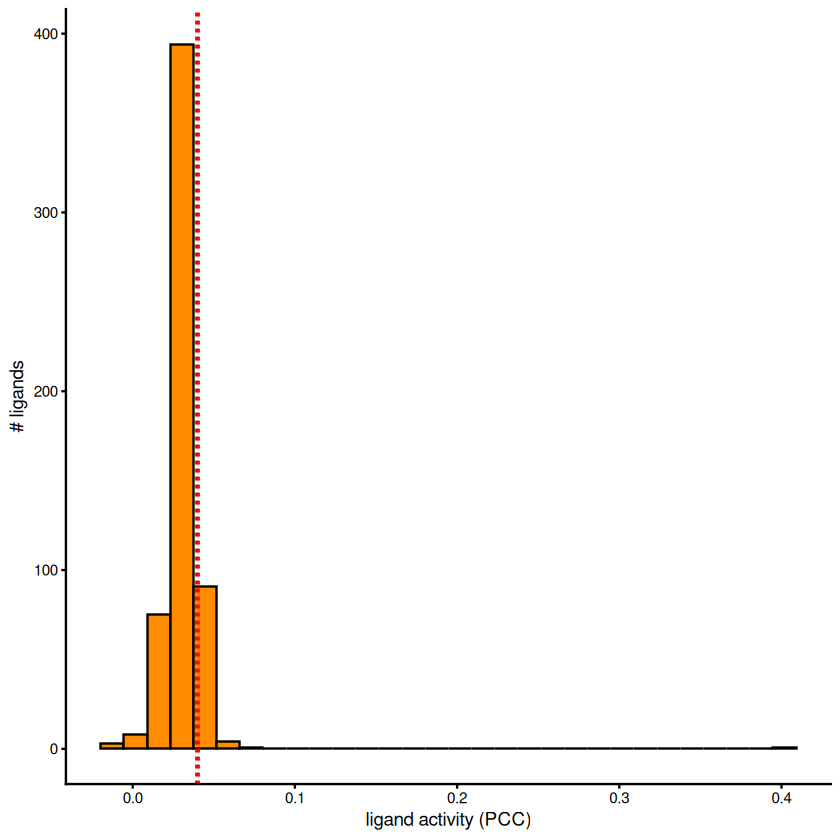

In [55]:
p_hist_lig_activity <- ggplot(ligand_activities, aes(x=aupr_corrected)) + 
  geom_histogram(color="black", fill="darkorange")  + 
  geom_vline(aes(xintercept=min(ligand_activities %>% top_n(50, aupr_corrected) %>% pull(aupr_corrected))),
             color="red", linetype="dashed", size=1) + 
  labs(x="ligand activity (PCC)", y = "# ligands") +
  theme_classic()

p_hist_lig_activity

In [56]:
best_upstream_ligands <- ligand_activities %>% top_n(51, aupr_corrected) %>% arrange(-aupr_corrected) %>% pull(test_ligand)

In [57]:
ggtheme <- function() {
  theme(
    axis.text = element_text(size = 20),
    axis.title = element_text(size = 20),
    text = element_text(size = 20, colour = "black"),
    legend.text = element_text(size = 20),
    legend.key.size =  unit(10, units = "points")
    
  )
}

Warning message:
“The `size` argument of `element_line()` is deprecated as of ggplot2 3.4.0.
ℹ Please use the `linewidth` argument instead.
ℹ The deprecated feature was likely used in the nichenetr package.
  Please report the issue at <https://github.com/saeyslab/nichenetr/issues>.”


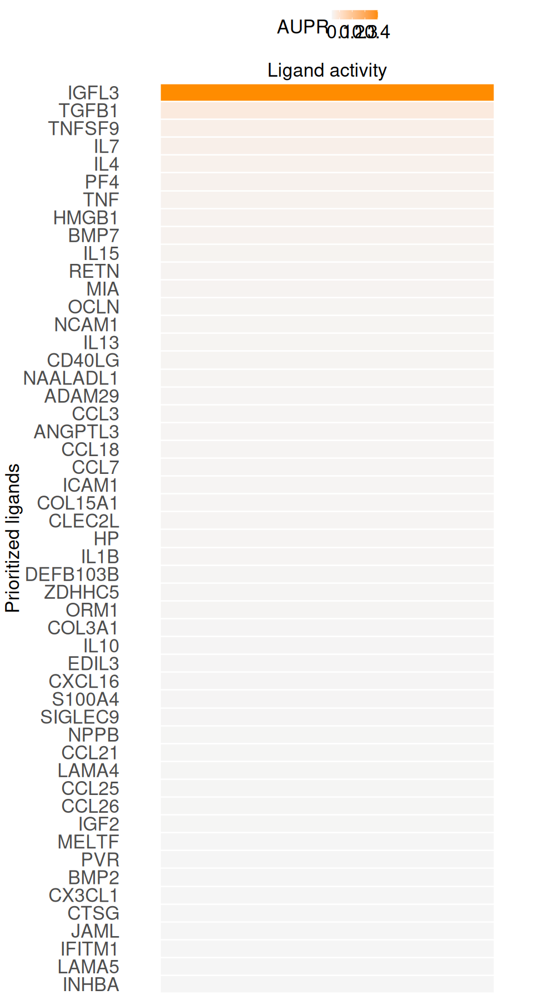

In [58]:
options(repr.plot.width = 8, repr.plot.height = 15)
vis_ligand_aupr <- ligand_activities %>% filter(test_ligand %in% best_upstream_ligands) %>%
  column_to_rownames("test_ligand") %>% select(aupr_corrected) %>% arrange(aupr_corrected) %>% as.matrix(ncol = 1)

(make_heatmap_ggplot(vis_ligand_aupr,
                     "Prioritized ligands", "Ligand activity", 
                     legend_title = "AUPR", color = "darkorange") + 
    theme(axis.text.x.top = element_blank()))  + ggtheme()

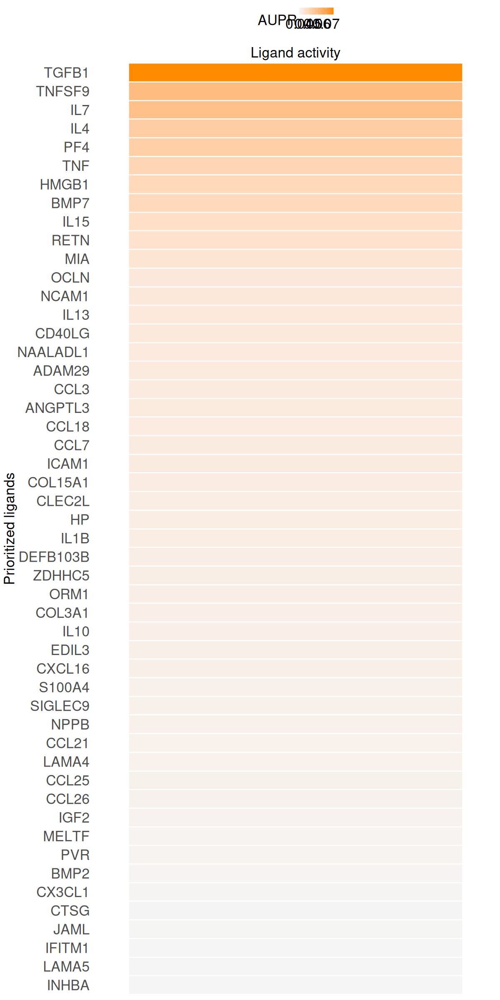

In [62]:
options(repr.plot.width = 10, repr.plot.height = 20)
vis_ligand_aupr <- ligand_activities %>% filter(test_ligand %in% best_upstream_ligands & test_ligand != "IGFL3") %>%
  column_to_rownames("test_ligand") %>% select(aupr_corrected) %>% arrange(aupr_corrected) %>% as.matrix(ncol = 1)

(make_heatmap_ggplot(vis_ligand_aupr,
                     "Prioritized ligands", "Ligand activity", 
                     legend_title = "AUPR", color = "darkorange") + 
    theme(axis.text.x.top = element_blank()))  + ggtheme()

# Thomas cohort

In [59]:
paths  <- list.files("data/published_data/thomas/", full.names = T)

In [60]:
dataset_names  <- gsub(list.files("data/published_data/thomas/", full.names = F), pattern = "\\.rds", replacement = "")

In [61]:
dataset_names

[1] "thomas_bcells_ad_genes"       "thomas_cd8tcells_ad_genes"   
 [3] "thomas_epicolonic_ad_genes"   "thomas_fibperi_ad_genes"     
 [5] "thomas_ilc_ad_genes"          "thomas_ilealepi_ad_genes"    
 [7] "thomas_merged_Ileum"          "thomas_myeloid_ad_genes"     
 [9] "thomas_plasmacells_ad_genes"  "thomas_seu_merged_aggregated"
[11] "thomas_vasc_ad_genes"

In [92]:
seu_list  <- list()

In [68]:
for(i in 1:9){
    seu  <-  readRDS(paths[i])
    seu$barcode  <- colnames(seu)
    if(ncol(seu)>10000){
    seu  <- subset(seu, barcode %in% sample(colnames(seu), size = 10000))
        }
    seu_list[[i]]  <- seu
}

In [66]:
seu_list

list()

In [ ]:
seu_list  <- merge(seu_list[1], c(seu_list[2], seu_list[3], seu_list[4], 
                                  seu_list[5], seu_list[6], seu_list[7], 
                                  seu_list[8], seu_list[9]))

In [63]:
thomas_cd4  <- readRDS("data/mapping_data_onto_predict/thomas_query.rds")

In [64]:
thomas_cd4$dataset  <- "CD4"

In [93]:
for(i in 1:9){
    seu  <-  readRDS(paths[i])
    seu$barcode  <- colnames(seu)
    if(ncol(seu)>2000){
    seu  <- subset(seu, barcode %in% sample(colnames(seu), size = 2000))
        }
    seu_list[[i]]  <- seu
}

In [94]:
seu_merged  <- merge(seu_list[[1]], c(seu_list[[2]], seu_list[[3]], seu_list[[4]], 
                                  seu_list[[5]], seu_list[[6]], seu_list[[7]], 
                                  seu_list[[8]], seu_list[[9]], thomas_cd4))

Warning message:
"Some cell names are duplicated across objects provided. Renaming to enforce unique cell names."


In [95]:
seu_merged  <- JoinLayers(seu_merged)

In [96]:
seu_merged$major  %>% table

.
                                B                  C3pos_fibroblast 
                             2217                               222 
                            CD4_T                             CD8_T 
                           146113                              1995 
                      Cycling_MNP                    Cycling_stroma 
                               86                                 2 
                               DC                       Endothelium 
                              672                                74 
                   Epi_fibroblast                        Fibroblast 
                              298                                80 
                            Glial                  Ileal_epithelium 
                               17                              2583 
               Innate_lymphocytes                     LP_fibroblast 
                             2126                               725 
                             Mas

In [97]:
seu_merged@meta.data  <- seu_merged@meta.data  %>% mutate(
    combinedMajorTypes_plus_cd4_ctl = if_else(major == "CD4_T", seurat_clusters, major))

In [98]:
seu_merged$seurat_clusters  %>% table

.
    0     1    10     2     3     4     5     6     7     8     9 
33745 26853    66 22627 19435 18114 13050 12565 11222  4770  1257 

In [99]:
seu_merged$combinedMajorTypes_plus_cd4_ctl  %>% table

.
                                0                                 1 
                            28547                             22455 
                                2                                 3 
                            20035                             17699 
                                4                                 5 
                            16880                             12130 
                                6                                 7 
                            11926                             10817 
                                8                                 9 
                             4490                              1134 
                                B                  C3pos_fibroblast 
                             2217                               222 
                            CD8_T                       Cycling_MNP 
                             1995                                86 
                   Cycling_strom

In [100]:
Idents(seu_merged)  <- seu_merged$combinedMajorTypes_plus_cd4_ctl

In [101]:
library(nichenetr)

In [102]:
receiver = "6"
expressed_genes_receiver <- get_expressed_genes(receiver, seu_merged, pct = 0.05)

In [ ]:
organism <- "human"

if(organism == "human"){
  lr_network <- readRDS(url("https://zenodo.org/record/7074291/files/lr_network_human_21122021.rds"))
  ligand_target_matrix <- readRDS(url("https://zenodo.org/record/7074291/files/ligand_target_matrix_nsga2r_final.rds"))
  weighted_networks <- readRDS(url("https://zenodo.org/record/7074291/files/weighted_networks_nsga2r_final.rds"))
} else if(organism == "mouse"){
  lr_network <- readRDS(url("https://zenodo.org/record/7074291/files/lr_network_mouse_21122021.rds"))
  ligand_target_matrix <- readRDS(url("https://zenodo.org/record/7074291/files/ligand_target_matrix_nsga2r_final_mouse.rds"))
  weighted_networks <- readRDS(url("https://zenodo.org/record/7074291/files/weighted_networks_nsga2r_final_mouse.rds"))

}

lr_network <- lr_network %>% distinct(from, to)
head(lr_network)

In [103]:
all_receptors <- unique(lr_network$to)  
expressed_receptors <- intersect(all_receptors, expressed_genes_receiver)

potential_ligands <- lr_network %>% filter(to %in% expressed_receptors) %>% pull(from) %>% unique()

In [104]:
seu_merged$major  %>% table

.
                                B                  C3pos_fibroblast 
                             2217                               222 
                            CD4_T                             CD8_T 
                           146113                              1995 
                      Cycling_MNP                    Cycling_stroma 
                               86                                 2 
                               DC                       Endothelium 
                              672                                74 
                   Epi_fibroblast                        Fibroblast 
                              298                                80 
                            Glial                  Ileal_epithelium 
                               17                              2583 
               Innate_lymphocytes                     LP_fibroblast 
                             2126                               725 
                             Mas

In [105]:
sender_celltypes <- levels(factor(seu_merged$combinedMajorTypes_plus_cd4_ctl))

# Use lapply to get the expressed genes of every sender cell type separately here
list_expressed_genes_sender <- sender_celltypes %>% unique() %>% lapply(get_expressed_genes, seu_merged, 0.05)
expressed_genes_sender <- list_expressed_genes_sender %>% unlist() %>% unique()

potential_ligands_focused <- intersect(potential_ligands, expressed_genes_sender) 

# Also check 
length(expressed_genes_sender)
## [1] 8492
length(potential_ligands)
## [1] 483
length(potential_ligands_focused)
## [1] 127

Warning message in asMethod(object):
"sparse->dense coercion: allocating vector of size 1.1 GiB"
integrated assay doesn't leave any cells, so it is removed

prediction.score.id assay doesn't leave any cells, so it is removed

integrated assay doesn't leave any cells, so it is removed

prediction.score.id assay doesn't leave any cells, so it is removed

integrated assay doesn't leave any cells, so it is removed

prediction.score.id assay doesn't leave any cells, so it is removed

integrated assay doesn't leave any cells, so it is removed

prediction.score.id assay doesn't leave any cells, so it is removed

integrated assay doesn't leave any cells, so it is removed

prediction.score.id assay doesn't leave any cells, so it is removed

integrated assay doesn't leave any cells, so it is removed

prediction.score.id assay doesn't leave any cells, so it is removed

integrated assay doesn't leave any cells, so it is removed

prediction.score.id assay doesn't leave any cells, so it is removed



[1] 14226

[1] 521

[1] 353

In [106]:
seu_merged$Disease  %>% table

.
     CD Healthy      UC 
  76045    5844   81815 

In [107]:
seu_merged$combinedMajorTypes_plus_cd4_ctl  %>% table

.
                                0                                 1 
                            28547                             22455 
                                2                                 3 
                            20035                             17699 
                                4                                 5 
                            16880                             12130 
                                6                                 7 
                            11926                             10817 
                                8                                 9 
                             4490                              1134 
                                B                  C3pos_fibroblast 
                             2217                               222 
                            CD8_T                       Cycling_MNP 
                             1995                                86 
                   Cycling_strom

In [108]:
condition_oi <-  "CD"
condition_reference <- "Healthy"

seurat_obj_receiver <- subset(seu_merged, combinedMajorTypes_plus_cd4_ctl %in% c(0:9))

DE_table_receiver <-  FindMarkers(object = seurat_obj_receiver,
                                  ident.1 = condition_oi, ident.2 = condition_reference,
                                  group.by = "Disease",
                                  min.pct = 0.05) %>% rownames_to_column("gene")

geneset_oi <- DE_table_receiver %>% filter(p_val_adj <= 0.05 & abs(avg_log2FC) >= 0.25) %>% pull(gene)
geneset_oi <- geneset_oi %>% .[. %in% rownames(ligand_target_matrix)]

In [109]:
background_expressed_genes <- expressed_genes_receiver %>% .[. %in% rownames(ligand_target_matrix)]

length(background_expressed_genes)
## [1] 3476
length(geneset_oi)
## [1] 260

[1] 5424

[1] 507

In [110]:
ligand_activities <- predict_ligand_activities(geneset = geneset_oi,
                                               background_expressed_genes = background_expressed_genes,
                                               ligand_target_matrix = ligand_target_matrix,
                                               potential_ligands = potential_ligands)

In [111]:
ligand_activities <- ligand_activities %>% arrange(-aupr_corrected) %>% arrange(desc(aupr_corrected))
ligand_activities

test_ligand,auroc,aupr,aupr_corrected,pearson
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
IFNG,0.5676661,0.1486895,0.05579832,0.12076471
IL21,0.5585169,0.1424049,0.04951370,0.11677961
IL27,0.5493581,0.1410163,0.04812517,0.11055140
IL4,0.5623011,0.1409460,0.04805485,0.10144980
IL1B,0.5500425,0.1387219,0.04583070,0.10567669
ANGPT2,0.5332487,0.1369225,0.04403130,0.10147521
OSM,0.5494732,0.1367496,0.04385848,0.09137457
IL10,0.5584185,0.1356623,0.04277113,0.10232674
JAM2,0.5639587,0.1352277,0.04233657,0.07660937


`stat_bin()` using `bins = 30`. Pick better value with `binwidth`.


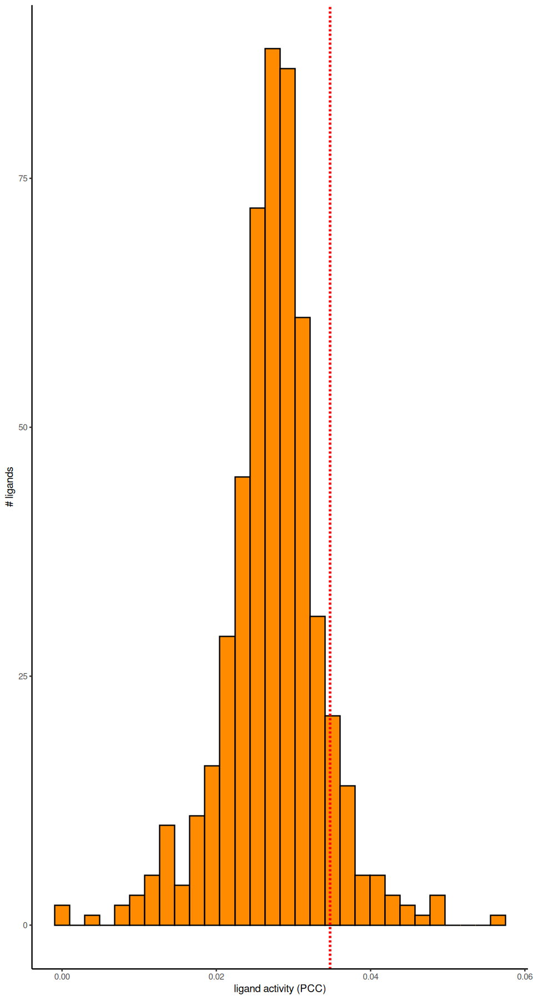

In [112]:
p_hist_lig_activity <- ggplot(ligand_activities, aes(x=aupr_corrected)) + 
  geom_histogram(color="black", fill="darkorange")  + 
  geom_vline(aes(xintercept=min(ligand_activities %>% top_n(50, aupr_corrected) %>% pull(aupr_corrected))),
             color="red", linetype="dashed", size=1) + 
  labs(x="ligand activity (PCC)", y = "# ligands") +
  theme_classic()

p_hist_lig_activity

In [113]:
best_upstream_ligands <- ligand_activities %>% top_n(50, aupr_corrected) %>% arrange(-aupr_corrected) %>% pull(test_ligand)

In [114]:
ggtheme <- function() {
  theme(
    axis.text = element_text(size = 20),
    axis.title = element_text(size = 20),
    text = element_text(size = 20, colour = "black"),
    legend.text = element_text(size = 20),
    legend.key.size =  unit(10, units = "points")
    
  )
}


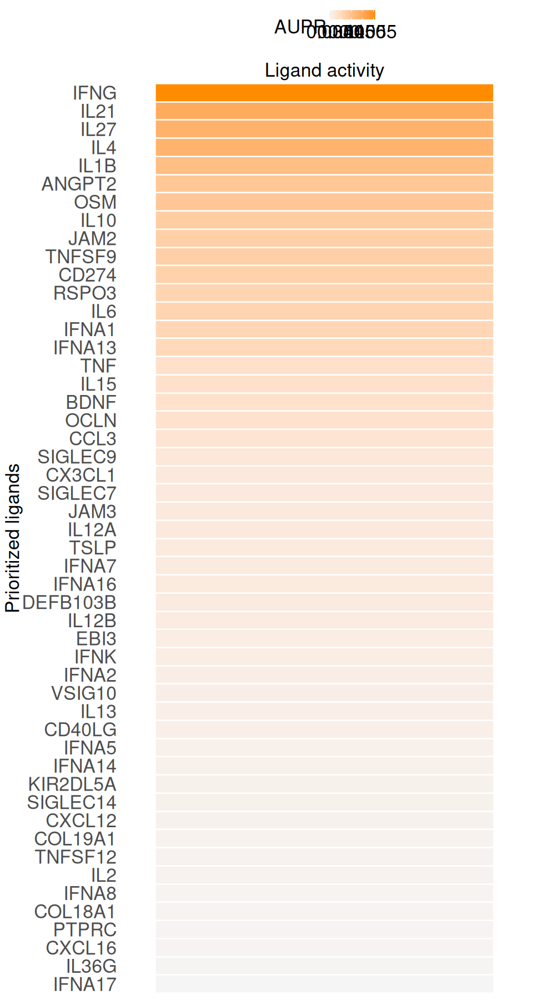

In [115]:
options(repr.plot.width = 8, repr.plot.height = 15)
vis_ligand_aupr <- ligand_activities %>% filter(test_ligand %in% best_upstream_ligands) %>%
  column_to_rownames("test_ligand") %>% select(aupr_corrected) %>% arrange(aupr_corrected) %>% as.matrix(ncol = 1)

(make_heatmap_ggplot(vis_ligand_aupr,
                     "Prioritized ligands", "Ligand activity", 
                     legend_title = "AUPR", color = "darkorange") + 
    theme(axis.text.x.top = element_blank())) + ggtheme()

In [116]:
saveRDS(seu_merged, "data/published_data/thomas/thomas_merged_subset_for_nichenet_2000.rds")

## Il27 expression

In [2]:
paths  <- list.files("data/published_data/thomas/", full.names = T)

In [3]:
dataset_names  <- gsub(list.files("data/published_data/thomas/", full.names = F), pattern = "\\.rds", replacement = "")

In [4]:
dataset_names

[1] "thomas_bcells_ad_genes"                
 [2] "thomas_cd8tcells_ad_genes"             
 [3] "thomas_epicolonic_ad_genes"            
 [4] "thomas_fibperi_ad_genes"               
 [5] "thomas_ilc_ad_genes"                   
 [6] "thomas_ilealepi_ad_genes"              
 [7] "thomas_merged_Ileum"                   
 [8] "thomas_merged_subset_for_nichenet_2000"
 [9] "thomas_merged_subset_for_nichenet"     
[10] "thomas_myeloid_ad_genes"               
[11] "thomas_plasmacells_ad_genes"           
[12] "thomas_seu_merged_aggregated"          
[13] "thomas_vasc_ad_genes"

In [7]:
dataset_names  <- dataset_names[!grepl(dataset_names, pattern = "merged")]

In [8]:
seu_list  <- list()

In [10]:
paths

[1] "data/published_data/thomas//thomas_bcells_ad_genes.rds"                
 [2] "data/published_data/thomas//thomas_cd8tcells_ad_genes.rds"             
 [3] "data/published_data/thomas//thomas_epicolonic_ad_genes.rds"            
 [4] "data/published_data/thomas//thomas_fibperi_ad_genes.rds"               
 [5] "data/published_data/thomas//thomas_ilc_ad_genes.rds"                   
 [6] "data/published_data/thomas//thomas_ilealepi_ad_genes.rds"              
 [7] "data/published_data/thomas//thomas_merged_Ileum.rds"                   
 [8] "data/published_data/thomas//thomas_merged_subset_for_nichenet_2000.rds"
 [9] "data/published_data/thomas//thomas_merged_subset_for_nichenet.rds"     
[10] "data/published_data/thomas//thomas_myeloid_ad_genes.rds"               
[11] "data/published_data/thomas//thomas_plasmacells_ad_genes.rds"           
[12] "data/published_data/thomas//thomas_seu_merged_aggregated.rds"          
[13] "data/published_data/thomas//thomas_vasc_ad_genes.rds"

In [11]:
paths  <- paths[!grepl(paths, pattern = "merged")]

In [12]:
for(i in 1:9){
    seu  <-  readRDS(paths[i])
    md  <- seu@meta.data
    md$IL_27  <- seu@assays$RNA@layers$data[which(rownames(seu@assays$RNA)=="IL27"),]
    md$dataset  <- dataset_names[i]
    if(i == 1){
        md_all  <- md
    } else {
        md_all  <- rbind(md_all, md)
    }
}

In [13]:
summary(md_all$IL_27)

    Min.  1st Qu.   Median     Mean  3rd Qu.     Max. 
0.000000 0.000000 0.000000 0.001436 0.000000 3.421968 

In [14]:
colnames(md)

[1] "orig.ident"         "nCount_RNA"         "nFeature_RNA"      
 [4] "sample_id"          "Patient"            "Disease"           
 [7] "Site"               "Treatment"          "Disease_duration"  
[10] "Inflammation"       "Age"                "Gender"            
[13] "Ethnicity"          "Inflammation_score" "Ileum_vs_Colon"    
[16] "LibraryType"        "CellsLoaded"        "Match"             
[19] "Batch"              "doublet_scores"     "predicted_doublets"
[22] "n_genes_by_counts"  "total_counts"       "total_counts_mt"   
[25] "pct_counts_mt"      "total_counts_rp"    "pct_counts_rp"     
[28] "total_counts_hb"    "pct_counts_hb"      "total_counts_ig"   
[31] "pct_counts_ig"      "S_score"            "G2M_score"         
[34] "phase"              "cellbarcode"        "diff"              
[37] "final_analysis"     "minor"              "major"             
[40] "sub_bucket"         "bucket"             "Remission_status"  
[43] "bc"                 "RNA_snn_res.0.3"    "seurat_clusters"   
[46] "dataset"            "IL_27"

In [15]:
library(dplyr)

In [16]:
md_all  %>% group_by(sample_id, Patient, Disease, Site, Treatment, Inflammation, major)  %>% 
summarise(avg_IL27 = mean(IL_27))

`summarise()` has grouped output by 'sample_id', 'Patient', 'Disease', 'Site',
'Treatment', 'Inflammation'. You can override using the `.groups` argument.


sample_id,Patient,Disease,Site,Treatment,Inflammation,major,avg_IL27
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>
CID003352-2,UC1,UC,Rectum,Post,Inflamed,B,0.0000000000
CID003352-2,UC1,UC,Rectum,Post,Inflamed,C3pos_fibroblast,0.0000000000
CID003352-2,UC1,UC,Rectum,Post,Inflamed,CD8_T,0.0000000000
CID003352-2,UC1,UC,Rectum,Post,Inflamed,Cycling_MNP,0.0786715958
CID003352-2,UC1,UC,Rectum,Post,Inflamed,Cycling_stroma,0.0000000000
CID003352-2,UC1,UC,Rectum,Post,Inflamed,DC,0.0480500316
CID003352-2,UC1,UC,Rectum,Post,Inflamed,Endothelium,0.0000000000
CID003352-2,UC1,UC,Rectum,Post,Inflamed,Epi_fibroblast,0.0000000000
CID003352-2,UC1,UC,Rectum,Post,Inflamed,Fibroblast,0.0000000000


In [17]:
library(ggplot2)
ggtheme <- function() {
  theme(
    axis.text = element_text(size = 20),
    axis.title = element_text(size = 20),
    text = element_text(size = 20, colour = "black"),
    legend.text = element_text(size = 20),
    legend.key.size =  unit(10, units = "points")
    
  )
}

`summarise()` has grouped output by 'sample_id', 'Patient', 'Disease', 'Site',
'Treatment', 'Inflammation'. You can override using the `.groups` argument.


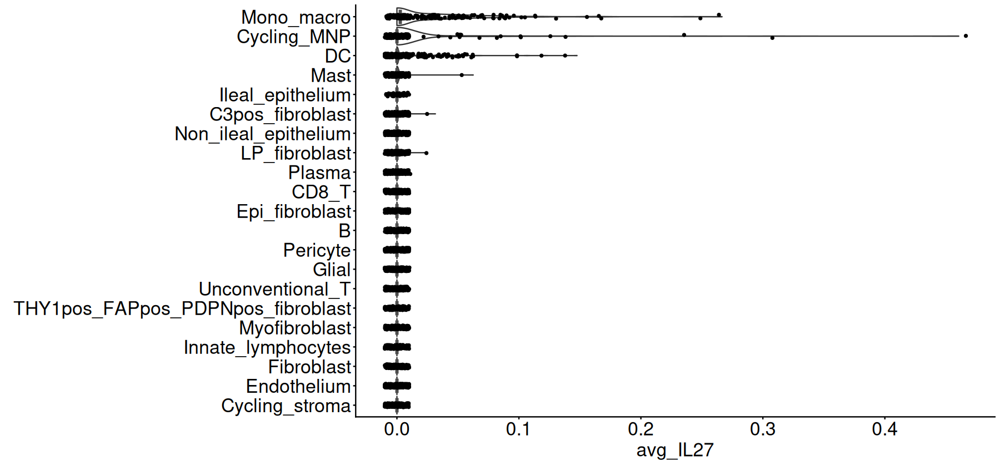

In [18]:
options(repr.plot.width = 15, repr.plot.height = 7)
md_all  %>% group_by(sample_id, Patient, Disease, Site, Treatment, Inflammation, major)  %>% 
summarise(avg_IL27 = mean(IL_27))  %>% 
ggplot(aes(x = reorder(major, X = avg_IL27, FUN = mean, decreasing = F), y = avg_IL27)) +
geom_violin(alpha = 0.3, scale = "width") +
  stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
geom_jitter(width = 0.1, height = 0.01, size = 1) + theme_classic() + ggtheme() + coord_flip() + xlab("")

`summarise()` has grouped output by 'sample_id', 'Patient', 'Disease', 'Site',
'Treatment', 'Inflammation'. You can override using the `.groups` argument.


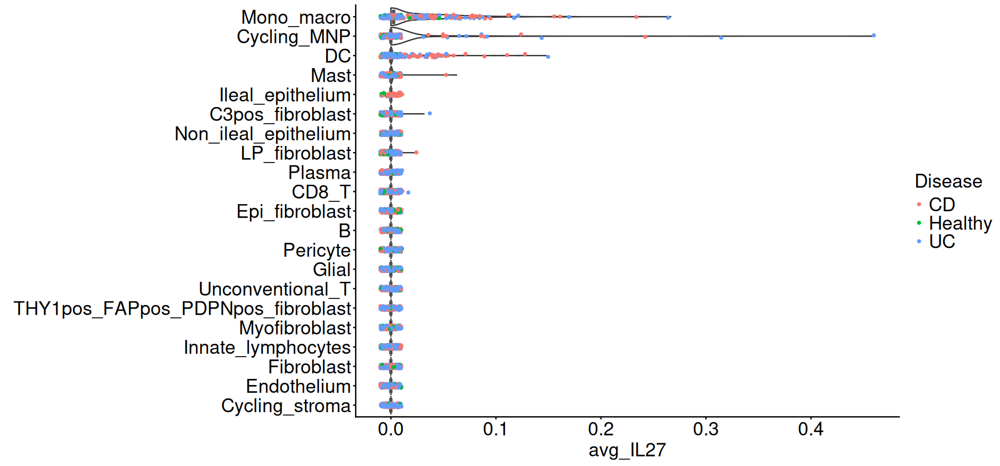

In [19]:
options(repr.plot.width = 15, repr.plot.height = 7)
md_all  %>% group_by(sample_id, Patient, Disease, Site, Treatment, Inflammation, major)  %>% 
summarise(avg_IL27 = mean(IL_27))  %>% 
ggplot(aes(x = reorder(major, X = avg_IL27, FUN = mean, decreasing = F), y = avg_IL27)) +
geom_violin(alpha = 0.3, scale = "width") +
  stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
geom_jitter(width = 0.1, height = 0.01, size = 1, aes(color = Disease)) + theme_classic() + ggtheme() + coord_flip() + xlab("")

`summarise()` has grouped output by 'sample_id', 'Patient', 'Disease', 'Site',
'Treatment', 'Inflammation'. You can override using the `.groups` argument.
Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”


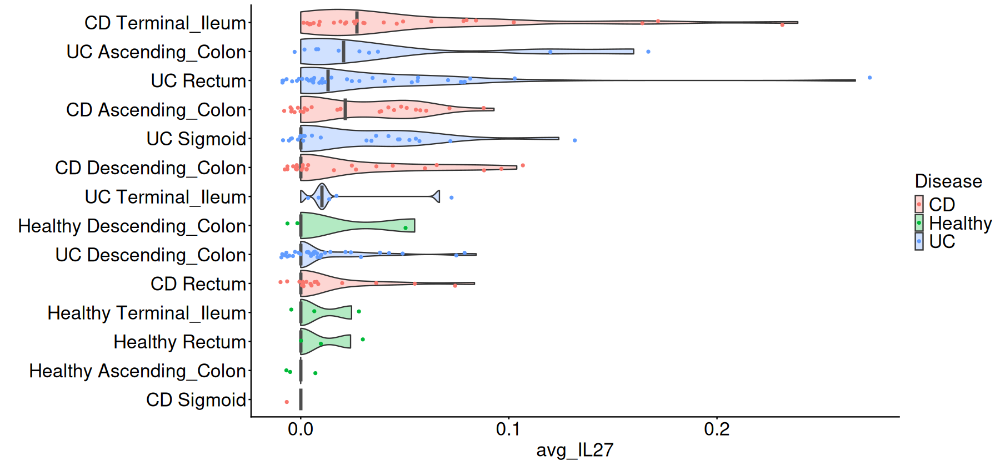

In [20]:
options(repr.plot.width = 15, repr.plot.height = 7)
md_all  %>% group_by(sample_id, Patient, Disease, Site, Treatment, Inflammation, major)  %>% 
summarise(avg_IL27 = mean(IL_27))  %>% 
dplyr::filter(major == "Mono_macro")  %>% 
mutate(Disease_Site = paste(Disease, Site))  %>% 
ggplot(aes(x = reorder(Disease_Site, X = avg_IL27, FUN = mean, decreasing = F), y = avg_IL27)) +
geom_violin(alpha = 0.3, scale = "width", aes(fill = Disease)) +
  stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
geom_jitter(width = 0.1, height = 0.01, size = 1, aes(color = Disease)) + theme_classic() + ggtheme() + coord_flip() + xlab("")

`summarise()` has grouped output by 'sample_id', 'Patient', 'Disease', 'Site',
'Treatment', 'Inflammation'. You can override using the `.groups` argument.


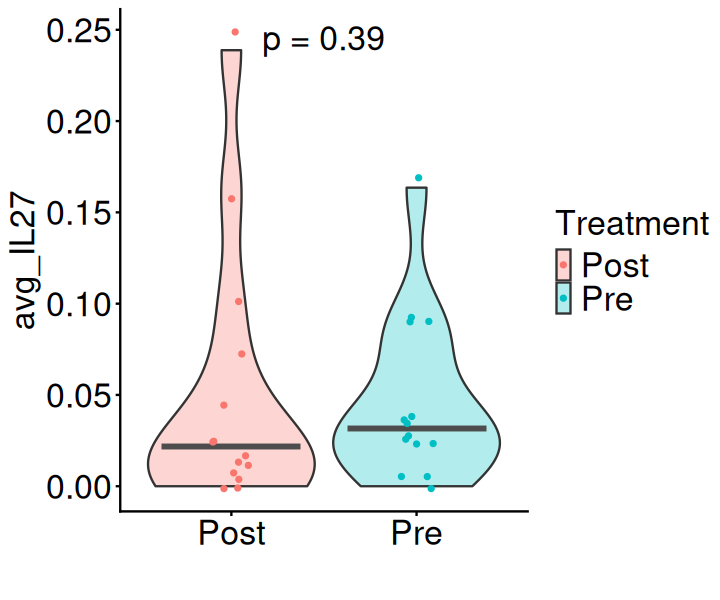

In [21]:
options(repr.plot.width = 6, repr.plot.height = 5)
md_all  %>% group_by(sample_id, Patient, Disease, Site, Treatment, Inflammation, major)  %>% 
summarise(avg_IL27 = mean(IL_27))  %>% 
dplyr::filter(major == "Mono_macro")  %>% 
mutate(Disease_Site = paste(Disease, Site))  %>% 
dplyr::filter(Disease_Site == "CD Terminal_Ileum")  %>% 
ggplot(aes(x = Treatment, y = avg_IL27)) +
geom_violin(alpha = 0.3, scale = "width", aes(fill = Treatment)) +
  stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
geom_jitter(width = 0.1, height = 0.01, size = 1, aes(color = Treatment)) + theme_classic() + ggtheme() + xlab("") +
ggpubr::stat_compare_means(label = "p.format", size = 7, label.x = 1.3)

In [22]:
colnames(md_all)

[1] "orig.ident"         "nCount_RNA"         "nFeature_RNA"      
 [4] "sample_id"          "Patient"            "Disease"           
 [7] "Site"               "Treatment"          "Disease_duration"  
[10] "Inflammation"       "Age"                "Gender"            
[13] "Ethnicity"          "Inflammation_score" "Ileum_vs_Colon"    
[16] "LibraryType"        "CellsLoaded"        "Match"             
[19] "Batch"              "doublet_scores"     "predicted_doublets"
[22] "n_genes_by_counts"  "total_counts"       "total_counts_mt"   
[25] "pct_counts_mt"      "total_counts_rp"    "pct_counts_rp"     
[28] "total_counts_hb"    "pct_counts_hb"      "total_counts_ig"   
[31] "pct_counts_ig"      "S_score"            "G2M_score"         
[34] "phase"              "cellbarcode"        "diff"              
[37] "final_analysis"     "minor"              "major"             
[40] "sub_bucket"         "bucket"             "Remission_status"  
[43] "bc"                 "RNA_snn_res.0.3"    "seurat_clusters"   
[46] "dataset"            "IL_27"

`summarise()` has grouped output by 'sample_id', 'Patient', 'Disease', 'Site',
'Treatment', 'Inflammation', 'major'. You can override using the `.groups`
argument.


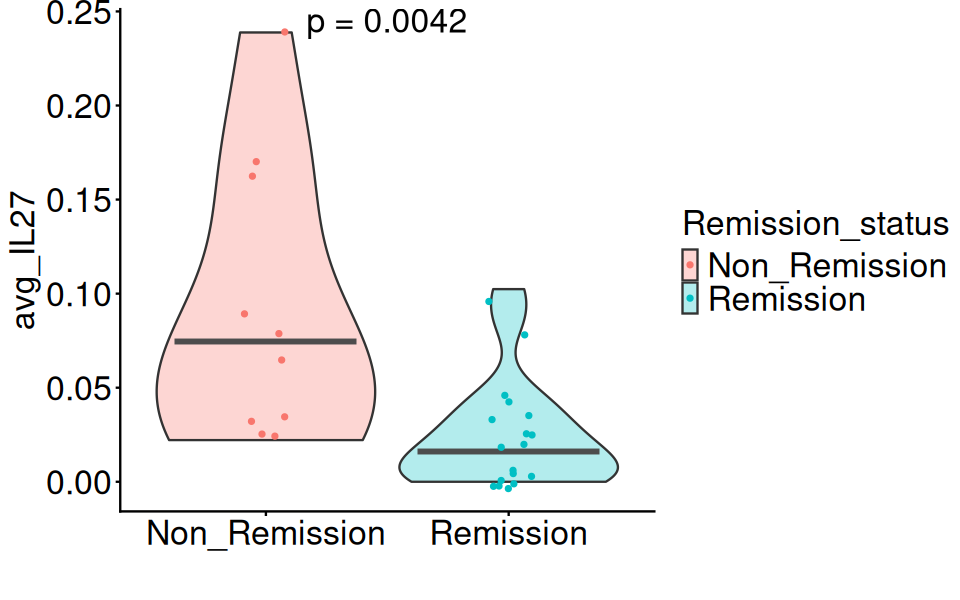

In [27]:
###### options(repr.plot.width = 8, repr.plot.height = 5)
md_all  %>% group_by(sample_id, Patient, Disease, Site, Treatment, Inflammation, major, Remission_status)  %>% 
summarise(avg_IL27 = mean(IL_27))  %>% 
dplyr::filter(major == "Mono_macro")  %>% 
mutate(Disease_Site = paste(Disease, Site))  %>% 
dplyr::filter(Disease_Site == "CD Terminal_Ileum")  %>% 
ggplot(aes(x = Remission_status, y = avg_IL27)) +
geom_violin(alpha = 0.3, scale = "width", aes(fill = Remission_status)) +
  stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
geom_jitter(width = 0.1, height = 0.01, size = 1, aes(color = Remission_status)) + theme_classic() + ggtheme() + xlab("") +
ggpubr::stat_compare_means(label = "p.format", size = 7, label.x = 1.3) 

In [33]:
md_all  %>%
mutate(Disease_Site = paste(Disease, Site))  %>% 
dplyr::filter(Disease_Site == "CD Terminal_Ileum")  %>% 
group_by(Remission_status, Treatment, Patient)  %>% tally()  %>% 
dplyr::select(-n)  %>% ungroup()  %>% 
group_by(Remission_status, Treatment)  %>% tally() 

Remission_status,Treatment,n
<chr>,<chr>,<int>
Non_Remission,Post,5
Non_Remission,Pre,5
Remission,Post,9
Remission,Pre,9


`summarise()` has grouped output by 'sample_id', 'Patient', 'Disease', 'Site',
'Treatment', 'Inflammation', 'major'. You can override using the `.groups`
argument.


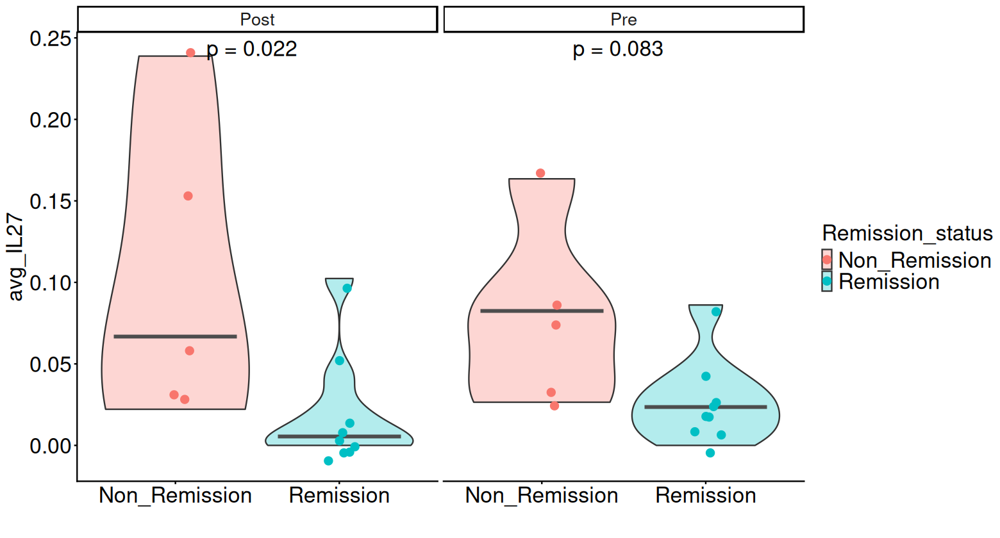

In [133]:
options(repr.plot.width = 13, repr.plot.height = 7)
md_all  %>% group_by(sample_id, Patient, Disease, Site, Treatment, Inflammation, major, Remission_status)  %>% 
summarise(avg_IL27 = mean(IL_27))  %>% 
dplyr::filter(major == "Mono_macro")  %>% 
mutate(Disease_Site = paste(Disease, Site))  %>% 
dplyr::filter(Disease_Site == "CD Terminal_Ileum")  %>% 
ggplot(aes(x = Remission_status, y = avg_IL27)) +
geom_violin(alpha = 0.3, scale = "width", aes(fill = Remission_status)) +
  stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
facet_wrap(~Treatment) +
geom_jitter(width = 0.1, height = 0.01, size = 3, aes(color = Remission_status)) + theme_classic() + ggtheme() + xlab("") +
ggpubr::stat_compare_means(label = "p.format", size = 7, label.x = 1.3) 

In [134]:
ggsave("figures/thomas/IL27_myeloid_cells.svg", width = 16, height = 9, units = "cm")

`summarise()` has grouped output by 'sample_id', 'Patient', 'Disease', 'Site',
'Treatment', 'Inflammation'. You can override using the `.groups` argument.


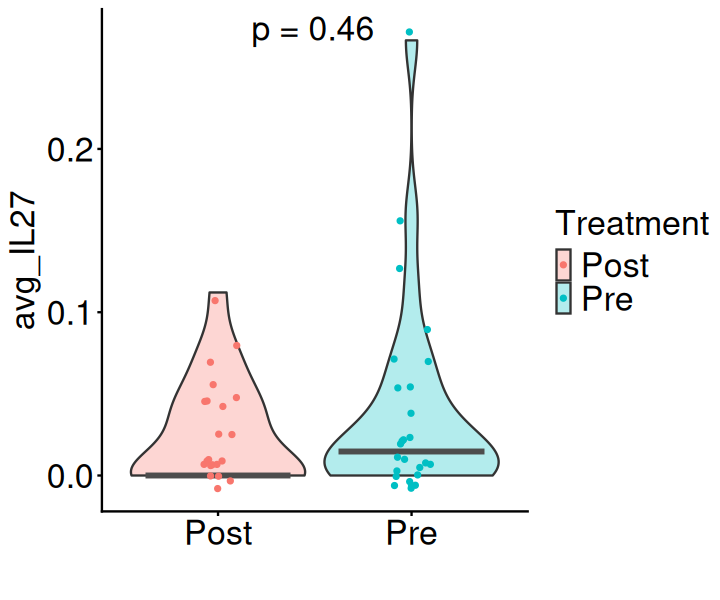

In [24]:
options(repr.plot.width = 6, repr.plot.height = 5)
md_all  %>% group_by(sample_id, Patient, Disease, Site, Treatment, Inflammation, major)  %>% 
summarise(avg_IL27 = mean(IL_27))  %>% 
dplyr::filter(major == "Mono_macro")  %>% 
mutate(Disease_Site = paste(Disease, Site))  %>% 
dplyr::filter(Disease_Site %in% c("UC Ascending_Colon" , "UC Rectum"))  %>% 
ggplot(aes(x = Treatment, y = avg_IL27)) +
geom_violin(alpha = 0.3, scale = "width", aes(fill = Treatment)) +
  stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
geom_jitter(width = 0.1, height = 0.01, size = 1, aes(color = Treatment)) + theme_classic() + ggtheme() + xlab("") +
ggpubr::stat_compare_means(label = "p.format", size = 7, label.x = 1.3)

`summarise()` has grouped output by 'sample_id', 'Patient', 'Disease', 'Site',
'Treatment', 'Inflammation', 'Remission_status'. You can override using the
`.groups` argument.


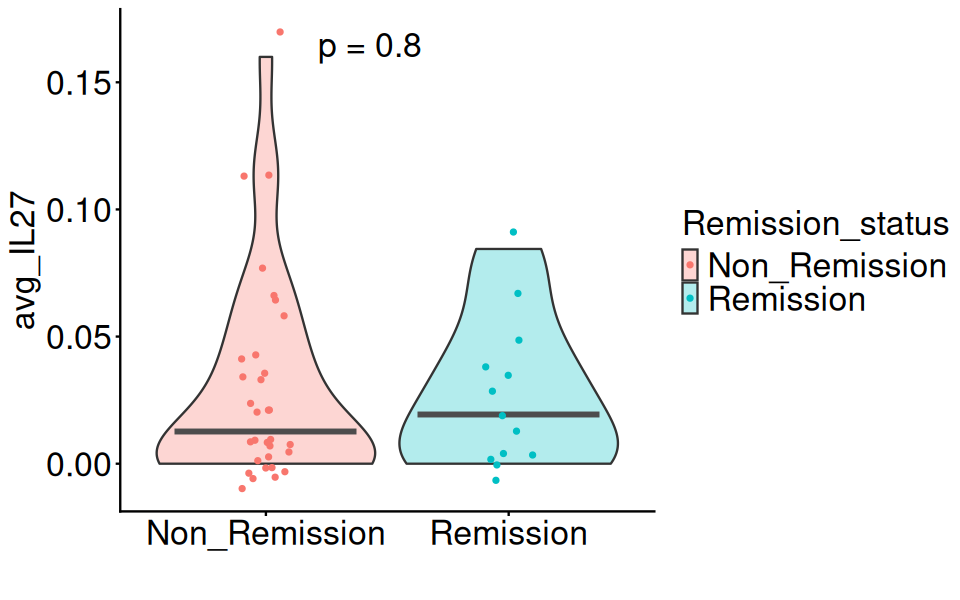

In [25]:
options(repr.plot.width = 8, repr.plot.height = 5)
md_all  %>% group_by(sample_id, Patient, Disease, Site, Treatment, Inflammation, Remission_status, major)  %>% 
summarise(avg_IL27 = mean(IL_27))  %>% 
dplyr::filter(major == "Mono_macro")  %>% 
mutate(Disease_Site = paste(Disease, Site))  %>% 
dplyr::filter(Disease_Site %in% c("UC Ascending_Colon" , "UC Rectum") & Remission_status != "Not_avail")  %>% 
ggplot(aes(x = Remission_status, y = avg_IL27)) +
geom_violin(alpha = 0.3, scale = "width", aes(fill = Remission_status)) +
  stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
geom_jitter(width = 0.1, height = 0.01, size = 1, aes(color = Remission_status)) + theme_classic() + ggtheme() + xlab("") +
ggpubr::stat_compare_means(label = "p.format", size = 7, label.x = 1.3)

# Ranks from three datasets

In [97]:
ligands_5p  <- c(best_upstream_ligands[2:51])
ligands_3p  <- c('IFNB1', 'IL27', 'IFNL3', 'IFNG', 'IFNL1', 'IL3', 'IFNA1', 'EBI3', 'IFNA16', 'IFNA5', 'IFNA21', 'IFNL2', 'IFNE', 'IFNA2', 'IFNA4', 'IFNA7', 'IFNA14', 'LTB', 'IL12A', 'IL21', 'IFNK', 'IFNA10', 'IFNL4', 'IFNA8', 'IL24', 'IFNA17', 'TSLP', 'IL10', 'IL12B', 'IL26', 'OSM', 'IFNA6', 'IL23A', 'TNF', 'IL11', 'IL22', 'IL36G', 'SIGLEC6', 'IL6', 'IL9', 'CLCF1', 'PTPRC', 'SIGLEC14', 'IFNA13', 'CXCL12', 'VSIG10', 'HLA-DRB5', 'IL4', 'CNTF', 'LIF', 'IFNW1', 'TGFB1', 'IL7', 'IFITM1', 'IL18', 'IL13', 'BTLA', 'UCN3', 'TNFSF4', 'CCL2', 'IL15', 'IL37', 'HLA-G', 'JAM2', 'CD40', 'CRLF1', 'TNFSF12', 'LTA', 'TNFSF14', 'BMP8A', 'HLA-E', 'NECTIN3', 'MMP1', 'TGFB2', 'LAMA2', 'TGM2', 'TNFRSF14', 'SIRPA', 'MMP9', 'TIMP1', 'COL12A1', 'TCN1', 'SELP', 'SELE', 'HLA-DMB', 'IL1F10', 'VTCN1', 'SFTPD', 'RECK', 'CLEC4G', 'CD40LG', 'KIR2DL5A', 'MICB', 'COL26A1', 'SIGLEC9', 'ADAM17', 'COL4A1', 'CCL11', 'COL10A1', 'ICOSLG', 'CD28', 'TNFSF13', 'HLA-A', 'CD86', 'SIGLEC1', 'HBEGF', 'MDK', 'CCL3', 'COL5A1', 'LRRN2', 'UCN2', 'CD72', 'B2M', 'CCL5', 'FASLG', 'CCL3L1', 'CD70', 'TNFSF18', 'SDC2', 'ZG16B', 'COL18A1', 'CLEC2D', 'MATN1', 'ANGPT2', 'SIGLEC7', 'CCL20', 'HLA-B', 'HMGB1', 'DEFB103B', 'ALCAM', 'CD5L', 'MUC7')[1:50]
ligands_thomas  <- c(
  "IFNG", "IL27", "IL21", "IL4", "IL1B", "ANGPT2", "IFNA1", "IL10", "OSM", "TNFSF9", "JAM2", "IL6","CD274", "RSPO3", "IFNA13", 
  "TNF","TSLP","BDNF", "IL15", "IL12A", "CCL3", "IFNA7", "SIGLEC9", "IFNA16", "SIGLEC7", "OCLN", "IFNB1", "IFNK", "IL21B", 
    "EBI3", "IFNA2",
  "CX3CL1", "DEFB103B", "JAM3", "IFNA5","IFNA14", "IL13", "VSIG10", "CD40LG", "CXCL12", "SIGLEC14", "IFNA8", "IL2",
  "PTPRC", "LILRB2", "IFNA4", "KIR2DL5A", "TNFSF12", "COL19A1", "IL36LG")

In [98]:
length(ligands_3p)
length(ligands_5p)
length(ligands_thomas)


[1] 50

[1] 50

[1] 50

In [103]:
ligands_all  <- data.frame(ligand = c(ligands_3p, ligands_5p, ligands_thomas),
                           rank = c(1:50,1:50,1:50),
                          dataset = c(rep("Predict_3p", times = 50), 
                                      rep("Predict_5p", times = 50), 
                                      rep("Thomas", times = 50)))

In [105]:
ligands_all  %>% pivot_wider(names_from = dataset, values_from = rank, values_fill = 100)  

ligand,Predict_3p,Predict_5p,Thomas
<chr>,<int>,<int>,<int>
IFNB1,1,7,27
IL27,2,3,2
IFNL3,3,5,100
IFNG,4,1,1
IFNL1,5,9,100
IL3,6,100,100
IFNA1,7,4,7
EBI3,8,100,30
IFNA16,9,20,24


In [110]:
ligands_all  %>% pivot_wider(names_from = dataset, values_from = rank, values_fill = 100)  %>% 
pivot_longer(!ligand, names_to = "dataset", values_to = "rank")  %>% 
group_by(ligand)  %>% 
summarise(mean_rank = mean(rank))  %>% 
arrange(mean_rank)

ligand,mean_rank
<chr>,<dbl>
IFNG,2.000000
IL27,2.333333
IFNA1,6.000000
IFNB1,11.666667
IL21,15.333333
IL10,16.000000
IFNA16,17.666667
IFNA7,18.333333
TNF,19.333333


In [ ]:
ligands_intersection = intersect(intersect(ligands_3p, ligands_5p), ligands_thomas)

ligands_intersection

In [113]:
ligands_all  %>% dplyr::filter(ligand %in% ligands_intersection)  %>% 
group_by(ligand)  %>% 
summarise(mean_rank = mean(rank))  %>% 
arrange(mean_rank)

ligand,mean_rank
<chr>,<dbl>
IFNG,2.000000
IL27,2.333333
IFNA1,6.000000
IFNB1,11.666667
IL21,15.333333
IL10,16.000000
IFNA16,17.666667
IFNA7,18.333333
TNF,19.333333


In [118]:
ligands_all  %>% dplyr::filter(ligand %in% ligands_intersection)  %>% 
pivot_wider(names_from = dataset, values_from = rank, values_fill = 100)   %>% 
mutate(avg_rank = rowMeans(across(c(Predict_3p, Predict_5p, Thomas))))  %>% 
arrange(avg_rank)

ligand,Predict_3p,Predict_5p,Thomas,avg_rank
<chr>,<int>,<int>,<int>,<dbl>
IFNG,4,1,1,2.000000
IL27,2,3,2,2.333333
IFNA1,7,4,7,6.000000
IFNB1,1,7,27,11.666667
IL21,20,23,3,15.333333
IL10,28,12,8,16.000000
IFNA16,9,20,24,17.666667
IFNA7,16,17,22,18.333333
TNF,34,8,16,19.333333


In [120]:
lig_test  <- ligands_all  %>% dplyr::filter(ligand %in% ligands_intersection)  %>% 
pivot_wider(names_from = dataset, values_from = rank, values_fill = 100)   %>% 
mutate(avg_rank = rowMeans(across(c(Predict_3p, Predict_5p, Thomas))))  %>% 
arrange(avg_rank)  %>% 
dplyr::select(-avg_rank)  %>% 
column_to_rownames("ligand")  %>% 
as.matrix()

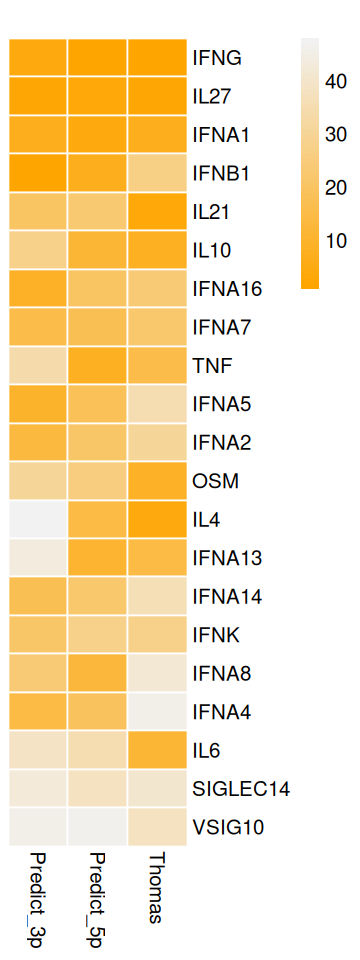

In [129]:
options(repr.plot.width = 3, repr.plot.height = 8)
pheatmap::pheatmap(lig_test, main = "", 
         scale = "none", cluster_cols = F, cluster_rows = F,
        color=colorRampPalette(c("orange", "grey95"))(50), 
         border_color = "white",
                  fontsize = 12)

In [131]:
seu_ile_lp_filt$cell_type_lvl1  %>% table

.
               B Cells                    DCs      Endothelial Cells 
                133605                   5466                  12220 
Enterochromaffin cells            Enterocytes  Enteroendocrine cells 
                   221                  55076                    393 
            Epithelial            Fibroblasts                   Glia 
                 41991                  30344                   1749 
          Goblet Cells                   ILCs            Macrophages 
                 10282                   5227                  30493 
                  Mast                     NK           Paneth Cells 
                 17045                  11046                   6067 
                  pDCs              Pericytes           Plasma Cells 
                  1791                   1708                  80669 
         Proliferating                T Cells             Tuft Cells 
                  4554                 222624                    249 

In [132]:
colnames(seu_ile_lp_filt@meta.data)

[1] "orig.ident"                      "nCount_RNA"                     
 [3] "nFeature_RNA"                    "bc"                             
 [5] "data_folder"                     "data_folder2"                   
 [7] "sample"                          "diagnosis"                      
 [9] "subgroup_primary"                "subgroup_secondary"             
[11] "subgroup_tertiary"               "Rome_coarse"                    
[13] "Rome_classification"             "antitnf_response"               
[15] "participant_id"                  "timepoint"                      
[17] "age"                             "sex"                            
[19] "site"                            "tissue"                         
[21] "layer"                           "prime"                          
[23] "version_10x"                     "sample_old"                     
[25] "data_type"                       "seq_run"                        
[27] "collection_purpose"              "collection_date"                
[29] "days"                            "antitnf"                        
[31] "antitnf_repeat"                  "duo_inflammation"               
[33] "ile_inflammation"                "col_inflammation"               
[35] "sample_inflamed"                 "colon_site"                     
[37] "score_type"                      "severity_score"                 
[39] "weighted_severity_score"         "severity_score_date"            
[41] "severity_score_range"            "weighted_score_range"           
[43] "internal_flag"                   "cell_lineage"                   
[45] "cell_type_lvl1"                  "cell_type_lvl2"                 
[47] "cell_state"                      "keep"                           
[49] "annotations"                     "cd4_ctl"                        
[51] "combinedMajorTypes_plus_cd4_ctl" "cellsubsets_plus_cd4_ctl"

In [193]:
aggexp_5p  <- AggregateExpression(seu_ile_lp_filt, group.by = c("data_folder", "cell_type_lvl1"), 
                                 features = c(ligand_activities %>% filter(test_ligand %in% best_upstream_ligands)   %>%
                                              pull(test_ligand)),
                               return.seurat = T) 

Centering and scaling data matrix



In [134]:
aggexp_5p  <- NormalizeData(aggexp_5p)

aggexp_5p  <- ScaleData(aggexp_5p)

meta_aggexp_5p  <- AggregateExpression(aggexp_5p, group.by = c("cell_type_lvl1"), slot = "counts",
                                  features = rownames(aggexp_5p), assay= "RNA",
                               return.seurat = F)

Normalizing layer: counts

Centering and scaling data matrix



In [140]:
mtx  <- meta_aggexp_5p$RNA[which(rowSums(meta_aggexp_5p$RNA)>0),]

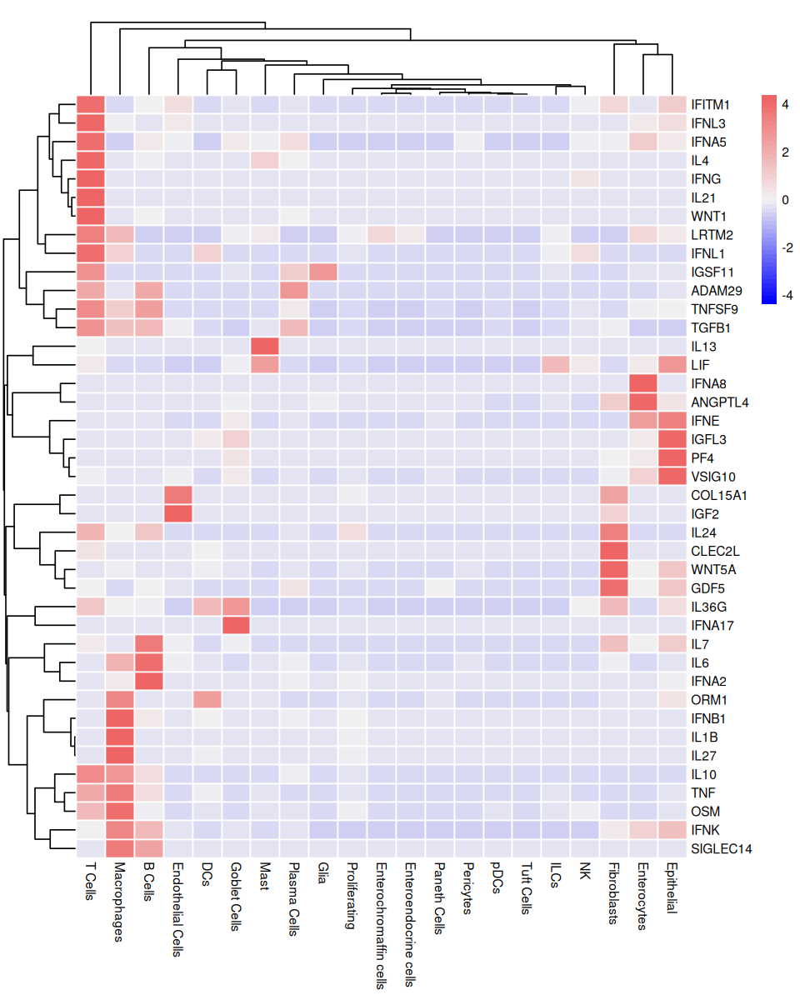

In [143]:
options(repr.plot.width = 8, repr.plot.height = 10)

pheatmap::pheatmap(mtx, main = "", 
         scale = "row", cluster_cols = T, cluster_rows = T,
        color=colorRampPalette(c("blue", "grey95", "indianred2"))(50), 
         border_color = "white",
                  fontsize = 9, 
                  width = 8, height = 3.5)

In [ ]:
options(repr.plot.width = 8, repr.plot.height = 3.5)
pheatmap::pheatmap(t(meta_aggexp_5p$RNA)[c(6,1,8,4,3,2,5,7),], main = "", 
         scale = "column", cluster_cols = T, cluster_rows = F,
        color=colorRampPalette(c("blue", "grey95", "indianred2"))(50), 
         border_color = "white",
                  fontsize = 9, 
                  width = 8, height = 3.5,
                  filename = "figures/ligand_receptor/predict5p_ligand_expression_heatmap.pdf")

In [148]:
saveRDS(seu_ile_lp_filt, "data/seu_ile_lp_filt.rds")

In [2]:
seu_ile_lp_filt  <- readRDS("../241201_VN_PREDICT2/data/seu_ile_lp_filt.rds")

In [151]:
saveRDS(aggexp_5p, "data/seu_ile_lp_filt_aggexp_5p.rds")